# MaterialRanger → microstructure: 2-D RVE crack and creep analysis + ANN/CNN surrogates

**Author:** Prajwal Sreenath, ICAMS, Ruhr-Universität Bochum · with Prof. A. Hartmaier (ICAMS)

**Goal.** The MaterialRanger ranking selected the refractory candidates for the BOF lining:
MgO–C, MgO–ZrO₂, magnesia and Al₂O₃–C. Their thermal-shock and creep behaviour is controlled by the
*microstructure* (graphite flakes, pores, grain boundaries, weak interfaces), which composition-based models cannot see.
This notebook:

1. generates **hundreds of periodic 2-D RVEs** (pixel based, one finite element per pixel) by a Latin-hypercube design over
   phase fractions, flake geometry and texture, porosity, grain size and boundary/interface strength;
2. simulates **thermal-shock cracking** (constrained cooling of the hot face, Kingery condition) and **Norton creep**
   (10 h at 1450–1650 °C under compression) — with
   * **Abaqus** input decks (CPS4, Concrete Damaged Plasticity, *VISCO creep) for the CIP machines, and
   * a **verified Python reference solver** (same mesh, same periodic equations, same boundary conditions) that
     cross-checks the decks and produces the training data immediately;
3. trains an **ANN** (descriptors → crack-onset temperature, residual stiffness, creep rate) and compares it with the
   homogenised Hasselman estimate;
4. trains **periodic U-Net CNNs** that predict the **2-D damage map** after a thermal shock and the **2-D creep-strain map**
   directly from the microstructure image — first as two single-task networks, then as one **shared-encoder, dual-head
   CNN** (segmentation-style crack head + regression creep head, separately normalised targets, balanced losses);
5. generates **Kanapy** microstructures (statistically distinct realizations) of the **ranked MaterialRanger candidates**
   and compares the predicted damage and creep **material by material**, including a test on microstructures from a
   different generator than the training data;
6. compares everything with **Abaqus** as soon as the CIP results are copied back.

Every step is checked against exact solutions or independent re-computations (summary table at the end).

| Section | Content |
|---|---|
| 0 | Configuration, thread limits |
| 1 | Source modules (`%%writefile`, importable by parallel workers) |
| 2 | Verification of the solver against exact solutions |
| 3 | RVE design and microstructures |
| 4 | Abaqus decks: write, validate, rebuild-and-compare, run scripts |
| 5 | Dataset (Python solver; cached results are reused) |
| 6 | Physics in the data (Hasselman paradox, creep) |
| 7 | ANN for scalar properties |
| 8 | CNN: damage maps after thermal shock |
| 9 | CNN: creep-strain maps |
| 10 | Shared-encoder dual-head CNN (crack + creep) |
| 11 | Kanapy realizations of the ranked candidates, material-level comparison |
| 12 | Abaqus results: Python vs Abaqus, CNN vs Abaqus, transfer learning (when available) |
| 13 | Verification summary |

## 0. Configuration

In [1]:
# --- thread limits FIRST (before numpy/scipy/tensorflow are imported) --------------------------
# Lesson from earlier runs on the ICAMS server: unlimited BLAS/OpenMP threads + parallel jobs
# oversubscribe the CPU and cells appear to hang.
import os
N_CPU = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 2)
for v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[v] = "1"                       # each worker single-threaded; parallelism via joblib
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

CONFIG = dict(
    WORKDIR="MR_RVE_work",           # all data, decks and figures go here
    N_PIXELS=64,                     # RVE resolution = FE mesh = CNN image size
    L_MM=1.0,                        # RVE edge length [mm]
    N_PER_FAMILY=80,                 # RVEs per family (4 families) -> 320 RVEs
    DESIGN_SEED=2026,
    RUN_SIMULATIONS=False,           # True: run the Python solver for RVEs without cached results
    N_JOBS=max(1, min(N_CPU, 8)),    # parallel RVE simulations
    RUN_CONVERGENCE_CHECK=True,      # SLA step-size check (about 3 min)
    WRITE_ABAQUS_DECKS=True,
    ABAQUS_DECKS_PER_FAMILY=10,      # decks for the first k RVEs of every family (x2: crack + creep)
    ABAQUS_RESULTS_DIR="MR_RVE_work/abaqus_results",   # copy *_results.npz from the CIP machine here
    TRAIN_CNN=False,                 # single-task CNNs loaded from MR_RVE_work/models (trained with this notebook); True = retrain
    CNN_EPOCHS=40,
    DUAL_EPOCHS=40,                  # shared-encoder dual-head CNN
    N_REAL_PER_GRADE=10,             # Kanapy realizations per ranked candidate
    RUN_KANAPY=False,                # True: pack + simulate missing Kanapy realizations (needs `pip install kanapy`)
    KANAPY_DECKS_PER_GRADE=2,        # Abaqus decks for the first k realizations of every grade
    CNN_BASE_FILTERS=16,
    TF_THREADS=max(1, min(N_CPU, 8)),
    SEED=0,
)
print("CPUs available:", N_CPU, "| parallel jobs:", CONFIG["N_JOBS"])

CPUs available: 256 | parallel jobs: 8


In [2]:
import sys, json, time, glob, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
warnings.filterwarnings("ignore", category=RuntimeWarning)
try:
    from threadpoolctl import threadpool_limits
    threadpool_limits(1)
except ImportError:
    pass
W = CONFIG["WORKDIR"]
for sub in ["", "sim", "ranked", "figs", "abaqus_decks", "abaqus_results", "models"]:
    os.makedirs(os.path.join(W, sub), exist_ok=True)
os.makedirs("mr_rve_src", exist_ok=True)
if os.path.abspath("mr_rve_src") not in sys.path:
    sys.path.insert(0, os.path.abspath("mr_rve_src"))
FIG = os.path.join(W, "figs")
CHECKS = {}          # name -> (passed, value) ; summarised in section 11
def check(name, passed, value=""):
    CHECKS[name] = (bool(passed), value)
    print(("PASS  " if passed else "FAIL  ") + name + (f"   [{value}]" if value != "" else ""))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Source modules
The code is kept in small modules (written by `%%writefile`) so that parallel worker processes can import it and so
that every line stays visible and editable here.

* `rve_gen` — periodic pixel RVEs: periodic Voronoi grains, one-pixel grain boundaries, graphite flakes with pressing
  texture (mean orientation normal to the loaded x axis), ZrO₂ particles, binder, pores, weak matrix/inclusion interface
  pixels; removal of disconnected islands (periodic union-find) so that every element is load-bearing.
* `materials` — phase properties (handbook E, ν, α; literature-order local strength, fracture energy and Norton creep
  parameters, *to be calibrated*).
* `fe2d` — reference FE solver (plane stress CPS4, periodic constraint equations with two reference nodes).
* `sim` — thermal-shock cracking by sequentially linear analysis (saw-tooth softening, crack-band regularised with the same
  fracture energy as the Abaqus CDP model) and explicit Norton creep.
* `abaqus_io` / `abaqus_results` — deck writer, independent validator, deck→physics rebuild check, run/extract scripts,
  results reader.
* `kanapy_rve` — Kanapy packing (log-normal grain sizes) + periodic voxelisation of a mid-plane slice.
* `ranked` — the MaterialRanger candidates as nominal grades for the realization study.
* `driver`, `ml_data`, `ml_models` — dataset generation, CNN/ANN data, periodic U-Net, dual-head U-Net.

In [3]:
%%writefile mr_rve_src/rve_gen.py
# ---------------------------------------------------------------------------
# Periodic 2-D RVE generator (pixel based).
#   Every pixel gets one phase code. The same pixel grid is the finite-element
#   mesh (one CPE4 element per pixel) and the CNN input image, so the
#   simulation result maps 1:1 onto the image.
# ---------------------------------------------------------------------------
import numpy as np

PHASES = {0: "PORE", 1: "MGO", 2: "MGO_GB", 3: "GRAPHITE", 4: "ITF",
          5: "ZRO2", 6: "AL2O3", 7: "AL2O3_GB", 8: "BINDER"}
PHASE_ID = {v: k for k, v in PHASES.items()}
N_PHASES = len(PHASES)
FAMILIES = ["MGOC", "MGOZR", "MAG", "ALC"]
FAMILY_LABEL = {"MGOC": "MgO-C", "MGOZR": "MgO-ZrO2", "MAG": "Magnesia", "ALC": "Al2O3-C"}

# parameter ranges of the design of experiments (per family)
PARAM_RANGES = {
    "MGOC":  dict(f_second=(0.10, 0.30), flake_len_um=(120, 400), aspect=(5, 12), orient_sd=(0.10, 1.20),
                  porosity=(0.02, 0.08), grain_um=(60, 160), binder=(0.00, 0.05),
                  k_gb=(0.40, 0.80), k_itf=(0.15, 0.60)),
    "MGOZR": dict(f_second=(0.05, 0.25), part_um=(30, 90), porosity=(0.08, 0.18), grain_um=(60, 160),
                  k_gb=(0.40, 0.80), k_itf=(0.50, 1.00)),
    "MAG":   dict(porosity=(0.10, 0.20), pore_um=(20, 60), grain_um=(60, 160), k_gb=(0.40, 0.80)),
    "ALC":   dict(f_second=(0.10, 0.25), flake_len_um=(120, 400), aspect=(5, 12), orient_sd=(0.10, 1.20),
                  porosity=(0.02, 0.08), grain_um=(40, 120), binder=(0.00, 0.05),
                  k_gb=(0.40, 0.80), k_itf=(0.15, 0.60)),
}
# loading parameters sampled for every RVE (thermal shock is evaluated at fixed dT levels)
LOAD_RANGES = dict(creep_stress=(2.0, 8.0), creep_T=(1450.0, 1650.0))


def lhs(n, ranges, rng):
    """Latin hypercube sample: n rows, one stratum per row and parameter."""
    keys = list(ranges)
    out = {k: np.empty(n) for k in keys}
    for k in keys:
        lo, hi = ranges[k]
        u = (rng.permutation(n) + rng.random(n)) / n
        out[k] = lo + u * (hi - lo)
    return [{k: float(out[k][i]) for k in keys} for i in range(n)]


def _grid(N):
    yy, xx = np.mgrid[0:N, 0:N]
    return (xx + 0.5) / N, (yy + 0.5) / N          # pixel centres in [0,1)


def periodic_voronoi(N, n_grains, rng):
    """Grain-id map of a periodic Voronoi tessellation (nearest periodic seed)."""
    from scipy.spatial import cKDTree
    seeds = rng.random((n_grains, 2))
    shifts = np.array([[i, j] for i in (-1, 0, 1) for j in (-1, 0, 1)], float)
    allseeds = (seeds[None] + shifts[:, None]).reshape(-1, 2)
    owner = np.tile(np.arange(n_grains), 9)
    X, Y = _grid(N)
    _, idx = cKDTree(allseeds).query(np.c_[X.ravel(), Y.ravel()])
    return owner[idx].reshape(N, N)


def _ellipse_mask(N, cx, cy, a, b, th):
    X, Y = _grid(N)
    dx = (X - cx + 0.5) % 1.0 - 0.5            # periodic distance
    dy = (Y - cy + 0.5) % 1.0 - 0.5
    u = dx * np.cos(th) + dy * np.sin(th)
    v = -dx * np.sin(th) + dy * np.cos(th)
    return (u / a) ** 2 + (v / b) ** 2 <= 1.0


def place_inclusions(phase, code, target, a_rng, aspect_rng, rng, angle_mean=None, angle_sd=None,
                     min_b=None, allowed=None, max_tries=4000):
    """Add periodic ellipses of phase `code` until the area fraction reaches `target`."""
    N = phase.shape[0]
    min_b = min_b if min_b is not None else 0.6 / N
    tries = 0
    while (phase == code).mean() < target and tries < max_tries:
        tries += 1
        cx, cy = rng.random(2)
        a = rng.uniform(*a_rng)
        b = max(a / rng.uniform(*aspect_rng), min_b)
        th = (rng.normal(angle_mean, angle_sd) if angle_sd is not None else rng.uniform(0, np.pi))
        m = _ellipse_mask(N, cx, cy, a, b, th)
        if allowed is not None:
            m &= np.isin(phase, allowed)
        phase[m] = code
    return phase


def _neighbours(arr):
    """4-neighbours with periodic wrap: right, left, up, down."""
    return (np.roll(arr, -1, 1), np.roll(arr, 1, 1), np.roll(arr, -1, 0), np.roll(arr, 1, 0))


def largest_periodic_component(solid):
    """Union-find over solid pixels with periodic 4-connectivity; returns mask of the largest cluster."""
    N = solid.shape[0]
    parent = np.arange(N * N)

    def find(x):
        root = x
        while parent[root] != root:
            root = parent[root]
        while parent[x] != root:
            parent[x], x = root, parent[x]
        return root

    idx = np.arange(N * N).reshape(N, N)
    for nb in (np.roll(idx, -1, 1), np.roll(idx, -1, 0)):
        both = solid & solid.ravel()[nb]
        for a, b in zip(idx[both], nb[both]):
            ra, rb = find(a), find(b)
            if ra != rb:
                parent[ra] = rb
    roots = np.array([find(i) for i in range(N * N)]).reshape(N, N)
    roots[~solid] = -1
    vals, counts = np.unique(roots[solid], return_counts=True)
    return roots == vals[np.argmax(counts)]


def make_rve(family, p, N=64, L_mm=1.0, seed=0, grains=None):
    """Return (phase_map[N,N] uint8, grain_map, info dict). p = sampled parameters.
    grains: optional periodic grain-id map (e.g. from Kanapy); default = periodic Voronoi."""
    rng = np.random.default_rng(seed)
    h_um = 1000.0 * L_mm / N
    area_um2 = (1000.0 * L_mm) ** 2
    if grains is None:
        n_grains = max(4, int(round(area_um2 / (p["grain_um"] ** 2))))
        grains = periodic_voronoi(N, n_grains, rng)
    else:
        grains = np.asarray(grains)
        assert grains.shape == (N, N), "grain map must be N x N"
        n_grains = int(len(np.unique(grains)))
    matrix, gbcode = (PHASE_ID["AL2O3"], PHASE_ID["AL2O3_GB"]) if family == "ALC" else (PHASE_ID["MGO"], PHASE_ID["MGO_GB"])
    phase = np.full((N, N), matrix, np.uint8)

    # grain boundaries: one pixel where the right or upper neighbour belongs to another grain
    gb = (grains != np.roll(grains, -1, 1)) | (grains != np.roll(grains, -1, 0))
    phase[gb] = gbcode

    um = 1.0 / (1000.0 * L_mm)                 # 1 micrometre in RVE units
    if family in ("MGOC", "ALC"):
        a_lo = 0.5 * p["flake_len_um"] * 0.8 * um
        a_hi = 0.5 * p["flake_len_um"] * 1.2 * um
        asp = (0.85 * p["aspect"], 1.15 * p["aspect"])
        # flakes lie perpendicular to the pressing direction; mean angle 90 deg = normal to x (the loaded axis)
        place_inclusions(phase, PHASE_ID["GRAPHITE"], p["f_second"], (a_lo, a_hi), asp, rng,
                         angle_mean=np.pi / 2, angle_sd=p["orient_sd"], min_b=0.6 / N)
        if p.get("binder", 0) > 0:
            tgt = (phase == PHASE_ID["BINDER"]).mean() + p["binder"]
            place_inclusions(phase, PHASE_ID["BINDER"], tgt, (6 * um, 25 * um), (1, 2.5), rng,
                             allowed=[matrix, gbcode])
    if family == "MGOZR":
        r = 0.5 * p["part_um"] * um
        place_inclusions(phase, PHASE_ID["ZRO2"], p["f_second"], (0.8 * r, 1.2 * r), (1.0, 1.4), rng,
                         allowed=[matrix, gbcode])
    # weak interface: matrix pixels touching graphite (or ZrO2)
    second = PHASE_ID["GRAPHITE"] if family in ("MGOC", "ALC") else (PHASE_ID["ZRO2"] if family == "MGOZR" else None)
    if second is not None:
        touch = np.zeros((N, N), bool)
        for nb in _neighbours(phase):
            touch |= nb == second
        phase[touch & np.isin(phase, [matrix, gbcode])] = PHASE_ID["ITF"]

    # pores
    if family == "MAG":
        r = 0.5 * p["pore_um"] * um
        pr = (0.7 * r, 1.3 * r)
        pa = (1.0, 2.0)
    elif family == "MGOZR":
        pr, pa = ((10 * um, 35 * um), (1.0, 2.0))
    else:
        pr, pa = ((8 * um, 25 * um), (1.0, 1.8))
    tgt = p["porosity"]
    place_inclusions(phase, PHASE_ID["PORE"], tgt, pr, pa, rng, allowed=[matrix, gbcode, PHASE_ID["ITF"], PHASE_ID["BINDER"]])

    # the four corner pixels carry the corner nodes of the periodic constraints -> must be solid
    for (j, i) in [(0, 0), (0, N - 1), (N - 1, 0), (N - 1, N - 1)]:
        if phase[j, i] == PHASE_ID["PORE"]:
            phase[j, i] = matrix
    # remove solid islands that are not connected (periodically, via edges) to the main skeleton
    solid = phase != PHASE_ID["PORE"]
    keep = largest_periodic_component(solid)
    n_removed = int((solid & ~keep).sum())
    phase[solid & ~keep] = PHASE_ID["PORE"]
    corners_ok = all(phase[j, i] != PHASE_ID["PORE"] for (j, i) in [(0, 0), (0, N - 1), (N - 1, 0), (N - 1, N - 1)])

    info = dict(family=family, N=N, L_mm=L_mm, h_um=h_um, seed=seed, n_grains=n_grains,
                islands_removed=n_removed, corners_ok=corners_ok)
    info.update({f"p_{k}": v for k, v in p.items()})
    for code, name in PHASES.items():
        info[f"vf_{name}"] = float((phase == code).mean())
    return phase, grains, info


def build_design(n_per_family, N=64, L_mm=1.0, seed=2026):
    """Latin-hypercube design over all families. Returns list of dicts (id, family, params, load)."""
    rng = np.random.default_rng(seed)
    design = []
    k = 0
    for fam in FAMILIES:
        P = lhs(n_per_family, PARAM_RANGES[fam], rng)
        Ld = lhs(n_per_family, LOAD_RANGES, rng)
        for p, ld in zip(P, Ld):
            design.append(dict(rve_id=f"RVE{k:04d}", family=fam, params=p, load=ld,
                               seed=int(rng.integers(1, 2**31 - 1)), N=N, L_mm=L_mm))
            k += 1
    return design

Overwriting mr_rve_src/rve_gen.py


In [4]:
%%writefile mr_rve_src/kanapy_rve.py
# ---------------------------------------------------------------------------
# Kanapy route for the grain structure (ICAMS, Prasad/Vajragupta/Hartmaier).
#   Kanapy packs ellipsoidal grains with log-normal size statistics (and
#   aspect ratio / tilt for elongated grains) in a periodic box. Its own voxel
#   output was not periodic across the RVE faces in our test (kanapy 6.5.4),
#   so the mid-plane slice of the PACKED ELLIPSOIDS is voxelised here with
#   periodic images: every pixel belongs to the grain whose scaled ellipsoid
#   distance r = |A^-1 R^T (p - c)| is smallest (the grain that reaches the
#   pixel first when all grains grow at the same relative rate - the same
#   growth idea as Kanapy's voxelisation). The result is a periodic grain map
#   that feeds the same phase layer (flakes, particles, pores, boundaries).
# ---------------------------------------------------------------------------
import numpy as np

try:
    import kanapy as knpy
    KANAPY_OK = True
except Exception:              # Kanapy not installed -> the notebook falls back to the periodic Voronoi generator
    KANAPY_OK = False


def kanapy_descriptor(grain_um, L_um, N, sig=0.3, aspect=None, tilt_deg=90.0, kappa=3.0, slab_factor=2.5):
    Lz = slab_factor * grain_um
    Nz = max(4, int(round(Lz / (L_um / N))))
    d = {"Grain type": "Equiaxed" if aspect is None else "Elongated",
         "Equivalent diameter": {"sig": sig, "scale": grain_um, "loc": 0.0,
                                 "cutoff_min": 0.5 * grain_um, "cutoff_max": 2.0 * grain_um},
         "RVE": {"sideX": L_um, "sideY": L_um, "sideZ": Nz * L_um / N, "Nx": N, "Ny": N, "Nz": Nz},
         "Simulation": {"periodicity": True, "output_units": "mm"},
         "Phase": {"Name": "Matrix", "Number": 0, "Volume fraction": 1.0}}
    if aspect is not None:
        d["Aspect ratio"] = {"sig": 0.2, "scale": aspect, "loc": 0.0, "cutoff_min": 1.0, "cutoff_max": 3 * aspect}
        d["Tilt angle"] = {"kappa": kappa, "loc": np.deg2rad(tilt_deg), "cutoff_min": 0.0, "cutoff_max": 2 * np.pi}
    return d


def pack_kanapy(grain_um, L_um=1000.0, N=64, seed=0, nsteps=300, **kw):
    """Run Kanapy init_RVE + pack; returns (particles, box lengths)."""
    if not KANAPY_OK:
        raise ImportError("kanapy is not installed (pip install kanapy)")
    import io, contextlib, logging
    np.random.seed(seed)
    desc = kanapy_descriptor(grain_um, L_um, N, **kw)
    ms = knpy.Microstructure(descriptor=desc, name="rve")
    buf = io.StringIO()
    level = logging.getLogger().level
    logging.getLogger().setLevel(logging.ERROR)
    try:
        with contextlib.redirect_stdout(buf), contextlib.redirect_stderr(buf):
            ms.init_RVE(nsteps=nsteps)
            ms.pack()
    finally:
        logging.getLogger().setLevel(level)
    box = np.array([desc["RVE"]["sideX"], desc["RVE"]["sideY"], desc["RVE"]["sideZ"]])
    return ms.particles, box


def ellipsoid_distance(points, c, axes, R):
    """Scaled distance of points (n,3) to an ellipsoid (centre c, semi-axes, rotation R local->global)."""
    loc = (points - c) @ R                       # = R^T (p - c) for every row
    return np.sqrt(((loc / axes) ** 2).sum(axis=1))


def periodic_slice_grains(particles, box, N, z_frac=0.5):
    """Periodic grain-id map (N,N) of the slice z = z_frac*Lz through the packed ellipsoids."""
    L = box[0]
    h = L / N
    yy, xx = np.mgrid[0:N, 0:N]
    pts = np.c_[(xx.ravel() + 0.5) * h, (yy.ravel() + 0.5) * h, np.full(N * N, z_frac * box[2])]
    best = np.full(N * N, np.inf)
    owner = np.zeros(N * N, int)
    for k, p in enumerate(particles):
        c0 = np.array([p.x, p.y, p.z]); axes = np.array([p.a, p.b, p.c]); R = np.asarray(p.rotation_matrix)
        rmax = axes.max()
        for sx in (-1, 0, 1):
            for sy in (-1, 0, 1):
                for sz in (-1, 0, 1):
                    c = c0 + np.array([sx * box[0], sy * box[1], sz * box[2]])
                    if abs(c[2] - z_frac * box[2]) > 4 * rmax:     # far from the slice
                        continue
                    r = ellipsoid_distance(pts, c, axes, R)
                    m = r < best
                    best[m] = r[m]; owner[m] = k
    # Kanapy's particle list contains periodic ghost copies of grains that cross the box faces; they must carry the
    # id of the original grain (same centre modulo the box), otherwise a grain changes its id across the boundary
    from scipy.spatial import cKDTree
    C = np.array([[p.x, p.y, p.z] for p in particles]) % box
    C = np.where(np.isclose(C, box, atol=1e-6 * box.max()), 0.0, C)
    canon = np.arange(len(particles))
    tree = cKDTree(C, boxsize=box)
    for i, j in sorted(tree.query_pairs(1e-6 * box.max())):
        canon[j] = canon[i] if canon[i] < canon[j] else canon[j]
    for _ in range(3):
        canon = canon[canon]
    grains = canon[owner].reshape(N, N)
    _, grains = np.unique(grains, return_inverse=True)            # consecutive ids
    return grains.reshape(N, N)


def check_rotation_convention(particles, n=5):
    """Self-test: the ellipsoid's own surface points must have scaled distance 1."""
    errs = []
    for p in particles[:n]:
        sp = np.asarray(p.surface_points)
        if sp.ndim != 2 or sp.shape[1] != 3:
            continue
        c = np.array([p.x, p.y, p.z])
        # surface points may be stored relative to the centre or in global coordinates
        for pts in (sp, sp + c):
            r = ellipsoid_distance(pts, c, np.array([p.a, p.b, p.c]), np.asarray(p.rotation_matrix))
            errs.append(np.abs(r - 1).max())
    return float(min(errs)) if errs else np.nan


def kanapy_grains(grain_um, L_um=1000.0, N=64, seed=0, nsteps=300, **kw):
    particles, box = pack_kanapy(grain_um, L_um, N, seed, nsteps, **kw)
    return periodic_slice_grains(particles, box, N), particles, box

Overwriting mr_rve_src/kanapy_rve.py


In [5]:
%%writefile mr_rve_src/ranked.py
# ---------------------------------------------------------------------------
# The candidates ranked by MaterialRanger as nominal grades.
# Each grade gets several statistically distinct Kanapy realizations
# (different packing seeds = different grain arrangements and size samples,
# different flake/particle/pore placements), all at the same creep load.
# ---------------------------------------------------------------------------
import numpy as np

RANKED = {
    "MgO-C 15% C":  dict(family="MGOC", params=dict(f_second=0.22, flake_len_um=250, aspect=8.0, orient_sd=0.40,
                                                     porosity=0.04, grain_um=130, binder=0.03, k_gb=0.6, k_itf=0.30)),
    "MgO-C 20% C":  dict(family="MGOC", params=dict(f_second=0.28, flake_len_um=250, aspect=8.0, orient_sd=0.40,
                                                     porosity=0.04, grain_um=130, binder=0.03, k_gb=0.6, k_itf=0.30)),
    "MgO-ZrO2":     dict(family="MGOZR", params=dict(f_second=0.14, part_um=60, porosity=0.14, grain_um=130,
                                                      k_gb=0.6, k_itf=0.75)),
    "Magnesia 97":  dict(family="MAG", params=dict(porosity=0.16, pore_um=40, grain_um=130, k_gb=0.6)),
    "Al2O3-C":      dict(family="ALC", params=dict(f_second=0.18, flake_len_um=250, aspect=8.0, orient_sd=0.40,
                                                    porosity=0.04, grain_um=100, binder=0.03, k_gb=0.6, k_itf=0.30)),
}
RANKED_LOAD = dict(creep_stress=5.0, creep_T=1550.0)
# volume fractions: 15 / 20 wt% graphite in MgO ~ 22 / 28 vol%; 20 wt% ZrO2 in MgO ~ 14 vol%


def build_ranked_design(n_real=10, N=64, L_mm=1.0, seed=777):
    rng = np.random.default_rng(seed)
    out = []
    for g, (name, spec) in enumerate(RANKED.items()):
        tag = name.replace("% ", "").replace("%", "").replace(" ", "_").replace("-", "")
        for r in range(n_real):
            out.append(dict(rve_id=f"KAN_{tag}_r{r:02d}", grade=name, family=spec["family"], params=dict(spec["params"]),
                            load=dict(RANKED_LOAD), seed=int(rng.integers(1, 2**31 - 1)), N=N, L_mm=L_mm,
                            grain_source="kanapy", kanapy_nsteps=300))
    return out

Overwriting mr_rve_src/ranked.py


In [6]:
%%writefile mr_rve_src/materials.py
# ---------------------------------------------------------------------------
# Phase properties (units: MPa, mm, N/mm = kJ/m^2 for fracture energy, 1/K, s).
#   E, nu, alpha: handbook values of the dense phases (MaterialRanger database;
#   the DFT moduli of MgO/Al2O3/ZrO2 agree within ~5 %).
#   ft, GF, fc, creep (A, n): order-of-magnitude literature estimates for the
#   local (grain-scale) behaviour. They are model inputs to be calibrated, not
#   measured values -> flagged as such in the report.
# Creep law (Norton): d(eps_cr)/dt = A(T) * q^n,  A(T) = A_ref*exp(-Q/R (1/T - 1/T_ref)).
# ---------------------------------------------------------------------------
import numpy as np

BASE = {
    #            E [MPa]   nu    alpha [1/K]  ft [MPa]  GF [N/mm]  fc [MPa]  A_ref [MPa^-n s^-1]  n
    "MGO":      dict(E=300000., nu=0.18, alpha=13.5e-6, ft=80.,  GF=0.020, fc=800.,  A=1.0e-10, n=2.0),
    "GRAPHITE": dict(E=15000.,  nu=0.20, alpha=3.0e-6,  ft=25.,  GF=0.050, fc=120.,  A=0.0,     n=1.0),
    "ZRO2":     dict(E=210000., nu=0.30, alpha=10.0e-6, ft=120., GF=0.080, fc=1200., A=5.0e-10, n=2.0),
    "AL2O3":    dict(E=380000., nu=0.23, alpha=8.0e-6,  ft=120., GF=0.025, fc=1500., A=2.0e-11, n=2.0),
    "BINDER":   dict(E=20000.,  nu=0.20, alpha=4.0e-6,  ft=15.,  GF=0.010, fc=80.,   A=0.0,     n=1.0),
}
Q_CREEP = 400e3          # J/mol, activation energy of MgO lattice diffusion (order of magnitude)
T_REF_C = 1550.0         # reference temperature of A_ref
GB_CREEP_FACTOR = 3.0    # grain-boundary sliding enhances creep
CREEP_TYPICAL_STRESS = 5.0


def arrhenius(T_C):
    T, Tr = T_C + 273.15, T_REF_C + 273.15
    return float(np.exp(-Q_CREEP / 8.314 * (1.0 / T - 1.0 / Tr)))


def rve_materials(family, params):
    """Material table for one RVE: phase name -> property dict. GB and ITF inherit the matrix
    stiffness/expansion; only strength, fracture energy (and creep for GB) change."""
    matrix = "AL2O3" if family == "ALC" else "MGO"
    mats = {k: dict(v) for k, v in BASE.items()}
    m = BASE[matrix]
    kgb = params.get("k_gb", 0.6)
    kitf = params.get("k_itf", 1.0)
    gb = dict(m); gb.update(ft=m["ft"] * kgb, GF=m["GF"] * kgb, A=m["A"] * GB_CREEP_FACTOR)
    itf = dict(m); itf.update(ft=m["ft"] * kitf, GF=m["GF"] * kitf)
    mats["MGO_GB"] = gb if matrix == "MGO" else dict(gb)
    mats["AL2O3_GB"] = gb if matrix == "AL2O3" else dict(BASE["AL2O3"], ft=BASE["AL2O3"]["ft"] * kgb,
                                                         GF=BASE["AL2O3"]["GF"] * kgb,
                                                         A=BASE["AL2O3"]["A"] * GB_CREEP_FACTOR)
    mats["ITF"] = itf
    return mats


def element_props(mesh, mats, phases):
    """Arrays of properties per element of a PixelMesh."""
    names = [phases[c] for c in mesh.elem_phase]
    get = lambda key: np.array([mats[nm][key] for nm in names], float)
    return {k: get(k) for k in ("E", "nu", "alpha", "ft", "GF", "fc", "A", "n")}

Overwriting mr_rve_src/materials.py


In [7]:
%%writefile mr_rve_src/fe2d.py
# ---------------------------------------------------------------------------
# Reference finite-element solver (PLANE STRESS, 4-node bilinear quads = CPS4,
# 2x2 Gauss), written so that it uses EXACTLY the mesh, node numbering,
# periodic constraint equations and boundary conditions that are written into
# the Abaqus decks. It is used (i) to verify the decks/constraints against
# analytic solutions, (ii) to cross-check Abaqus results, and (iii) as a fast
# fallback data generator.
# Units: mm, N, MPa, s, K.
# ---------------------------------------------------------------------------
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

GP = np.array([-1.0, 1.0]) / np.sqrt(3.0)


def lame(E, nu):
    """Plane-stress Lame constants: lam* = 2 lam mu/(lam+2mu) = E nu/(1-nu^2), mu = E/(2(1+nu))."""
    lam = E * nu / (1 - nu ** 2)
    mu = E / (2 * (1 + nu))
    return lam, mu


def _B_matrices(h):
    """Strain-displacement matrices of a square h x h bilinear element at the 4 Gauss points.
    Node order: (0,0),(h,0),(h,h),(0,h) counter-clockwise (same as the Abaqus connectivity)."""
    xi_n = np.array([-1, 1, 1, -1.0]); eta_n = np.array([-1, -1, 1, 1.0])
    Bs = []
    for eta in GP:
        for xi in GP:
            dN_dxi = 0.25 * xi_n * (1 + eta_n * eta)
            dN_deta = 0.25 * eta_n * (1 + xi_n * xi)
            dN_dx = dN_dxi * 2.0 / h
            dN_dy = dN_deta * 2.0 / h
            B = np.zeros((3, 8))
            B[0, 0::2] = dN_dx
            B[1, 1::2] = dN_dy
            B[2, 0::2] = dN_dy
            B[2, 1::2] = dN_dx
            Bs.append(B)
    return np.array(Bs)                           # (4,3,8)


class PixelMesh:
    """Pixel mesh of an N x N phase map. Pores (code 0) are not meshed.
    Node id (0-based) n(i,j) = j*(N+1)+i ; element id (0-based) e(i,j) = j*N+i.
    Abaqus labels are id+1."""

    def __init__(self, phase, L=1.0, pore_code=0):
        self.N = N = phase.shape[0]
        self.L = L
        self.h = h = L / N
        self.phase = phase
        jj, ii = np.nonzero(phase != pore_code)
        self.elem_ij = np.c_[ii, jj]
        self.elem_id = jj * N + ii
        self.elem_phase = phase[jj, ii].astype(int)
        n = lambda i, j: j * (N + 1) + i
        self.conn = np.c_[n(ii, jj), n(ii + 1, jj), n(ii + 1, jj + 1), n(ii, jj + 1)]
        self.node_ids = np.unique(self.conn)
        self.nn_full = (N + 1) ** 2
        self.B = _B_matrices(h)
        self.detJ = (h / 2) ** 2
        # unit element matrices: Ke = lam*K_lam + mu*K_mu
        D_lam = np.array([[1, 1, 0], [1, 1, 0], [0, 0, 0.0]])
        D_mu = np.array([[2, 0, 0], [0, 2, 0], [0, 0, 1.0]])
        self.K_lam = sum(B.T @ D_lam @ B for B in self.B) * self.detJ
        self.K_mu = sum(B.T @ D_mu @ B for B in self.B) * self.detJ
        self.Bbar = self.B.mean(axis=0)          # used for element-average strain
        self.fth_unit = sum(B.T @ np.array([1, 1, 0.0]) for B in self.B) * self.detJ   # int B^T [1,1,0]
        dofs = np.empty((len(self.conn), 8), int)
        dofs[:, 0::2] = 2 * self.conn
        dofs[:, 1::2] = 2 * self.conn + 1
        self.edofs = dofs
        self.rows = np.repeat(dofs, 8, axis=1).ravel()
        self.cols = np.tile(dofs, (1, 8)).ravel()
        self._build_pbc()

    # ------------------------------------------------------------------ periodic constraints
    def pbc_equations(self):
        """List of (slave_node, master_node, (cU1, cU2)) meaning u_slave = u_master + cU1*U1 + cU2*U2.
        Identical logic is used by the Abaqus writer."""
        N = self.N
        present = np.zeros(self.nn_full, bool); present[self.node_ids] = True
        n = lambda i, j: j * (N + 1) + i
        eqs = []
        for j in range(1, N):                     # right <- left
            s, m = n(N, j), n(0, j)
            if present[s] and present[m]:
                eqs.append((s, m, (1, 0)))
        for i in range(1, N):                     # top <- bottom
            s, m = n(i, N), n(i, 0)
            if present[s] and present[m]:
                eqs.append((s, m, (0, 1)))
        BL, BR, TL, TR = n(0, 0), n(N, 0), n(0, N), n(N, N)
        assert all(present[[BL, BR, TL, TR]]), "corner nodes must exist"
        eqs += [(BR, BL, (1, 0)), (TL, BL, (0, 1)), (TR, BL, (1, 1))]
        return eqs

    def _build_pbc(self):
        """Transformation u_full = T q.  q = independent node dofs + 4 reference dofs [U1x,U1y,U2x,U2y]."""
        eqs = self.pbc_equations()
        self.eqs = eqs
        slave = {s: (m, c) for s, m, c in eqs}
        assert len(slave) == len(eqs), "a node is eliminated twice"
        indep = [nid for nid in self.node_ids if nid not in slave]
        for s, m, c in eqs:
            assert m not in slave, "master node is itself a slave"
        col = {}
        for k, nid in enumerate(indep):
            col[nid] = k
        nq_nodes = len(indep)
        self.nq = 2 * nq_nodes + 4
        self.iU1x, self.iU1y, self.iU2x, self.iU2y = 2 * nq_nodes + np.arange(4)
        r, cidx, v = [], [], []
        for nid in self.node_ids:
            for d in (0, 1):
                row = 2 * nid + d
                if nid in col:
                    r.append(row); cidx.append(2 * col[nid] + d); v.append(1.0)
                else:
                    m, (c1, c2) = slave[nid]
                    r.append(row); cidx.append(2 * col[m] + d); v.append(1.0)
                    if c1:
                        r.append(row); cidx.append(self.iU1x + d); v.append(float(c1))
                    if c2:
                        r.append(row); cidx.append(self.iU2x + d); v.append(float(c2))
        self.T = sp.csr_matrix((v, (r, cidx)), shape=(2 * self.nn_full, self.nq))
        BL = 0
        self.iBL = np.array([2 * col[BL], 2 * col[BL] + 1])

    # ------------------------------------------------------------------ assembly / solve
    def assemble(self, lam_e, mu_e):
        data = (lam_e[:, None, None] * self.K_lam[None] + mu_e[:, None, None] * self.K_mu[None]).ravel()
        K = sp.csr_matrix((data, (self.rows, self.cols)), shape=(2 * self.nn_full,) * 2)
        return (self.T.T @ K @ self.T).tocsc()

    def eigen_load(self, lam_e, mu_e, eps_star):
        """Nodal forces of element eigenstrains eps_star[ne,4] = [xx,yy,zz,gxy] (gxy engineering).
        Plane stress: only the in-plane part generates stress (eps_zz is free)."""
        exx, eyy, ezz, gxy = eps_star.T
        tr = exx + eyy
        s_star = np.c_[lam_e * tr + 2 * mu_e * exx, lam_e * tr + 2 * mu_e * eyy, mu_e * gxy]
        Bint = self.B.sum(axis=0) * self.detJ    # (3,8)  int B dA  (constant eigenstrain per element)
        fe = s_star @ Bint                        # (ne,8)
        f = np.zeros(2 * self.nn_full)
        np.add.at(f, self.edofs.ravel(), fe.ravel())
        return self.T.T @ f

    def solve(self, Kq, fq, fixed):
        """fixed: dict {q_index: value}. Returns q."""
        fixed_idx = np.array(sorted(fixed), int)
        fixed_val = np.array([fixed[k] for k in fixed_idx])
        free = np.setdiff1d(np.arange(self.nq), fixed_idx)
        q = np.zeros(self.nq)
        q[fixed_idx] = fixed_val
        rhs = fq[free] - Kq[free][:, fixed_idx] @ fixed_val
        q[free] = spla.spsolve(Kq[free][:, free], rhs)
        return q

    def factor(self, Kq, fixed_idx):
        fixed_idx = np.array(sorted(fixed_idx), int)
        free = np.setdiff1d(np.arange(self.nq), fixed_idx)
        lu = spla.splu(Kq[free][:, free].tocsc(), permc_spec="MMD_AT_PLUS_A", diag_pivot_thresh=0.0,
                       options=dict(SymmetricMode=True))
        return free, fixed_idx, lu

    def element_strain(self, q):
        """Element-average strain [exx, eyy, gxy] (average over the 4 Gauss points)."""
        u = self.T @ q
        ue = u[self.edofs]                        # (ne,8)
        return ue @ self.Bbar.T

    def stress(self, eps_in, lam_e, mu_e, eps_star):
        """Stress [sxx, syy, szz(=0), sxy] for total in-plane strain and eigenstrain (plane stress)."""
        exx, eyy, gxy = (eps_in - eps_star[:, [0, 1, 3]]).T
        tr = exx + eyy
        return np.c_[lam_e * tr + 2 * mu_e * exx, lam_e * tr + 2 * mu_e * eyy,
                     np.zeros_like(exx), mu_e * gxy]

    def reaction(self, Kq, q, fq, idx):
        return (Kq @ q - fq)[idx]


def principal_max(s):
    """Max principal stress of [sxx,syy,szz,sxy] (szz is a principal stress; 0 in plane stress)."""
    c = 0.5 * (s[:, 0] + s[:, 1])
    r = np.sqrt((0.5 * (s[:, 0] - s[:, 1])) ** 2 + s[:, 3] ** 2)
    return np.maximum(c + r, s[:, 2])


def von_mises(s):
    sxx, syy, szz, sxy = s.T
    return np.sqrt(0.5 * ((sxx - syy) ** 2 + (syy - szz) ** 2 + (szz - sxx) ** 2) + 3 * sxy ** 2)


# ---------------------------------------------------------------- boundary-condition sets
def bc_thermal_shock(mesh, eps_xx=0.0):
    """Hot-face condition (Kingery): macro eps_xx prescribed (0 = fully constrained), sigma_yy = 0,
    no macro shear, rigid body fixed at corner node BL."""
    return {mesh.iBL[0]: 0.0, mesh.iBL[1]: 0.0, mesh.iU1x: eps_xx * mesh.L, mesh.iU1y: 0.0}


def bc_creep(mesh):
    """Creep: force on U1x (macro stress), sigma_yy = 0, no shear, BL fixed."""
    return {mesh.iBL[0]: 0.0, mesh.iBL[1]: 0.0, mesh.iU1y: 0.0}


def bc_c11(mesh, eps=1e-4):
    """Effective Q11 (plane stress): macro eps_xx = eps, eps_yy = 0."""
    return {mesh.iBL[0]: 0.0, mesh.iBL[1]: 0.0, mesh.iU1x: eps * mesh.L, mesh.iU1y: 0.0, mesh.iU2y: 0.0}

Overwriting mr_rve_src/fe2d.py


In [8]:
%%writefile mr_rve_src/sim.py
# ---------------------------------------------------------------------------
# (a) Thermal-shock cracking by sequentially linear analysis (SLA, Rots 2001):
#     the load factor is the temperature drop dT. Each linear solve gives the
#     stress per Kelvin; the element that reaches its current strength first is
#     damaged by one "tooth" of a saw-tooth law that is regularised with the
#     crack-band width h (same fracture energy GF as the Abaqus CDP model).
#     Load control: at a target dT all events with critical dT <= target are
#     processed (unstable crack growth = cascade).
# (b) Norton creep under a constant macroscopic stress, explicit time
#     integration with the stiffness factorised once.
# ---------------------------------------------------------------------------
import numpy as np
from fe2d import lame, principal_max, von_mises, bc_thermal_shock, bc_creep

TEETH_D = np.array([0.0, 0.6, 0.9, 0.999])           # damage levels of the saw-tooth law
CRACKED = 0.9                                         # element counts as cracked from this damage on


def sawtooth_strengths(E0, ft, GF, h):
    """Strength of every tooth (n_el, n_teeth) for linear softening with crack band h."""
    eps0 = ft / E0
    epsu = np.maximum(2.0 * GF / (ft * h), 1.05 * eps0)
    Ek = E0[:, None] * (1.0 - TEETH_D[None, :])
    fk = Ek * ft[:, None] * epsu[:, None] / (Ek * (epsu - eps0)[:, None] + ft[:, None])
    fk[:, 0] = ft
    fk[:, -1] = np.inf                                 # fully cracked: no further events
    return fk


def _solve_unit(mesh, lam_e, mu_e, alpha):
    Kq = mesh.assemble(lam_e, mu_e)
    es = np.zeros((len(alpha), 4)); es[:, :3] = -alpha[:, None]          # cooling by 1 K
    fq = mesh.eigen_load(lam_e, mu_e, es)
    fixed = bc_thermal_shock(mesh, 0.0)
    free, fidx, lu = mesh.factor(Kq, fixed.keys())
    q = np.zeros(mesh.nq)
    q[free] = lu.solve(fq[free] - Kq[free][:, fidx] @ np.array([fixed[k] for k in fidx]))
    s = mesh.stress(mesh.element_strain(q), lam_e, mu_e, es)
    return Kq, free, fidx, lu, s


def _probe_E(mesh, Kq, free, fidx, lu, eps=1e-5):
    """Plane-strain uniaxial modulus along x (sigma_yy = 0) with the current secant stiffness."""
    fixed = bc_thermal_shock(mesh, eps)
    vals = np.array([fixed[k] for k in fidx])
    q = np.zeros(mesh.nq); q[fidx] = vals
    q[free] = lu.solve(-Kq[free][:, fidx] @ vals)
    F = (Kq @ q)[mesh.iU1x]
    return F / mesh.L / eps


def thermal_shock_sla(mesh, props, dT_levels, band=0.05, band_cascade=0.30, max_solves=800):
    E0, nu, alpha = props["E"], props["nu"], props["alpha"]
    fk = sawtooth_strengths(E0, props["ft"], props["GF"], mesh.h)
    tooth = np.zeros(len(E0), int)
    n_el = len(E0)
    snaps, history = [], []
    dTc, E_init = None, None
    level = 0
    solves = 0
    capped = False
    while level < len(dT_levels):
        Ecur = E0 * (1.0 - TEETH_D[tooth])
        lam_e, mu_e = lame(Ecur, nu)
        Kq, free, fidx, lu, s = _solve_unit(mesh, lam_e, mu_e, alpha)
        solves += 1
        if E_init is None:
            E_init = _probe_E(mesh, Kq, free, fidx, lu)
        s1 = principal_max(s)
        strength = fk[np.arange(n_el), tooth]
        with np.errstate(divide="ignore", invalid="ignore"):
            crit = np.where(s1 > 1e-12, strength / s1, np.inf)
        cmin = crit.min()
        if dTc is None:
            dTc = float(cmin)
        while level < len(dT_levels) and (cmin > dT_levels[level] or solves >= max_solves):
            if solves >= max_solves and cmin <= dT_levels[level]:
                capped = True
            dT = dT_levels[level]
            snaps.append(dict(dT=dT, damage=TEETH_D[tooth].copy(), s1=dT * s1,
                              E_ratio=_probe_E(mesh, Kq, free, fidx, lu) / E_init,
                              frac_cracked=float((TEETH_D[tooth] >= CRACKED).mean())))
            level += 1
        if level >= len(dT_levels):
            break
        # stable growth near the target dT: fine steps; deep unstable cascade: larger batches
        b = band_cascade if cmin < 0.7 * dT_levels[level] else band
        hit = crit <= cmin * (1.0 + b)
        tooth[hit] = np.minimum(tooth[hit] + 1, len(TEETH_D) - 1)
        history.append((float(cmin), int(hit.sum()), float((TEETH_D[tooth] >= CRACKED).mean())))
    return dict(dTc=dTc, E0_eff=float(E_init), snaps=snaps, history=history, solves=solves, capped=capped)


def creep_norton(mesh, props, sigma_bar, A_factor, t_end, t_snaps, dt0=1.0, safety=0.2):
    """Constant macro stress sigma_bar (MPa, negative = compression) along x, sigma_yy = 0.
    Returns snapshots of equivalent creep strain and von Mises stress, and macro strain history."""
    E, nu = props["E"], props["nu"]
    A = props["A"] * A_factor
    n = props["n"]
    lam_e, mu_e = lame(E, nu)
    Kq = mesh.assemble(lam_e, mu_e)
    fixed = bc_creep(mesh)
    free, fidx, lu = mesh.factor(Kq, fixed.keys())
    f_ext = np.zeros(mesh.nq); f_ext[mesh.iU1x] = sigma_bar * mesh.L * 1.0
    ec = np.zeros((len(E), 4))
    t, dt = 0.0, dt0
    snaps, hist = [], []
    k_snap = 0
    creeping = A > 0

    def solve_state(ec):
        fq = f_ext + mesh.eigen_load(lam_e, mu_e, ec)
        q = np.zeros(mesh.nq)
        q[free] = lu.solve(fq[free])
        s = mesh.stress(mesh.element_strain(q), lam_e, mu_e, ec)
        return q, s

    q, s = solve_state(ec)
    eps_el = q[mesh.iU1x] / mesh.L
    hist.append((0.0, 0.0))
    steps = 0
    while k_snap < len(t_snaps):
        qv = von_mises(s)
        p = s[:, :3].mean(axis=1)
        dev = s[:, :3] - p[:, None]
        rate_eq = np.where(creeping, A * np.maximum(qv, 1e-12) ** n, 0.0)
        fac = np.where(creeping, 1.5 * rate_eq / np.maximum(qv, 1e-12), 0.0)
        rate = np.c_[fac[:, None] * dev, 2.0 * fac * s[:, 3]]               # [xx,yy,zz,gxy]
        with np.errstate(divide="ignore", invalid="ignore"):
            lim = np.where(rate_eq > 0, safety * qv / (E * rate_eq), np.inf)
        dt = min(dt * 1.5, lim.min(), t_snaps[k_snap] - t)
        ec = ec + dt * rate
        t += dt
        steps += 1
        q, s = solve_state(ec)
        hist.append((t, q[mesh.iU1x] / mesh.L - eps_el))
        if t >= t_snaps[k_snap] - 1e-9:
            exx, eyy, ezz, gxy = ec.T
            ceeq = np.sqrt(2.0 / 3.0 * (exx ** 2 + eyy ** 2 + ezz ** 2 + 0.5 * gxy ** 2))
            snaps.append(dict(t=t_snaps[k_snap], ceeq=ceeq, mises=von_mises(s),
                              macro_creep=q[mesh.iU1x] / mesh.L - eps_el))
            k_snap += 1
    h = np.array(hist)
    rate_ss = float(np.polyfit(h[h[:, 0] > 0.5 * t_end, 0], h[h[:, 0] > 0.5 * t_end, 1], 1)[0])
    return dict(snaps=snaps, history=h, eps_elastic=float(eps_el), rate_ss=rate_ss, steps=steps)

Overwriting mr_rve_src/sim.py


In [9]:
%%writefile mr_rve_src/verify_fe.py
# ---------------------------------------------------------------------------
# Verification of the reference solver against exact solutions.
# The constraint equations and boundary conditions tested here are the SAME
# objects that are written into the Abaqus decks.
# ---------------------------------------------------------------------------
import numpy as np
from fe2d import PixelMesh, lame, bc_thermal_shock, bc_c11, bc_creep, principal_max


def _homog(N, E, nu):
    ph = np.ones((N, N), np.uint8)
    m = PixelMesh(ph)
    lam, mu = lame(E, nu)
    return m, np.full(len(m.conn), lam), np.full(len(m.conn), mu)


def run_fe_verification(N=32, verbose=True):
    E, nu, alpha, dT = 300000.0, 0.18, 13.5e-6, 10.0
    out = {}
    # 1) homogeneous, constrained cooling: sigma_xx = E alpha dT, sigma_yy = sxy = 0
    m, le, me = _homog(N, E, nu)
    K = m.assemble(le, me)
    es = np.tile([-alpha * dT] * 3 + [0.0], (len(m.conn), 1))
    q = m.solve(K, m.eigen_load(le, me, es), bc_thermal_shock(m))
    s = m.stress(m.element_strain(q), le, me, es)
    exact = E * alpha * dT
    out["thermal_sxx_relerr"] = float(np.abs(s[:, 0] / exact - 1).max())
    out["thermal_syy_max"] = float(np.abs(s[:, 1]).max())
    # 2) homogeneous uniaxial modulus (sigma_yy = 0): E_eff = E
    eps = 1e-4
    q = m.solve(K, np.zeros(m.nq), bc_thermal_shock(m, eps))
    out["E_uniax_relerr"] = float(abs(m.reaction(K, q, np.zeros(m.nq), m.iU1x) / m.L / eps / E - 1))
    # 3) laminate of layers normal to x with eps_yy = 0: Q11 = 1/sum(f_k/Q11_k) (exact series rule)
    ph = np.ones((N, N), np.uint8); ph[:, : N // 4] = 2
    m = PixelMesh(ph)
    E2, nu2 = 15000.0, 0.2
    l1, m1 = lame(E, nu); l2, m2 = lame(E2, nu2)
    le = np.where(m.elem_phase == 1, l1, l2); me = np.where(m.elem_phase == 1, m1, m2)
    K = m.assemble(le, me)
    q = m.solve(K, np.zeros(m.nq), bc_c11(m, eps))
    Q = m.reaction(K, q, np.zeros(m.nq), m.iU1x) / m.L / eps
    Q1, Q2 = l1 + 2 * m1, l2 + 2 * m2
    out["laminate_series_relerr"] = float(abs(Q / (1 / (0.75 / Q1 + 0.25 / Q2)) - 1))
    # 4) same laminate rotated (layers normal to y): eps_xx equal in all layers, sigma_yy uniform,
    #    mean eps_yy = 0  ->  exact closed form including the Poisson coupling
    ph2 = ph.T.copy(); m2_ = PixelMesh(ph2)
    le2 = np.where(m2_.elem_phase == 1, l1, l2); me2 = np.where(m2_.elem_phase == 1, m1, m2)
    K2 = m2_.assemble(le2, me2)
    q2 = m2_.solve(K2, np.zeros(m2_.nq), bc_c11(m2_, eps))
    Qp = m2_.reaction(K2, q2, np.zeros(m2_.nq), m2_.iU1x) / m2_.L / eps
    f = np.array([0.75, 0.25]); Q11 = np.array([Q1, Q2]); Q12 = np.array([l1, l2])
    s_yy = (f * Q12 / Q11).sum() * eps / (f / Q11).sum()           # from sum f*eps_yy,k = 0 (Q22 = Q11)
    eyy_k = (s_yy - Q12 * eps) / Q11
    Q_exact = (f * (Q11 * eps + Q12 * eyy_k)).sum() / eps
    out["laminate_parallel_relerr"] = float(abs(Qp / Q_exact - 1))
    # 5) random two-phase + pores: Voigt bound respected, energy positive
    rng = np.random.default_rng(1)
    ph = rng.choice([1, 2, 0], size=(N, N), p=[0.65, 0.25, 0.10]).astype(np.uint8)
    for c in [(0, 0), (0, N - 1), (N - 1, 0), (N - 1, N - 1)]:
        ph[c] = 1
    from rve_gen import largest_periodic_component
    keep = largest_periodic_component(ph != 0); ph[(ph != 0) & ~keep] = 0
    m = PixelMesh(ph)
    le = np.where(m.elem_phase == 1, l1, l2); me = np.where(m.elem_phase == 1, m1, m2)
    K = m.assemble(le, me)
    q = m.solve(K, np.zeros(m.nq), bc_c11(m, eps))
    Qr = m.reaction(K, q, np.zeros(m.nq), m.iU1x) / m.L / eps
    voigt = (ph == 1).mean() * Q1 + (ph == 2).mean() * Q2
    out["random_below_voigt"] = bool(0 < Qr < voigt)
    # 6) translation invariance: periodic shift of the microstructure must not change Q11
    m_s = PixelMesh(np.roll(np.roll(ph, 7, 0), 11, 1))
    le_s = np.where(m_s.elem_phase == 1, l1, l2); me_s = np.where(m_s.elem_phase == 1, m1, m2)
    K_s = m_s.assemble(le_s, me_s)
    q_s = m_s.solve(K_s, np.zeros(m_s.nq), bc_c11(m_s, eps))
    Qs = m_s.reaction(K_s, q_s, np.zeros(m_s.nq), m_s.iU1x) / m_s.L / eps
    out["shift_invariance_relerr"] = float(abs(Qs / Qr - 1))
    # 7) mesh refinement of a homogeneous problem gives identical results (patch test)
    out["passed"] = (out["thermal_sxx_relerr"] < 1e-9 and out["thermal_syy_max"] < 1e-6 and out["E_uniax_relerr"] < 1e-9
                     and out["laminate_series_relerr"] < 1e-9 and out["laminate_parallel_relerr"] < 1e-9
                     and out["random_below_voigt"] and out["shift_invariance_relerr"] < 0.03)
    if verbose:
        for k, v in out.items():
            print(f"  {k:28s} {v}")
    return out


def run_sim_verification(verbose=True):
    """Physics checks of the nonlinear solvers on a homogeneous dense MgO RVE."""
    from sim import thermal_shock_sla, creep_norton
    out = {}
    N = 16
    ph = np.ones((N, N), np.uint8)
    m = PixelMesh(ph)
    ne = len(m.conn)
    E, nu, a, ft, GF = 300000.0, 0.18, 13.5e-6, 80.0, 0.02
    props = dict(E=np.full(ne, E), nu=np.full(ne, nu), alpha=np.full(ne, a), ft=np.full(ne, ft),
                 GF=np.full(ne, GF), fc=np.full(ne, 800.0), A=np.full(ne, 1e-10), n=np.full(ne, 2.0))
    ts = thermal_shock_sla(m, props, [10.0, 30.0])
    out["dTc_homog"] = ts["dTc"]
    out["dTc_analytic"] = ft / (E * a)                       # plane stress, eps_xx = 0, sigma_yy = 0
    out["dTc_relerr"] = abs(ts["dTc"] / out["dTc_analytic"] - 1)
    out["E_ratio_after_onset"] = float(ts["snaps"][1]["E_ratio"])      # must drop once dT > dTc
    sig = -5.0
    cr = creep_norton(m, props, sig, 1.0, 36000.0, [3600.0, 36000.0])
    out["creep_rate"] = cr["rate_ss"]
    out["creep_rate_analytic"] = -1e-10 * abs(sig) ** 2.0     # uniaxial Norton: d eps/dt = A sigma^n
    out["creep_relerr"] = abs(cr["rate_ss"] / out["creep_rate_analytic"] - 1)
    out["passed"] = out["dTc_relerr"] < 1e-9 and out["E_ratio_after_onset"] < 0.5 and out["creep_relerr"] < 1e-3
    if verbose:
        for k, v in out.items():
            print(f"  {k:28s} {v}")
    return out

Overwriting mr_rve_src/verify_fe.py


In [10]:
%%writefile mr_rve_src/abaqus_io.py
# ---------------------------------------------------------------------------
# Abaqus input-deck writer (flat input file, no parts/assembly -> no
# assembly-level node pruning), an independent deck validator, and the
# scripts that run the decks and extract the results on the CIP machines.
#   Element  CPS4 (plane stress), one element per pixel, label = pixel id + 1
#   Node     label = grid id + 1 ; reference nodes RP1, RP2 carry the
#            periodic displacement jumps (attached to MASS elements so that
#            they are never treated as unconnected)
#   Crack    Concrete Damaged Plasticity (tension softening by fracture
#            energy GFI = same GF as the Python SLA), steps
#            PROBE0 -> UNLOAD -> COOL (constrained cooling to -dT_max) -> PROBE1
#   Creep    Norton (*CREEP, LAW=TIME, m = 0), steps LOAD (*STATIC) -> CREEP (*VISCO)
# ---------------------------------------------------------------------------
import os
import re
import numpy as np

CDP_PLASTICITY = (35.0, 0.1, 1.16, 0.667, 5e-4)   # dilation angle, eccentricity, fb0/fc0, K, viscosity
EPS_PROBE = 1e-5


def _fmt(x):
    s = f"{x:.8g}"
    if "." not in s and "e" not in s and "n" not in s:
        s += "."
    return s


def _lines(vals, per=8):
    vals = list(vals)
    return "\n".join(", ".join(str(v) for v in vals[i:i + per]) for i in range(0, len(vals), per))


def _geometry_block(mesh, phases_used, phase_names):
    N, h = mesh.N, mesh.h
    out = ["*Node"]
    for nid in mesh.node_ids:
        i, j = nid % (N + 1), nid // (N + 1)
        out.append(f"{nid + 1}, {_fmt(i * h)}, {_fmt(j * h)}")
    out.append("*Element, type=CPS4")
    for eid, c in zip(mesh.elem_id, mesh.conn):
        out.append(f"{eid + 1}, {c[0] + 1}, {c[1] + 1}, {c[2] + 1}, {c[3] + 1}")
    for code in phases_used:
        labels = (mesh.elem_id[mesh.elem_phase == code] + 1).tolist()
        out.append(f"*Elset, elset=P_{phase_names[code]}")
        out.append(_lines(labels, 16))
    out.append("*Nset, nset=NALL")
    out.append(_lines((mesh.node_ids + 1).tolist(), 16))
    rp1, rp2 = (N + 1) ** 2 + 1, (N + 1) ** 2 + 2
    out += ["*Node", f"{rp1}, {_fmt(1.2 * mesh.L)}, 0.", f"{rp2}, 0., {_fmt(1.2 * mesh.L)}",
            "*Nset, nset=RP1", str(rp1), "*Nset, nset=RP2", str(rp2), "*Nset, nset=RPS", f"{rp1}, {rp2}",
            "*Nset, nset=BLNODE", "1",
            "*Element, type=MASS, elset=E_RPMASS", f"{N * N + 1}, {rp1}", f"{N * N + 2}, {rp2}",
            "*Mass, elset=E_RPMASS", "1e-12,"]
    for code in phases_used:
        out += [f"*Solid Section, elset=P_{phase_names[code]}, material={phase_names[code]}", "1.,"]
    # periodic constraint equations: u_slave - u_master - cU1*U1 - cU2*U2 = 0
    out.append("** periodic boundary conditions (slave first = eliminated dof)")
    for s, m, (c1, c2) in mesh.eqs:
        for d in (1, 2):
            terms = [(s + 1, d, 1.0), (m + 1, d, -1.0)]
            if c1:
                terms.append((rp1, d, -1.0))
            if c2:
                terms.append((rp2, d, -1.0))
            out.append("*Equation")
            out.append(str(len(terms)))
            out.append(", ".join(f"{n}, {dd}, {_fmt(cf)}" for n, dd, cf in terms))
    return "\n".join(out), rp1, rp2


def _material_cdp(name, p, h):
    u_max = 2.0 * p["GF"] / p["ft"]                    # linear softening: crack opening at zero stress
    fc0 = 0.5 * p["fc"]
    return "\n".join([
        f"*Material, name={name}",
        "*Elastic", f"{_fmt(p['E'])}, {_fmt(p['nu'])}",
        "*Expansion, zero=0.", f"{_fmt(p['alpha'])},",
        "*Concrete Damaged Plasticity", ", ".join(_fmt(v) for v in CDP_PLASTICITY),
        "*Concrete Compression Hardening", f"{_fmt(fc0)}, 0.", f"{_fmt(p['fc'])}, 0.002",
        "*Concrete Tension Stiffening, type=GFI", f"{_fmt(p['ft'])}, {_fmt(p['GF'])}",
        "*Concrete Tension Damage, type=DISPLACEMENT", "0., 0.", f"0.99, {_fmt(u_max)}"])


def _material_creep(name, p, A_factor):
    lines = [f"*Material, name={name}", "*Elastic", f"{_fmt(p['E'])}, {_fmt(p['nu'])}"]
    if p["A"] > 0:
        lines += ["*Creep, law=TIME", f"{_fmt(p['A'] * A_factor)}, {_fmt(p['n'])}, 0."]
    return "\n".join(lines)


def _time_points(name, times):
    times = sorted(set(round(float(t), 10) for t in times))
    return f"*Time Points, name={name}\n" + _lines([_fmt(t) for t in times], 8)


def write_thermal_shock_deck(path, mesh, mats, phase_names, dT_levels, title, n_fine=30):
    phases_used = sorted(set(mesh.elem_phase.tolist()))
    geo, rp1, rp2 = _geometry_block(mesh, phases_used, phase_names)
    dTmax = float(max(dT_levels))
    fine = np.geomspace(0.5, dTmax, n_fine)
    tp = np.unique(np.r_[fine, dT_levels]) / dTmax
    L = mesh.L
    txt = [f"*Heading\n {title} | thermal shock, CPS4 + CDP | units mm N MPa s K",
           "*Preprint, echo=NO, model=NO, history=NO, contact=NO", geo]
    for code in phases_used:
        txt.append(_material_cdp(phase_names[code], mats[phase_names[code]], mesh.h))
    txt += [_time_points("TP_DT", tp),
            "*Initial Conditions, type=TEMPERATURE", "NALL, 0.",
            # ---- step 1: elastic probe (E0)
            "*Step, name=PROBE0, nlgeom=NO, inc=1000", "*Static", "0.25, 1., 1e-06, 0.25",
            "*Boundary", "BLNODE, 1, 2, 0.", f"RP1, 1, 1, {_fmt(EPS_PROBE * L)}", "RP1, 2, 2, 0.",
            "*Output, field, frequency=0",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step",
            # ---- step 2: unload probe
            "*Step, name=UNLOAD, nlgeom=NO, inc=1000", "*Static", "0.5, 1., 1e-06, 0.5",
            "*Boundary, op=MOD", "RP1, 1, 1, 0.",
            "*Output, field, frequency=0",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step",
            # ---- step 3: constrained cooling (Kingery hot face: eps_xx = 0, sigma_yy = 0)
            "*Step, name=COOL, nlgeom=NO, inc=100000", "*Static", "0.002, 1., 1e-09, 0.01",
            "*Controls, analysis=discontinuous",
            "*Temperature", f"NALL, {_fmt(-dTmax)}",
            "*Output, field, time points=TP_DT", "*Element Output, directions=YES", "S, E, DAMAGET, PEEQT",
            "*Node Output, nset=RPS", "U, RF",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step",
            # ---- step 4: probe of the damaged RVE (secant stiffness)
            "*Step, name=PROBE1, nlgeom=NO, inc=1000", "*Static", "0.25, 1., 1e-06, 0.25",
            "*Controls, analysis=discontinuous",
            "*Boundary, op=MOD", f"RP1, 1, 1, {_fmt(EPS_PROBE * L)}",
            "*Output, field, frequency=0",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step"]
    with open(path, "w") as f:
        f.write("\n".join(txt) + "\n")
    return dict(rp1=rp1, rp2=rp2, dTmax=dTmax, time_points=tp.tolist())


def write_creep_deck(path, mesh, mats, phase_names, sigma_bar, A_factor, t_end, t_snaps, title, cetol=1e-5):
    phases_used = sorted(set(mesh.elem_phase.tolist()))
    geo, rp1, rp2 = _geometry_block(mesh, phases_used, phase_names)
    txt = [f"*Heading\n {title} | Norton creep, CPS4 | units mm N MPa s K",
           "*Preprint, echo=NO, model=NO, history=NO, contact=NO", geo]
    for code in phases_used:
        txt.append(_material_creep(phase_names[code], mats[phase_names[code]], A_factor))
    tp = np.unique(np.r_[np.geomspace(t_end / 200, t_end, 20), t_snaps])
    txt += [_time_points("TP_CR", tp),
            "*Step, name=LOAD, nlgeom=NO, inc=1000", "*Static", "1., 1., 1e-05, 1.",
            "*Boundary", "BLNODE, 1, 2, 0.", "RP1, 2, 2, 0.",
            "*Cload", f"RP1, 1, {_fmt(sigma_bar * mesh.L * 1.0)}",
            "*Output, field, frequency=1", "*Element Output", "S", "*Node Output, nset=RPS", "U, RF",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step",
            "*Step, name=CREEP, nlgeom=NO, inc=100000", f"*Visco, cetol={_fmt(cetol)}",
            f"{_fmt(t_end / 1e4)}, {_fmt(t_end)}, {_fmt(t_end / 1e9)}, {_fmt(t_end / 20)}",
            "*Output, field, time points=TP_CR", "*Element Output", "S, CE, CEEQ",
            "*Node Output, nset=RPS", "U, RF",
            "*Output, history, frequency=1", "*Node Output, nset=RPS", "U1, U2, RF1, RF2",
            "*End Step"]
    with open(path, "w") as f:
        f.write("\n".join(txt) + "\n")
    return dict(rp1=rp1, rp2=rp2, time_points=tp.tolist())


# ---------------------------------------------------------------------------
# Independent validator: parses the written text (does not trust the writer)
# ---------------------------------------------------------------------------
def validate_deck(path):
    """Static checks of a flat Abaqus input deck. Returns (ok, list_of_problems, stats)."""
    txt = open(path).read().splitlines()
    nodes, elems, elsets, nsets, materials, sections = {}, {}, {}, {}, set(), []
    eq_first, eq_terms, bcs, cloads, steps = [], [], [], [], []
    kw, kwp = None, {}
    i = 0
    problems = []
    eq_pending = None
    while i < len(txt):
        line = txt[i].strip()
        i += 1
        if not line or line.startswith("**"):
            continue
        if line.startswith("*"):
            parts = [p.strip() for p in line[1:].split(",")]
            kw = parts[0].upper()
            kwp = {}
            for p in parts[1:]:
                if "=" in p:
                    a, b = p.split("=", 1); kwp[a.strip().upper()] = b.strip()
                else:
                    kwp[p.strip().upper()] = True
            if kw == "ELSET":
                elsets.setdefault(kwp["ELSET"].upper(), [])
            if kw == "NSET":
                nsets.setdefault(kwp["NSET"].upper(), [])
            if kw == "MATERIAL":
                materials.add(kwp["NAME"].upper())
            if kw == "SOLID SECTION":
                sections.append((kwp["ELSET"].upper(), kwp["MATERIAL"].upper()))
            if kw == "STEP":
                steps.append(kwp.get("NAME", "?"))
            if kw == "EQUATION":
                eq_pending = None
            continue
        vals = [v.strip() for v in line.split(",") if v.strip() != ""]
        if kw == "NODE":
            nodes[int(vals[0])] = tuple(float(v) for v in vals[1:3])
        elif kw == "ELEMENT":
            elems[int(vals[0])] = (kwp.get("TYPE", "?").upper(), [int(v) for v in vals[1:]])
            if "ELSET" in kwp:
                elsets.setdefault(kwp["ELSET"].upper(), []).append(int(vals[0]))
        elif kw == "ELSET":
            elsets[kwp["ELSET"].upper()] += [int(v) for v in vals]
        elif kw == "NSET":
            nsets[kwp["NSET"].upper()] += [int(v) for v in vals]
        elif kw == "EQUATION":
            if eq_pending is None:
                eq_pending = int(vals[0])
            else:
                terms = [(int(vals[k]), int(vals[k + 1]), float(vals[k + 2])) for k in range(0, len(vals), 3)]
                if len(terms) != eq_pending:
                    problems.append(f"equation term count mismatch at line {i}")
                eq_terms.append(terms)
                eq_first.append((terms[0][0], terms[0][1]))
                eq_pending = None
        elif kw == "BOUNDARY":
            tgt = vals[0].upper()
            d1 = int(vals[1]); d2 = int(vals[2]) if len(vals) > 2 else d1
            bcs.append((tgt, d1, d2))
        elif kw == "CLOAD":
            cloads.append((vals[0].upper(), int(vals[1])))

    def resolve(t):
        return nsets.get(t, None) if not t.isdigit() else [int(t)]

    # 1 element connectivity
    for eid, (typ, con) in elems.items():
        for n in con:
            if n not in nodes:
                problems.append(f"element {eid} uses undefined node {n}")
        if typ == "CPS4" and len(con) != 4:
            problems.append(f"element {eid} wrong node count")
    # 2 orientation (positive area) of CPS4 elements
    neg = 0
    for eid, (typ, con) in elems.items():
        if typ == "CPS4":
            xy = np.array([nodes[n] for n in con])
            area = 0.5 * np.sum(xy[:, 0] * np.roll(xy[:, 1], -1) - np.roll(xy[:, 0], -1) * xy[:, 1])
            neg += area <= 0
    if neg:
        problems.append(f"{neg} elements with non-positive area")
    # 3 sets non-empty, sections reference existing sets/materials
    for nm, ids in {**elsets, **nsets}.items():
        if len(ids) == 0:
            problems.append(f"empty set {nm}")
    for es, mat in sections:
        if es not in elsets:
            problems.append(f"section on missing elset {es}")
        if mat not in materials:
            problems.append(f"section uses undefined material {mat}")
    # 4 every CPS4 element has exactly one section
    sec_count = {}
    for es, _ in sections:
        for e in elsets.get(es, []):
            sec_count[e] = sec_count.get(e, 0) + 1
    cps4 = [e for e, (t, _) in elems.items() if t == "CPS4"]
    nosec = sum(1 for e in cps4 if sec_count.get(e, 0) != 1)
    if nosec:
        problems.append(f"{nosec} CPS4 elements without exactly one section")
    # 5 equations: nodes exist, eliminated dofs unique, eliminated dofs not constrained by BCs/loads
    for terms in eq_terms:
        for n, d, c in terms:
            if n not in nodes:
                problems.append(f"equation uses undefined node {n}")
    if len(set(eq_first)) != len(eq_first):
        problems.append("a degree of freedom is eliminated by more than one equation")
    elim = set(eq_first)
    for tgt, d1, d2 in bcs:
        for n in (resolve(tgt) or []):
            for d in range(d1, d2 + 1):
                if (n, d) in elim:
                    problems.append(f"BC on eliminated dof {n}.{d}")
        if resolve(tgt) is None:
            problems.append(f"BC on unknown set {tgt}")
    for tgt, d in cloads:
        for n in (resolve(tgt) or []):
            if (n, d) in elim:
                problems.append(f"load on eliminated dof {n}.{d}")
    # 6 every node is used by an element (no unconnected / prunable nodes)
    used = set(n for _, (t, con) in elems.items() for n in con)
    unused = [n for n in nodes if n not in used]
    if unused:
        problems.append(f"{len(unused)} nodes not connected to any element")
    stats = dict(nodes=len(nodes), elements=len(cps4), equations=len(eq_terms), materials=len(materials),
                 steps=steps, bcs=len(bcs))
    return len(problems) == 0, problems, stats


# ---------------------------------------------------------------------------
# Scripts for the CIP machines (written to disk by the notebook)
# ---------------------------------------------------------------------------
RUN_SH = r'''#!/bin/bash
# Run all Abaqus decks of this folder, NPAR jobs in parallel, skipping finished ones.
# usage (type it, do not paste several lines):   bash run_abaqus.sh 4
NPAR=${1:-2}
ABQ=${ABAQUS_CMD:-abaqus}
ls *.inp | grep -v '^SMOKE' | xargs -P "$NPAR" -I{} bash -c '
  job=$(basename {} .inp)
  if [ -f "$job.sta" ] && grep -q "COMPLETED SUCCESSFULLY" "$job.sta"; then exit 0; fi
  '"$ABQ"' job="$job" input="$job.inp" cpus=1 interactive ask_delete=OFF > "$job.runlog" 2>&1
  if grep -q "COMPLETED SUCCESSFULLY" "$job.sta" 2>/dev/null; then echo "OK   $job"; else echo "FAIL $job"; fi'
'''

SMOKE_SH = r'''#!/bin/bash
# Step 1 of the Abaqus workflow: syntax check and two tiny test jobs (minutes, not hours).
ABQ=${ABAQUS_CMD:-abaqus}
for job in SMOKE_TS_HOMOG SMOKE_TS_RVE SMOKE_CR_RVE; do
  $ABQ job=$job input=$job.inp datacheck interactive ask_delete=OFF > $job.datacheck.log 2>&1
  if grep -q "\*\*\*ERROR" $job.dat 2>/dev/null || [ ! -f $job.dat ]; then echo "DATACHECK ERROR in $job (see $job.dat / $job.datacheck.log)"; else echo "datacheck OK  $job"; fi
done
for job in SMOKE_TS_HOMOG SMOKE_TS_RVE SMOKE_CR_RVE; do
  $ABQ job=$job input=$job.inp cpus=1 interactive ask_delete=OFF > $job.runlog 2>&1
  if grep -q "COMPLETED SUCCESSFULLY" $job.sta 2>/dev/null; then echo "RUN OK  $job"; else echo "RUN FAILED $job (see $job.msg)"; fi
done
$ABQ python extract_odb.py . > extract_smoke.log 2>&1 && echo "extraction done -> *_results.npz"
'''

EXTRACT_PY = r'''# Abaqus Python (run with:  abaqus python extract_odb.py <folder>)
# Reads every *.odb of the folder and writes <job>_results.npz with
#   element labels, per-frame element-averaged fields, reference-node histories.
import sys, os, glob
import numpy as np
from odbAccess import openOdb

folder = sys.argv[1] if len(sys.argv) > 1 else "."
for odbpath in sorted(glob.glob(os.path.join(folder, "*.odb"))):
    job = os.path.splitext(os.path.basename(odbpath))[0]
    out = os.path.join(folder, job + "_results.npz")
    if os.path.exists(out):
        continue
    try:
        odb = openOdb(odbpath, readOnly=True)
    except Exception as e:
        print("cannot open", odbpath, e); continue
    data = {}
    rp = {}
    for inst in odb.rootAssembly.instances.values():
        for nm in ("RP1", "RP2"):
            if nm in inst.nodeSets:
                rp[nm] = inst.nodeSets[nm].nodes[0].label
    for nm in ("RP1", "RP2"):
        if nm in odb.rootAssembly.nodeSets and nm not in rp:
            ns = odb.rootAssembly.nodeSets[nm]
            rp[nm] = ns.nodes[0][0].label
    if len(rp) < 2:
        # fallback: history output was requested only for the two reference nodes (RP1 has the smaller label)
        labs = set()
        for step in odb.steps.values():
            for key in step.historyRegions.keys():
                if key.startswith("Node ") and "." in key:
                    try:
                        labs.add(int(key.rsplit(".", 1)[1]))
                    except ValueError:
                        pass
        labs = sorted(labs)
        if len(labs) == 2:
            rp = {"RP1": labs[0], "RP2": labs[1]}
    for sname, step in odb.steps.items():
        # history of the reference nodes (every increment)
        for key, reg in step.historyRegions.items():
            for nm, lab in rp.items():
                if key.endswith("." + str(lab)):
                    for var in ("U1", "U2", "RF1", "RF2"):
                        if var in reg.historyOutputs:
                            arr = np.array(reg.historyOutputs[var].data)
                            data["hist_%s_%s_%s" % (sname, nm, var)] = arr
        # field frames
        times, fields = [], {}
        for fr in step.frames:
            fo = fr.fieldOutputs
            keys = [k for k in ("DAMAGET", "PEEQT", "S", "CE", "CEEQ") if k in fo.keys()]
            if not keys:
                continue
            times.append(fr.frameValue)
            for k in keys:
                acc = {}
                for v in fo[k].values:
                    acc.setdefault(v.elementLabel, []).append(np.atleast_1d(np.array(v.data, float)))
                labels = np.array(sorted(acc))
                vals = np.array([np.mean(acc[l], axis=0) for l in labels])
                fields.setdefault(k, []).append(vals)
                data["labels_%s_%s" % (sname, k)] = labels
                data["comp_%s" % k] = np.array(list(fo[k].componentLabels) or [k])
        if times:
            data["times_%s" % sname] = np.array(times)
            for k, v in fields.items():
                data["field_%s_%s" % (sname, k)] = np.array(v, dtype=np.float32)
    data["rp_labels"] = np.array([rp.get("RP1", -1), rp.get("RP2", -1)])
    sta = os.path.join(folder, job + ".sta")
    data["completed"] = np.array(os.path.exists(sta) and "COMPLETED SUCCESSFULLY" in open(sta).read())
    np.savez_compressed(out, **data)
    odb.close()
    print("extracted", job)
'''


README_TXT = """MaterialRanger RVE decks for Abaqus 2025 (CIP machines)
Type each command separately (do not paste several lines at once).

  1)  cd <this folder>
  2)  bash run_smoke.sh
        datacheck of the 3 SMOKE decks, then runs them (a few minutes) and extracts the results.
        SMOKE_TS_HOMOG = homogeneous dense MgO: damage must start at dT = 19.75 K (analytic ft/(E*alpha)).
  3)  bash run_abaqus.sh 4
        runs all TS_*.inp (thermal shock, CDP) and CR_*.inp (creep, *VISCO), 4 jobs in parallel,
        skips jobs whose .sta already says COMPLETED SUCCESSFULLY (safe to restart).
  4)  abaqus python extract_odb.py .
        writes <job>_results.npz next to every odb.
  5)  copy all *_results.npz back to MR_RVE_work/abaqus_results/ and re-run section 12 of the notebook.

If the Abaqus command has another name:   export ABAQUS_CMD=abq2025
Units: mm, N, MPa, s, K. Element labels = pixel index + 1 (row-major, origin bottom-left).
"""


def write_scripts(folder):
    with open(os.path.join(folder, "README.txt"), "w") as f:
        f.write(README_TXT)
    with open(os.path.join(folder, "run_abaqus.sh"), "w") as f:
        f.write(RUN_SH)
    with open(os.path.join(folder, "run_smoke.sh"), "w") as f:
        f.write(SMOKE_SH)
    with open(os.path.join(folder, "extract_odb.py"), "w") as f:
        f.write(EXTRACT_PY)


# ---------------------------------------------------------------------------
# Deck -> physics cross-check: rebuild a linear FE model ONLY from the deck text
# and compare it with the reference solver (catches wrong materials, sets,
# equations or boundary conditions that a syntax check cannot see).
# ---------------------------------------------------------------------------
def parse_deck(path):
    txt = open(path).read().splitlines()
    D = dict(nodes={}, elems={}, elsets={}, nsets={}, mats={}, sections=[], eqs=[], bcs=[])
    kw, kwp, cur_mat, eq_n = None, {}, None, None
    for raw in txt:
        line = raw.strip()
        if not line or line.startswith("**"):
            continue
        if line.startswith("*"):
            parts = [p.strip() for p in line[1:].split(",")]
            kw = parts[0].upper(); kwp = {}
            for p in parts[1:]:
                if "=" in p:
                    a, b = p.split("=", 1); kwp[a.strip().upper()] = b.strip().upper()
            if kw == "MATERIAL":
                cur_mat = kwp["NAME"]; D["mats"][cur_mat] = {}
            if kw == "ELSET":
                D["elsets"].setdefault(kwp["ELSET"], [])
            if kw == "NSET":
                D["nsets"].setdefault(kwp["NSET"], [])
            if kw == "SOLID SECTION":
                D["sections"].append((kwp["ELSET"], kwp["MATERIAL"]))
            if kw == "EQUATION":
                eq_n = None
            if kw == "STEP":
                cur_mat = None
            continue
        v = [x.strip() for x in line.split(",") if x.strip() != ""]
        if kw == "NODE":
            D["nodes"][int(v[0])] = (float(v[1]), float(v[2]))
        elif kw == "ELEMENT":
            D["elems"][int(v[0])] = (kwp.get("TYPE"), [int(x) for x in v[1:]])
        elif kw == "ELSET":
            D["elsets"][kwp["ELSET"]] += [int(x) for x in v]
        elif kw == "NSET":
            D["nsets"][kwp["NSET"]] += [int(x) for x in v]
        elif kw == "ELASTIC" and cur_mat:
            D["mats"][cur_mat]["E"], D["mats"][cur_mat]["nu"] = float(v[0]), float(v[1])
        elif kw == "EXPANSION" and cur_mat:
            D["mats"][cur_mat]["alpha"] = float(v[0])
        elif kw == "CONCRETE TENSION STIFFENING" and cur_mat:
            D["mats"][cur_mat]["ft"], D["mats"][cur_mat]["GF"] = float(v[0]), float(v[1])
        elif kw == "CREEP" and cur_mat:
            D["mats"][cur_mat]["A"], D["mats"][cur_mat]["n"] = float(v[0]), float(v[1])
        elif kw == "EQUATION":
            if eq_n is None:
                eq_n = int(v[0])
            else:
                D["eqs"].append([(int(v[k]), int(v[k + 1]), float(v[k + 2])) for k in range(0, len(v), 3)])
                eq_n = None
        elif kw == "BOUNDARY":
            D["bcs"].append((v[0].upper(), int(v[1]), int(v[2]), float(v[3]) if len(v) > 3 else 0.0))
        elif kw == "CLOAD":
            D.setdefault("cloads", []).append((v[0].upper(), int(v[1]), float(v[2])))
    return D


def deck_linear_response(path, eps_probe=1e-5):
    """Linear solve of the deck model: (i) stress per Kelvin of constrained cooling, (ii) uniaxial modulus.
    Generic implementation (arbitrary node coordinates, generic constraint elimination)."""
    import scipy.sparse as sp
    import scipy.sparse.linalg as spla
    D = parse_deck(path)
    nodes = D["nodes"]
    lab = sorted(nodes); idx = {l: k for k, l in enumerate(lab)}
    nd = 2 * len(lab)
    mat_of = {}
    for es, m in D["sections"]:
        for e in D["elsets"][es]:
            mat_of[e] = D["mats"][m]
    cps4 = [(e, c) for e, (t, c) in D["elems"].items() if t == "CPS4"]
    rows, cols, vals = [], [], []
    f = np.zeros(nd)
    elem_B, elem_D, elem_dofs, elem_alpha, elem_ft, elem_lab = [], [], [], [], [], []
    g = np.array([-1, 1]) / np.sqrt(3)
    for e, c in cps4:
        p = mat_of[e]
        E, nu, a = p["E"], p["nu"], p.get("alpha", 0.0)
        Dm = E / (1 - nu ** 2) * np.array([[1, nu, 0], [nu, 1, 0], [0, 0, (1 - nu) / 2]])
        xy = np.array([nodes[n] for n in c])
        dofs = np.array([[2 * idx[n], 2 * idx[n] + 1] for n in c]).ravel()
        Ke = np.zeros((8, 8)); fe = np.zeros(8); Bm = np.zeros((3, 8))
        for eta in g:
            for xi in g:
                xin = np.array([-1, 1, 1, -1]); etn = np.array([-1, -1, 1, 1])
                dNx = 0.25 * xin * (1 + etn * eta); dNe = 0.25 * etn * (1 + xin * xi)
                J = np.array([dNx @ xy, dNe @ xy])
                dN = np.linalg.solve(J, np.vstack([dNx, dNe]))
                B = np.zeros((3, 8)); B[0, 0::2] = dN[0]; B[1, 1::2] = dN[1]; B[2, 0::2] = dN[1]; B[2, 1::2] = dN[0]
                w = np.linalg.det(J)
                Ke += B.T @ Dm @ B * w
                fe += B.T @ Dm @ (-a * np.array([1, 1, 0.0])) * w      # cooling by 1 K
                Bm += 0.25 * B
        rows += np.repeat(dofs, 8).tolist(); cols += np.tile(dofs, 8).tolist(); vals += Ke.ravel().tolist()
        f[dofs] += fe
        elem_B.append(Bm); elem_D.append(Dm); elem_dofs.append(dofs); elem_alpha.append(a)
        elem_ft.append(p.get("ft", np.nan)); elem_lab.append(e)
    K = sp.csr_matrix((vals, (rows, cols)), shape=(nd, nd))
    # generic elimination of the equations (first term eliminated)
    elim = {}
    for terms in D["eqs"]:
        (n0, d0, c0) = terms[0]
        elim[2 * idx[n0] + d0 - 1] = [(2 * idx[n] + d - 1, -c / c0) for n, d, c in terms[1:]]
    keep = [k for k in range(nd) if k not in elim]
    col = {k: j for j, k in enumerate(keep)}
    Tr, Tc, Tv = [], [], []
    for k in range(nd):
        if k in col:
            Tr.append(k); Tc.append(col[k]); Tv.append(1.0)
        else:
            for kk, cf in elim[k]:
                Tr.append(k); Tc.append(col[kk]); Tv.append(cf)
    T = sp.csr_matrix((Tv, (Tr, Tc)), shape=(nd, len(keep)))
    Kr = (T.T @ K @ T).tocsc(); fr = T.T @ f

    def bc_dofs(step_bcs):
        fixed = {}
        for tgt, d1, d2, val in step_bcs:
            ns = [int(tgt)] if tgt.isdigit() else D["nsets"][tgt]
            for n in ns:
                for d in range(d1, d2 + 1):
                    fixed[col[2 * idx[n] + d - 1]] = val
        return fixed

    def solve(fixed, rhs):
        fi = np.array(sorted(fixed)); fv = np.array([fixed[k] for k in fi])
        fr_ = np.setdiff1d(np.arange(Kr.shape[0]), fi)
        x = np.zeros(Kr.shape[0]); x[fi] = fv
        x[fr_] = spla.spsolve(Kr[fr_][:, fr_], rhs[fr_] - Kr[fr_][:, fi] @ fv)
        return x

    base = [b for b in D["bcs"][:3]]                                  # BLNODE 1-2, RP1 1, RP1 2 of step PROBE0
    rp1 = D["nsets"]["RP1"][0]
    cool_bcs = [(t, d1, d2, (0.0 if (t == "RP1" and d1 == 1) else v)) for t, d1, d2, v in base]
    x = solve(bc_dofs(cool_bcs), fr)
    u = T @ x
    s1 = []
    for Bm, Dm, dofs, a in zip(elem_B, elem_D, elem_dofs, elem_alpha):
        eps = Bm @ u[dofs] - (-a) * np.array([1, 1, 0.0])
        s = Dm @ eps
        c, r = 0.5 * (s[0] + s[1]), np.sqrt((0.5 * (s[0] - s[1])) ** 2 + s[2] ** 2)
        s1.append(max(c + r, 0.0))
    s1 = np.array(s1)
    probe_bcs = [(t, d1, d2, (eps_probe * 1.0 if (t == "RP1" and d1 == 1) else v)) for t, d1, d2, v in base]
    xp = solve(bc_dofs(probe_bcs), np.zeros_like(fr))
    F = (Kr @ xp)[col[2 * idx[rp1]]]
    with np.errstate(divide="ignore", invalid="ignore"):
        dTc = np.nanmin(np.where(s1 > 0, np.array(elem_ft) / s1, np.inf))
    out = dict(elem_labels=np.array(elem_lab), s1_per_K=s1, E_probe_force=F / eps_probe, dTc=float(dTc))
    if D.get("cloads"):                                               # creep deck: elastic response to the load
        tgt, d, val = D["cloads"][0]
        rhs = np.zeros_like(fr); rhs[col[2 * idx[D["nsets"][tgt][0]] + d - 1]] = val
        xc = solve(bc_dofs(D["bcs"]), rhs)
        out["creep_elastic_U1"] = float(xc[col[2 * idx[rp1]]])
        out["creep_A"] = {m: p.get("A", 0.0) for m, p in D["mats"].items()}
    return out

Overwriting mr_rve_src/abaqus_io.py


In [11]:
%%writefile mr_rve_src/abaqus_results.py
# ---------------------------------------------------------------------------
# Reading the *_results.npz files written by extract_odb.py on the CIP machine
# and converting them to the same images/scalars as the Python solver, so that
# (i) Abaqus and Python can be compared RVE by RVE and (ii) the CNN can be
# fine-tuned on Abaqus data (transfer learning: Python = low fidelity,
# Abaqus = high fidelity).
# ---------------------------------------------------------------------------
import os
import numpy as np
from abaqus_io import EPS_PROBE


def _img(N, labels, values, present_ids, fill_missing=0.0, pore_fill=-1.0):
    img = np.full((N, N), pore_fill, np.float32)
    pid = np.asarray(present_ids)
    img[pid // N, pid % N] = fill_missing
    ids = np.asarray(labels) - 1
    img[ids // N, ids % N] = values
    return img


def read_ts(path, N, dT_levels, present_ids, L=1.0, thickness=1.0):
    z = np.load(path, allow_pickle=True)
    dTmax = float(max(dT_levels))
    out = dict(completed=bool(z["completed"]) if "completed" in z else False)
    if "times_COOL" not in z or "field_COOL_DAMAGET" not in z:
        out["ok"] = False
        return out
    t = z["times_COOL"]; dTs = t * dTmax
    dam = z["field_COOL_DAMAGET"][..., 0]                       # (frames, n_el)
    labels = z["labels_COOL_DAMAGET"]
    maps, reached = [], []
    for lv in dT_levels:
        k = int(np.argmin(np.abs(dTs - lv)))
        reached.append(bool(abs(dTs[k] - lv) < 1e-6 * dTmax))
        maps.append(_img(N, labels, dam[k], present_ids))
    dmax = dam.max(axis=1)
    on = np.where(dmax > 1e-3)[0]
    if len(on) == 0:
        onset = np.inf
    elif on[0] == 0:
        onset = float(dTs[0])
    else:
        k = on[0]
        onset = float(np.interp(1e-3, [dmax[k - 1], dmax[k]], [dTs[k - 1], dTs[k]]))
    def probe(step):
        key = f"hist_{step}_RP1_RF1"
        if key not in z:
            return np.nan
        h = z[key]
        return (h[-1, 1] - h[0, 1]) / (L * thickness * EPS_PROBE) if step == "PROBE1" else h[-1, 1] / (L * thickness * EPS_PROBE)
    E0, E1 = probe("PROBE0"), probe("PROBE1")
    out.update(ok=True, damage=np.array(maps), levels_reached=np.array(reached), dT_onset=onset,
               E0=E0, E_ratio_end=E1 / E0 if np.isfinite(E0) else np.nan, dT_reached=float(dTs.max()))
    return out


def read_cr(path, N, snaps, present_ids, L=1.0):
    z = np.load(path, allow_pickle=True)
    out = dict(completed=bool(z["completed"]) if "completed" in z else False)
    if "times_CREEP" not in z or "field_CREEP_CEEQ" not in z:
        out["ok"] = False
        return out
    t = z["times_CREEP"]
    ce = z["field_CREEP_CEEQ"][..., 0]
    labels = z["labels_CREEP_CEEQ"]
    maps = []
    for ts in snaps:
        k = int(np.argmin(np.abs(t - ts)))
        maps.append(_img(N, labels, ce[k], present_ids, pore_fill=0.0))      # same convention as driver.py
    u = z["hist_CREEP_RP1_U1"]
    macro = [(np.interp(ts, u[:, 0], u[:, 1]) - u[0, 1]) / L for ts in snaps]
    out.update(ok=True, ceeq=np.array(maps), macro_creep=np.array(macro), t_reached=float(t.max()))
    return out


def fake_results_from_python(sim_npz, out_dir):
    """Self-test helper: write Python results in the exact key layout of extract_odb.py."""
    z = np.load(sim_npz, allow_pickle=True)
    phase = z["phase"]; N = phase.shape[0]
    present = np.flatnonzero(phase.ravel() != 0)
    labels = present + 1
    dT = z["dT_levels"]; dTmax = dT.max()
    dam = np.array([z["damage"][k].ravel()[present] for k in range(len(dT))])
    rid = os.path.basename(sim_npz)[:-4]
    E0 = float(z["E0_eff"]); Er = float(z["E_ratio"][-1])
    np.savez_compressed(os.path.join(out_dir, f"TS_{rid}_results.npz"),
                        times_COOL=np.r_[0.0, dT / dTmax], labels_COOL_DAMAGET=labels,
                        field_COOL_DAMAGET=np.r_[np.zeros((1, len(present))), dam][..., None].astype(np.float32),
                        hist_PROBE0_RP1_RF1=np.array([[0, 0], [1, E0 * EPS_PROBE]]),
                        hist_PROBE1_RP1_RF1=np.array([[0, 3.0], [1, 3.0 + Er * E0 * EPS_PROBE]]),
                        completed=np.array(True))
    ts = z["creep_times"]
    ce = np.array([z["ceeq"][k].ravel()[present] for k in range(len(ts))])
    h = z["creep_hist"]
    np.savez_compressed(os.path.join(out_dir, f"CR_{rid}_results.npz"),
                        times_CREEP=np.r_[0.0, ts], labels_CREEP_CEEQ=labels,
                        field_CREEP_CEEQ=np.r_[np.zeros((1, len(present))), ce][..., None].astype(np.float32),
                        hist_CREEP_RP1_U1=np.c_[h[:, 0], h[:, 1] + 0.123], completed=np.array(True))
    return present

Overwriting mr_rve_src/abaqus_results.py


In [12]:
%%writefile mr_rve_src/driver.py
# ---------------------------------------------------------------------------
# One RVE = generate microstructure -> homogenise (E0, alpha_eff) -> thermal
# shock (SLA) -> creep -> save everything to <out_dir>/<rve_id>.npz.
# Resume-safe: finished RVEs are skipped.
# ---------------------------------------------------------------------------
import os
import json
import numpy as np
from rve_gen import make_rve, PHASES
from fe2d import PixelMesh, lame
from materials import rve_materials, element_props, arrhenius
from sim import thermal_shock_sla, creep_norton

DT_LEVELS = [10.0, 25.0, 50.0, 100.0, 200.0]       # K, constrained cooling of the hot face
CREEP_T_END = 36000.0                               # s (10 h hold)
CREEP_SNAPS = [3600.0, 10800.0, 36000.0]            # s


def alpha_eff(mesh, props):
    """Effective CTE along x: free macro strain under a uniform 1 K temperature drop."""
    lam, mu = lame(props["E"], props["nu"])
    Kq = mesh.assemble(lam, mu)
    es = np.zeros((len(lam), 4)); es[:, :3] = -props["alpha"][:, None]
    fq = mesh.eigen_load(lam, mu, es)
    fixed = {mesh.iBL[0]: 0.0, mesh.iBL[1]: 0.0, mesh.iU1y: 0.0}
    q = mesh.solve(Kq, fq, fixed)
    return float(-q[mesh.iU1x] / mesh.L)


def to_image(mesh, values, fill=-1.0):
    img = np.full((mesh.N, mesh.N), fill, np.float32)
    img[mesh.elem_ij[:, 1], mesh.elem_ij[:, 0]] = values
    return img


def simulate_rve(entry, out_dir):
    path = os.path.join(out_dir, entry["rve_id"] + ".npz")
    if os.path.exists(path):
        return path
    fam, p, ld = entry["family"], entry["params"], entry["load"]
    grains = None
    if entry.get("grain_source") == "kanapy":
        from kanapy_rve import kanapy_grains
        grains, _, _ = kanapy_grains(p["grain_um"], 1000.0 * entry["L_mm"], entry["N"], seed=entry["seed"] % (2**31 - 1),
                                     nsteps=entry.get("kanapy_nsteps", 300))
    phase, grains, info = make_rve(fam, p, N=entry["N"], L_mm=entry["L_mm"], seed=entry["seed"], grains=grains)
    mesh = PixelMesh(phase, L=entry["L_mm"])
    mats = rve_materials(fam, p)
    props = element_props(mesh, mats, PHASES)
    a_eff = alpha_eff(mesh, props)
    ts = thermal_shock_sla(mesh, props, DT_LEVELS)
    A_fac = arrhenius(ld["creep_T"])
    cr = creep_norton(mesh, props, -ld["creep_stress"], A_fac, CREEP_T_END, CREEP_SNAPS)
    matrix = "AL2O3" if fam == "ALC" else "MGO"
    R_hom = mats[matrix]["ft"] / (ts["E0_eff"] * a_eff)            # homogenised Hasselman-type onset (plane stress)
    hist = cr["history"]
    sel = np.unique(np.r_[np.linspace(0, len(hist) - 1, 60).astype(int)])
    np.savez_compressed(
        path,
        phase=phase.astype(np.uint8),
        damage=np.array([to_image(mesh, s["damage"]) for s in ts["snaps"]], np.float32),
        s1=np.array([to_image(mesh, s["s1"], 0.0) for s in ts["snaps"]], np.float32),
        E_ratio=np.array([s["E_ratio"] for s in ts["snaps"]]),
        frac_cracked=np.array([s["frac_cracked"] for s in ts["snaps"]]),
        dT_levels=np.array(DT_LEVELS),
        dTc=ts["dTc"], E0_eff=ts["E0_eff"], alpha_eff=a_eff, R_hom=R_hom,
        sla_solves=ts["solves"], sla_capped=ts["capped"],
        ts_history=np.array(ts["history"]) if ts["history"] else np.zeros((0, 3)),
        ceeq=np.array([to_image(mesh, s["ceeq"], 0.0) for s in cr["snaps"]], np.float32),
        mises_creep=np.array([to_image(mesh, s["mises"], 0.0) for s in cr["snaps"]], np.float32),
        macro_creep=np.array([s["macro_creep"] for s in cr["snaps"]]),
        creep_times=np.array(CREEP_SNAPS), creep_hist=hist[sel],
        creep_rate=cr["rate_ss"], creep_eps_el=cr["eps_elastic"], creep_A_factor=A_fac,
        grains=grains.astype(np.int32),
        meta=json.dumps(dict(entry=entry, info=info)),
    )
    return path

Overwriting mr_rve_src/driver.py


In [13]:
%%writefile mr_rve_src/ml_data.py
# ---------------------------------------------------------------------------
# Dataset assembly: scalar table for the ANN and image tensors for the CNN.
# ---------------------------------------------------------------------------
import os
import glob
import json
import numpy as np
import pandas as pd
from rve_gen import PHASES, N_PHASES, FAMILIES

DESC_COLS = (["fam_" + f for f in FAMILIES] +
             ["vf_PORE", "vf_GRAPHITE", "vf_ZRO2", "vf_ITF", "vf_GB", "vf_BINDER",
              "p_flake_len_um", "p_aspect", "p_orient_sd", "p_grain_um", "p_k_gb", "p_k_itf",
              "E0_eff_GPa", "alpha_eff_ppm", "creep_stress", "creep_T",
              "log10_creep_stress", "invT_1000",           # physics-based inputs: Norton (log sigma), Arrhenius (1/T)
              "log10_R_hom"])                              # FE-homogenised Hasselman index ft/(E_eff alpha_eff)


def load_sim_results(folder, pattern="*.npz"):
    rows, phase, damage, ceeq = [], [], [], []
    files = sorted(glob.glob(os.path.join(folder, pattern)))
    if not files:
        raise FileNotFoundError(f"no simulation results matching {pattern} in {folder}")
    for f in files:
        z = np.load(f, allow_pickle=False)
        meta = json.loads(str(z["meta"]))
        e, info = meta["entry"], meta["info"]
        p = e["params"]
        r = dict(rve_id=e["rve_id"], family=e["family"], grade=e.get("grade", ""),
                 grain_source=e.get("grain_source", "voronoi"))
        for fam in FAMILIES:
            r["fam_" + fam] = float(e["family"] == fam)
        r["vf_PORE"] = info["vf_PORE"]; r["vf_GRAPHITE"] = info["vf_GRAPHITE"]; r["vf_ZRO2"] = info["vf_ZRO2"]
        r["vf_ITF"] = info["vf_ITF"]; r["vf_GB"] = info["vf_MGO_GB"] + info["vf_AL2O3_GB"]; r["vf_BINDER"] = info["vf_BINDER"]
        r["p_flake_len_um"] = p.get("flake_len_um", 0.0); r["p_aspect"] = p.get("aspect", 1.0)
        r["p_orient_sd"] = p.get("orient_sd", np.pi / np.sqrt(12)); r["p_grain_um"] = p["grain_um"]
        r["p_k_gb"] = p["k_gb"]; r["p_k_itf"] = p.get("k_itf", 1.0)
        r["E0_eff_GPa"] = float(z["E0_eff"]) / 1000.0
        r["alpha_eff_ppm"] = float(z["alpha_eff"]) * 1e6
        r["creep_stress"] = e["load"]["creep_stress"]; r["creep_T"] = e["load"]["creep_T"]
        r["log10_creep_stress"] = float(np.log10(r["creep_stress"]))
        r["invT_1000"] = 1000.0 / (r["creep_T"] + 273.15)
        r["dTc"] = float(z["dTc"]); r["R_hom"] = float(z["R_hom"]); r["log10_R_hom"] = float(np.log10(z["R_hom"]))
        for k, dT in enumerate(z["dT_levels"]):
            r[f"E_ratio_{int(dT)}"] = float(z["E_ratio"][k])
            r[f"frac_cracked_{int(dT)}"] = float(z["frac_cracked"][k])
        r["creep_rate"] = float(z["creep_rate"])
        r["macro_creep_10h"] = float(z["macro_creep"][-1])
        r["sla_capped"] = bool(z["sla_capped"])
        rows.append(r)
        phase.append(z["phase"]); damage.append(z["damage"]); ceeq.append(z["ceeq"])
    df = pd.DataFrame(rows)
    return df, np.array(phase), np.array(damage), np.array(ceeq), np.array(z["dT_levels"]), np.array(z["creep_times"])


def one_hot_phase(phase):
    """(n,N,N) uint8 -> (n,N,N,N_PHASES) float32."""
    return np.eye(N_PHASES, dtype=np.float32)[phase]


def crack_samples(phase, damage, dT_levels):
    """CNN input/target for thermal shock: one sample per RVE and dT level.
    Input channels: phase one-hot + constant plane log10(dT)/log10(200). Target: damage map."""
    n, L = damage.shape[:2]
    oh = one_hot_phase(phase)
    X, Y, M, G, LV = [], [], [], [], []
    for i in range(n):
        for k in range(L):
            plane = np.full(phase.shape[1:] + (1,), np.log10(dT_levels[k]) / np.log10(200.0), np.float32)
            X.append(np.concatenate([oh[i], plane], -1))
            d = damage[i, k]
            Y.append(np.clip(d, 0, 1)[..., None])
            M.append((phase[i] != 0).astype(np.float32)[..., None])
            G.append(i); LV.append(k)
    return np.array(X), np.array(Y, np.float32), np.array(M), np.array(G), np.array(LV)


CEEQ_FLOOR = 1e-7


def creep_samples(phase, ceeq, df, times):
    """CNN input/target for creep: input = phase one-hot + planes (stress/8 MPa, (T-1450)/200, log10 t/10h);
    target = log10(ceeq + floor) (pores masked)."""
    n, L = ceeq.shape[:2]
    oh = one_hot_phase(phase)
    X, Y, M, G, LV = [], [], [], [], []
    for i in range(n):
        s = df.iloc[i]["creep_stress"] / 8.0
        T = (df.iloc[i]["creep_T"] - 1450.0) / 200.0
        for k in range(L):
            t = np.log10(times[k] / times[-1]) + 1.0
            planes = np.stack([np.full(phase.shape[1:], v, np.float32) for v in (s, T, t)], -1)
            X.append(np.concatenate([oh[i], planes], -1))
            Y.append(np.log10(ceeq[i, k] + CEEQ_FLOOR)[..., None])
            M.append((phase[i] != 0).astype(np.float32)[..., None])
            G.append(i); LV.append(k)
    return np.array(X), np.array(Y, np.float32), np.array(M), np.array(G), np.array(LV)


def split_by_rve(n_rve, df, seed=0, frac=(0.70, 0.15, 0.15)):
    """Train/val/test split by RVE (never the same microstructure in two sets), stratified by family."""
    rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for fam in FAMILIES:
        ids = np.where(df["family"].values == fam)[0]
        ids = rng.permutation(ids)
        a = int(round(frac[0] * len(ids))); b = int(round((frac[0] + frac[1]) * len(ids)))
        tr += ids[:a].tolist(); va += ids[a:b].tolist(); te += ids[b:].tolist()
    return np.array(tr), np.array(va), np.array(te)


def dual_arrays(phase, damage, ceeq, df, dT_levels, times, mu=None, sd=None, train_ids=None):
    """Arrays for the dual-head network. log creep strain standardised with training-set statistics."""
    oh = one_hot_phase(phase)
    mask = (phase != 0).astype(np.float32)
    dam = np.clip(damage, 0, 1).astype(np.float32)
    lce = np.log10(ceeq + CEEQ_FLOOR).astype(np.float32)
    if mu is None:
        sel = lce[train_ids][:, :, :, :][np.repeat(mask[train_ids][:, None], lce.shape[1], 1) > 0]
        mu, sd = float(sel.mean()), float(sel.std())
    lce_n = (lce - mu) / sd
    cond_ck = (np.log10(np.asarray(dT_levels)) / np.log10(200.0))[:, None]
    s = df["creep_stress"].values / 8.0
    T = (df["creep_T"].values - 1450.0) / 200.0
    tt = np.log10(np.asarray(times) / times[-1]) + 1.0
    cond_cr = np.stack([np.stack([s, T, np.full_like(s, t)], -1) for t in tt], 1)     # (n_rve, n_times, 3)
    return oh, dam, lce_n, mask, cond_ck, cond_cr, mu, sd

Overwriting mr_rve_src/ml_data.py


In [14]:
%%writefile mr_rve_src/ml_models.py
# ---------------------------------------------------------------------------
# Neural networks (TensorFlow / Keras)
#   ANN : descriptors -> scalar targets (dT_c, residual stiffness, creep rate)
#   CNN : periodic U-Net, microstructure image (+ load planes) -> field image
#         (damage map after thermal shock, or creep-strain map).
#   Convolutions use PERIODIC (wrap-around) padding because the RVE is periodic:
#   a crack leaving the right edge continues on the left edge.
# ---------------------------------------------------------------------------
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


class PeriodicPad(layers.Layer):
    def __init__(self, p=1, **kw):
        super().__init__(**kw)
        self.p = p

    def call(self, x):
        p = self.p
        x = tf.concat([x[:, -p:], x, x[:, :p]], axis=1)
        return tf.concat([x[:, :, -p:], x, x[:, :, :p]], axis=2)

    def get_config(self):
        return {**super().get_config(), "p": self.p}


def pconv(x, f, k=3, act="relu"):
    x = PeriodicPad(k // 2)(x)
    x = layers.Conv2D(f, k, padding="valid", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation(act)(x)


def build_unet(in_ch, out_act="sigmoid", base=16, depth=3, N=64):
    inp = keras.Input((N, N, in_ch))
    x, skips = inp, []
    for d in range(depth):
        x = pconv(x, base * 2 ** d); x = pconv(x, base * 2 ** d)
        skips.append(x)
        x = layers.MaxPooling2D(2)(x)
    x = pconv(x, base * 2 ** depth); x = pconv(x, base * 2 ** depth)
    for d in reversed(range(depth)):
        x = layers.UpSampling2D(2, interpolation="nearest")(x)
        x = layers.Concatenate()([x, skips[d]])
        x = pconv(x, base * 2 ** d); x = pconv(x, base * 2 ** d)
    out = layers.Conv2D(1, 1, activation=out_act)(x)
    return keras.Model(inp, out)


def masked_bce_weighted(w_pos=4.0):
    """Pixel-wise binary cross-entropy on the damage map; pores (mask 0) ignored; cracked pixels up-weighted."""
    def loss(yt_m, yp):
        yt, m = yt_m[..., :1], yt_m[..., 1:]
        yp = tf.clip_by_value(yp, 1e-6, 1 - 1e-6)
        bce = -(yt * tf.math.log(yp) + (1 - yt) * tf.math.log(1 - yp))
        w = m * (1.0 + w_pos * yt)
        return tf.reduce_sum(w * bce) / (tf.reduce_sum(w) + 1e-9)
    return loss


def masked_mse(yt_m, yp):
    yt, m = yt_m[..., :1], yt_m[..., 1:]
    return tf.reduce_sum(m * (yt - yp) ** 2) / (tf.reduce_sum(m) + 1e-9)


def augment_periodic(X, Y, rng):
    """Random periodic shift + mirror in x and/or y. Both are exact symmetries of the loading
    (constrained x, free y). 90-degree rotations are NOT used: they would swap the load axes."""
    Xa, Ya = np.empty_like(X), np.empty_like(Y)
    for i in range(len(X)):
        sx, sy = rng.integers(0, X.shape[2]), rng.integers(0, X.shape[1])
        x = np.roll(np.roll(X[i], sy, 0), sx, 1); y = np.roll(np.roll(Y[i], sy, 0), sx, 1)
        if rng.random() < 0.5:
            x, y = x[:, ::-1], y[:, ::-1]
        if rng.random() < 0.5:
            x, y = x[::-1], y[::-1]
        Xa[i], Ya[i] = x, y
    return Xa, Ya


class AugSeq(keras.utils.Sequence):
    def __init__(self, X, Y, batch=16, seed=0, augment=True, **kw):
        super().__init__(**kw)
        self.X, self.Y, self.batch, self.augment = X, Y, batch, augment
        self.rng = np.random.default_rng(seed)
        self.idx = np.arange(len(X))

    def __len__(self):
        return int(np.ceil(len(self.X) / self.batch))

    def on_epoch_end(self):
        self.rng.shuffle(self.idx)

    def __getitem__(self, k):
        b = self.idx[k * self.batch:(k + 1) * self.batch]
        X, Y = self.X[b], self.Y[b]
        if self.augment:
            X, Y = augment_periodic(X, Y, self.rng)
        return X, Y


def build_ann(n_in, n_out, hidden=(64, 64), l2=1e-4, dropout=0.1):
    inp = keras.Input((n_in,))
    x = inp
    for hdim in hidden:
        x = layers.Dense(hdim, activation="relu", kernel_regularizer=keras.regularizers.l2(l2))(x)
        x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_out)(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return m


def iou(yt, yp, m, thr=0.5):
    a = (yt >= thr) & (m > 0); b = (yp >= thr) & (m > 0)
    u = (a | b).sum()
    return float((a & b).sum() / u) if u > 0 else 1.0


# ---------------------------------------------------------------------------
# Shared-encoder, dual-head periodic U-Net
#   encoder (shared): microstructure one-hot -> multi-scale spatial features
#   crack head : features + dT plane            -> damage map (sigmoid, segmentation-style)
#   creep head : features + (stress, T, t) planes -> standardised log creep strain (linear, regression)
#   Each head has its own decoder with the encoder skip connections; the load
#   condition of a head is broadcast as constant planes and injected at every
#   decoder level, so the two heads cannot see each other's conditions.
# ---------------------------------------------------------------------------
class BroadcastPlanes(layers.Layer):
    """(batch, c) -> (batch, size, size, c) constant planes."""
    def __init__(self, size, **kw):
        super().__init__(**kw)
        self.size = size

    def call(self, v):
        v = v[:, None, None, :]
        return tf.tile(v, [1, self.size, self.size, 1])

    def get_config(self):
        return {**super().get_config(), "size": self.size}


def build_dual_unet(n_micro, n_ck=1, n_cr=3, base=16, depth=3, N=64):
    micro = keras.Input((N, N, n_micro), name="micro")
    c_ck = keras.Input((n_ck,), name="cond_crack")
    c_cr = keras.Input((n_cr,), name="cond_creep")
    x, skips = micro, []
    for d in range(depth):
        x = pconv(x, base * 2 ** d); x = pconv(x, base * 2 ** d)
        skips.append(x)
        x = layers.MaxPooling2D(2)(x)
    x = pconv(x, base * 2 ** depth); bott = pconv(x, base * 2 ** depth)

    def head(cond, out_act, name):
        s = N // 2 ** depth
        y = layers.Concatenate()([bott, BroadcastPlanes(s)(cond)])
        y = pconv(y, base * 2 ** depth)
        for d in reversed(range(depth)):
            s *= 2
            y = layers.UpSampling2D(2, interpolation="nearest")(y)
            y = layers.Concatenate()([y, skips[d], BroadcastPlanes(s)(cond)])
            y = pconv(y, base * 2 ** d); y = pconv(y, base * 2 ** d)
        return layers.Conv2D(1, 1, activation=out_act, name=name)(y)

    return keras.Model([micro, c_ck, c_cr], [head(c_ck, "sigmoid", "crack"), head(c_cr, None, "creep")])


class DualSeq(keras.utils.Sequence):
    """Training batches for the dual-head network. Each item = one RVE with a random dT level (crack target)
    and a random creep time (creep target); periodic shifts / mirrors applied identically to inputs and targets."""
    def __init__(self, OH, DAM, LCE, MASK, cond_ck, cond_cr, ids, batch=16, repeats=4, seed=0, augment=True, **kw):
        super().__init__(**kw)
        self.OH, self.DAM, self.LCE, self.MASK = OH, DAM, LCE, MASK
        self.cond_ck, self.cond_cr = cond_ck, cond_cr          # (n_levels,1) and (n_rve, n_times, 3)
        self.items = np.repeat(np.asarray(ids), repeats)
        self.batch, self.augment = batch, augment
        self.rng = np.random.default_rng(seed)
        self.rng.shuffle(self.items)

    def __len__(self):
        return int(np.ceil(len(self.items) / self.batch))

    def on_epoch_end(self):
        self.rng.shuffle(self.items)

    def __getitem__(self, k):
        ids = self.items[k * self.batch:(k + 1) * self.batch]
        kk = self.rng.integers(0, self.DAM.shape[1], len(ids))
        mm = self.rng.integers(0, self.LCE.shape[1], len(ids))
        return dual_batch(self, ids, kk, mm, self.augment, self.rng)


def dual_batch(src, ids, kk, mm, augment=False, rng=None):
    X = src.OH[ids].copy()
    Yc = np.concatenate([src.DAM[ids, kk][..., None], src.MASK[ids][..., None]], -1)
    Yr = np.concatenate([src.LCE[ids, mm][..., None], src.MASK[ids][..., None]], -1)
    if augment:
        for i in range(len(ids)):
            sx, sy = rng.integers(0, X.shape[2]), rng.integers(0, X.shape[1])
            fx, fy = rng.random() < 0.5, rng.random() < 0.5
            for A in (X, Yc, Yr):
                a = np.roll(np.roll(A[i], sy, 0), sx, 1)
                if fx:
                    a = a[:, ::-1]
                if fy:
                    a = a[::-1]
                A[i] = a
    inputs = {"micro": X.astype(np.float32), "cond_crack": src.cond_ck[kk].astype(np.float32),
              "cond_creep": src.cond_cr[ids, mm].astype(np.float32)}
    return inputs, {"crack": Yc.astype(np.float32), "creep": Yr.astype(np.float32)}


class DualData:
    """Container with the arrays used by DualSeq / dual_batch."""
    def __init__(self, OH, DAM, LCE, MASK, cond_ck, cond_cr):
        self.OH, self.DAM, self.LCE, self.MASK, self.cond_ck, self.cond_cr = OH, DAM, LCE, MASK, cond_ck, cond_cr


def seg_metrics(yt, yp, m, thr=0.5):
    """Pixel-level crack segmentation metrics (pores excluded)."""
    a = (yt >= thr) & (m > 0); b = (yp >= thr) & (m > 0)
    tp = (a & b).sum(); fp = (~a & b & (m > 0)).sum(); fn = (a & ~b).sum()
    prec = tp / (tp + fp) if tp + fp > 0 else 1.0
    rec = tp / (tp + fn) if tp + fn > 0 else 1.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec > 0 else 0.0
    iou_ = tp / (tp + fp + fn) if tp + fp + fn > 0 else 1.0
    return dict(IoU=float(iou_), F1=float(f1), precision=float(prec), recall=float(rec))

Overwriting mr_rve_src/ml_models.py


In [15]:
import rve_gen, kanapy_rve, ranked, materials, fe2d, sim, verify_fe, abaqus_io, abaqus_results, driver, ml_data
for m_ in [rve_gen, kanapy_rve, ranked, materials, fe2d, sim, verify_fe, abaqus_io, abaqus_results, driver, ml_data]:
    importlib.reload(m_)
from rve_gen import *
from kanapy_rve import KANAPY_OK, kanapy_grains, pack_kanapy, periodic_slice_grains, check_rotation_convention
from ranked import RANKED, RANKED_LOAD, build_ranked_design
from materials import *
from fe2d import *
from sim import *
from verify_fe import run_fe_verification, run_sim_verification
from abaqus_io import *
from abaqus_results import read_ts, read_cr, fake_results_from_python
from driver import simulate_rve, DT_LEVELS, CREEP_T_END, CREEP_SNAPS, alpha_eff
from ml_data import *
print("modules loaded; dT levels:", DT_LEVELS, "K; creep snapshots:", CREEP_SNAPS, "s")

modules loaded; dT levels: [10.0, 25.0, 50.0, 100.0, 200.0] K; creep snapshots: [3600.0, 10800.0, 36000.0] s


## 2. Verification of the solver against exact solutions
The periodic constraint equations and boundary conditions are the objects that are later written into the Abaqus
decks, so these tests verify the decks as well.

* **Thermal shock / hot face (Kingery):** macro strain εₓₓ = 0, σᵧᵧ = 0. For a homogeneous plate in plane stress the exact
  stress is σₓₓ = EαΔT, so cracking starts at ΔT_c = f_t/(Eα) — the Hasselman *R* parameter of this constraint.
* **Laminates:** layers normal to x obey the exact series rule; layers parallel to x obey a closed-form rule that includes
  the Poisson coupling.
* **Periodicity:** shifting the microstructure periodically must not change the effective stiffness.
* **Creep:** homogeneous uniaxial Norton creep must give ε̇ = Aσⁿ.

In [16]:
print("Linear-elastic verification:")
v1 = run_fe_verification(N=32)
print("Nonlinear (cracking, creep) verification:")
v2 = run_sim_verification()
check("FE: constrained cooling sigma_xx = E*alpha*dT (exact)", v1["thermal_sxx_relerr"] < 1e-9, f"rel.err {v1['thermal_sxx_relerr']:.1e}")
check("FE: laminate series + parallel rules (exact)", max(v1["laminate_series_relerr"], v1["laminate_parallel_relerr"]) < 1e-9)
check("FE: periodic shift invariance", v1["shift_invariance_relerr"] < 1e-6, f"{v1['shift_invariance_relerr']:.1e}")
check("SLA: homogeneous dT_c = ft/(E*alpha) = 19.75 K", v2["dTc_relerr"] < 1e-9, f"{v2['dTc_homog']:.3f} K")
check("Creep: homogeneous rate = A*sigma^n", v2["creep_relerr"] < 1e-3, f"rel.err {v2['creep_relerr']:.1e}")

Linear-elastic verification:
  thermal_sxx_relerr           1.3589129821411916e-13
  thermal_syy_max              1.1399770016851107e-11
  E_uniax_relerr               2.19824158875781e-14
  laminate_series_relerr       3.943512183468556e-13
  laminate_parallel_relerr     2.6423307986078726e-14
  random_below_voigt           True
  shift_invariance_relerr      0.0
  passed                       True
Nonlinear (cracking, creep) verification:
  dTc_homog                    19.753086419752606
  dTc_analytic                 19.75308641975309
  dTc_relerr                   2.4424906541753444e-14
  E_ratio_after_onset          0.39999999999998115
  creep_rate                   -2.4999999999987163e-09
  creep_rate_analytic          -2.5e-09
  creep_relerr                 5.134781488891349e-13
  passed                       True
PASS  FE: constrained cooling sigma_xx = E*alpha*dT (exact)   [rel.err 1.4e-13]
PASS  FE: laminate series + parallel rules (exact)
PASS  FE: periodic shift invariance 

## 3. RVE design and microstructures
Latin-hypercube design over the microstructure parameters of each family (table below) plus the creep load
(stress 2–8 MPa, temperature 1450–1650 °C). The RVE is 1 mm × 1 mm with 64 × 64 pixels (15.6 µm per pixel).

In [17]:
design = build_design(CONFIG["N_PER_FAMILY"], N=CONFIG["N_PIXELS"], L_mm=CONFIG["L_MM"], seed=CONFIG["DESIGN_SEED"])
json.dump(design, open(os.path.join(W, "design.json"), "w"))
print(len(design), "RVEs:", {f: sum(d["family"] == f for d in design) for f in FAMILIES})
display(pd.DataFrame([{"family": FAMILY_LABEL[f], **{k: f"{a:g}-{b:g}" for k, (a, b) in r.items()}} for f, r in PARAM_RANGES.items()]).set_index("family").fillna("-"))
display(pd.DataFrame(BASE).T.rename(columns={"E": "E [MPa]", "alpha": "alpha [1/K]", "ft": "ft [MPa]", "GF": "GF [N/mm]",
                                             "fc": "fc [MPa]", "A": "A_ref [MPa^-n s^-1]"}))

320 RVEs: {'MGOC': 80, 'MGOZR': 80, 'MAG': 80, 'ALC': 80}


,f_second,flake_len_um,aspect,orient_sd,porosity,grain_um,binder,k_gb,k_itf,part_um,pore_um
family,,,,,,,,,,,
MgO-C,0.1-0.3,120-400,5-12,0.1-1.2,0.02-0.08,60-160,0-0.05,0.4-0.8,0.15-0.6,-,-
MgO-ZrO2,0.05-0.25,-,-,-,0.08-0.18,60-160,-,0.4-0.8,0.5-1,30-90,-
Magnesia,-,-,-,-,0.1-0.2,60-160,-,0.4-0.8,-,-,20-60
Al2O3-C,0.1-0.25,120-400,5-12,0.1-1.2,0.02-0.08,40-120,0-0.05,0.4-0.8,0.15-0.6,-,-


,E [MPa],nu,alpha [1/K],ft [MPa],GF [N/mm],fc [MPa],A_ref [MPa^-n s^-1],n
MGO,300000.0,0.18,0.000013,80.0,0.020,800.0,1.000000e-10,2.0
GRAPHITE,15000.0,0.20,0.000003,25.0,0.050,120.0,0.000000e+00,1.0
ZRO2,210000.0,0.30,0.000010,120.0,0.080,1200.0,5.000000e-10,2.0
AL2O3,380000.0,0.23,0.000008,120.0,0.025,1500.0,2.000000e-11,2.0
BINDER,20000.0,0.20,0.000004,15.0,0.010,80.0,0.000000e+00,1.0


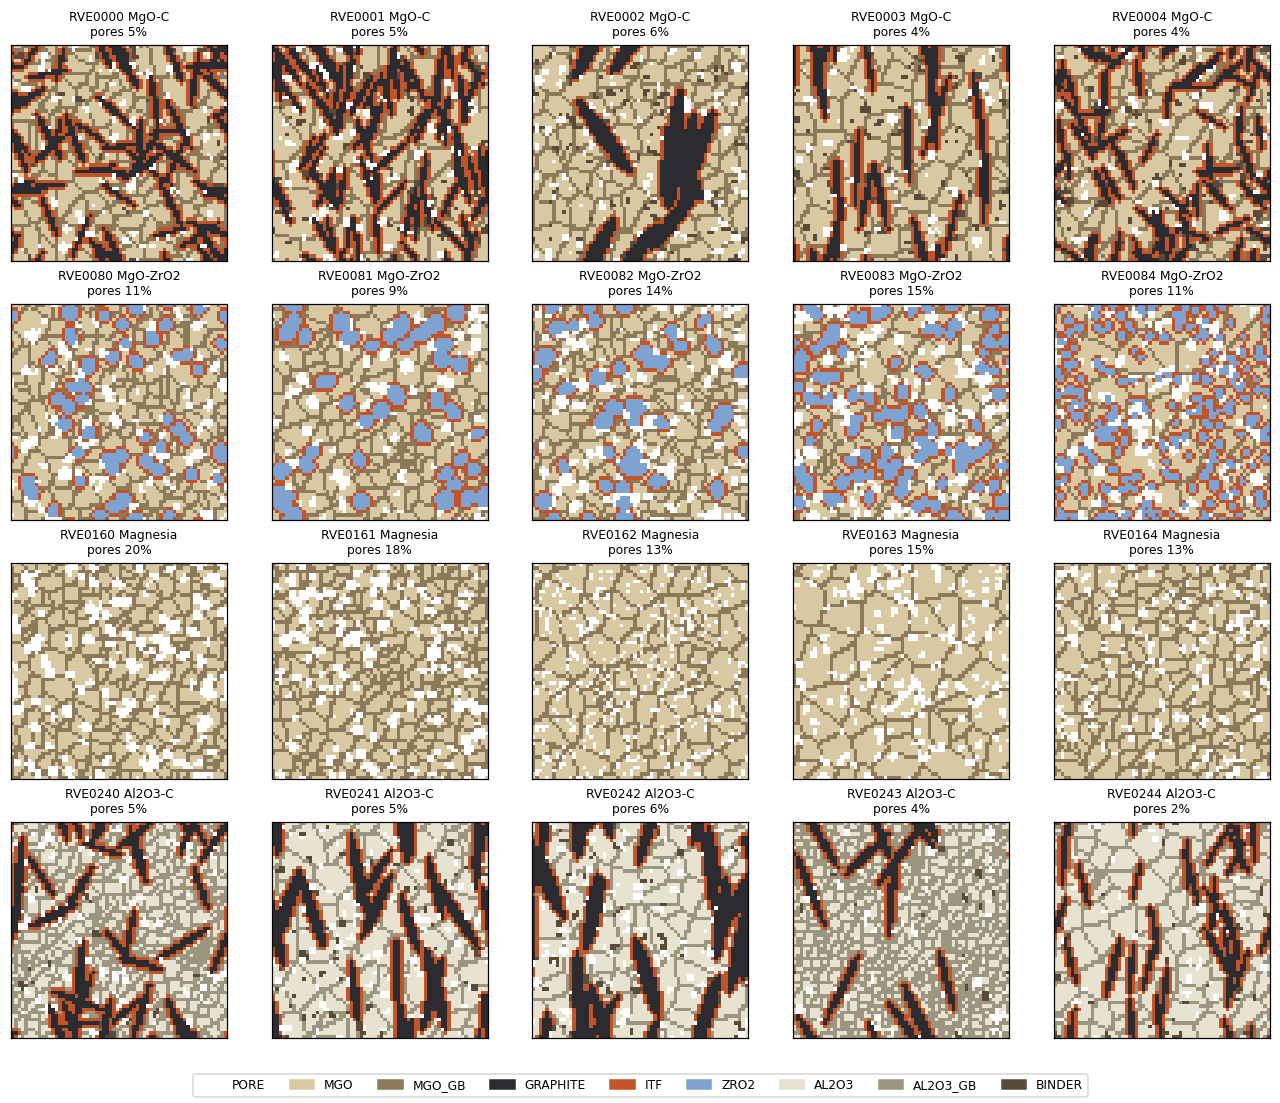

PASS  RVE: corner pixels solid and islands removed


In [18]:
PH_COLORS = ["#ffffff", "#d9c9a3", "#8c7a5a", "#2b2b30", "#c2542a", "#7fa3d1", "#e8e2d0", "#9c9580", "#5a4a3a"]
PH_CMAP = ListedColormap(PH_COLORS)
def show_phase(ax, ph, title=""):
    ax.imshow(ph, cmap=PH_CMAP, vmin=-0.5, vmax=8.5, origin="lower", interpolation="nearest")
    ax.set_title(title, fontsize=8); ax.set_xticks([]); ax.set_yticks([])
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
infos = []
for r_, fam in enumerate(FAMILIES):
    entries = [d for d in design if d["family"] == fam][:5]
    for c_, e in enumerate(entries):
        ph, gr, info = make_rve(fam, e["params"], N=e["N"], L_mm=e["L_mm"], seed=e["seed"])
        infos.append(info)
        show_phase(axes[r_, c_], ph, f"{e['rve_id']} {FAMILY_LABEL[fam]}\npores {info['vf_PORE']:.0%}")
from matplotlib.patches import Patch
fig.legend([Patch(color=PH_COLORS[k]) for k in range(N_PHASES)], [PHASES[k] for k in range(N_PHASES)],
           loc="lower center", ncol=9, fontsize=8)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.savefig(os.path.join(FIG, "rve_gallery.png"), dpi=150); plt.show()
check("RVE: corner pixels solid and islands removed", all(i["corners_ok"] for i in infos))

## 4. Abaqus decks
**Model.** Flat input file (no parts/assembly, so no assembly-level node pruning), CPS4 plane-stress elements (one per
pixel), periodic `*EQUATION`s with reference nodes RP1/RP2 (attached to MASS elements), and per-RVE materials.

* **Crack deck:** Concrete Damaged Plasticity for every phase (tension softening by fracture energy, `TYPE=GFI`, same
  f_t and G_F as the Python model). Steps: `PROBE0` (elastic modulus) → `UNLOAD` → `COOL` (εₓₓ = 0, σᵧᵧ = 0, uniform
  cooling to −200 K, output at 10/25/50/100/200 K plus 30 fine time points) → `PROBE1` (secant stiffness of the cracked RVE).
* **Creep deck:** `*CREEP, LAW=TIME` (Norton, m = 0) with the Arrhenius factor of the RVE temperature. Steps: `LOAD`
  (`*STATIC`) → `CREEP` (`*VISCO`, 10 h).

**Verification before anything is submitted:** (i) independent text validator (connectivity, element orientation, sets,
sections, every eliminated dof unique and free of boundary conditions, no unconnected nodes); (ii) **the deck is parsed
back into a new FE model, built only from the deck text, and solved**. Its stresses, modulus and crack onset must equal
the reference solver.

In [19]:
DECKS = os.path.join(W, "abaqus_decks")
def deck_entry(e, N=None):
    N = N or e["N"]
    ph, gr, info = make_rve(e["family"], e["params"], N=N, L_mm=e["L_mm"], seed=e["seed"])
    mesh = PixelMesh(ph, L=e["L_mm"])
    return ph, mesh, rve_materials(e["family"], e["params"])

# --- smoke-test decks (run these first on the CIP machine) ---------------------------------
# (1) homogeneous dense MgO 16x16: analytic crack onset 19.75 K
ph_h = np.ones((16, 16), np.uint8); mesh_h = PixelMesh(ph_h)
mats_h = rve_materials("MAG", {"k_gb": 1.0})
write_thermal_shock_deck(os.path.join(DECKS, "SMOKE_TS_HOMOG.inp"), mesh_h, mats_h, PHASES, DT_LEVELS, "SMOKE homogeneous MgO")
# (2) a real MgO-C RVE at 32 px, (3) its creep deck
e0 = design[0]
ph_s, mesh_s, mats_s = deck_entry(e0, N=32)
write_thermal_shock_deck(os.path.join(DECKS, "SMOKE_TS_RVE.inp"), mesh_s, mats_s, PHASES, DT_LEVELS, "SMOKE " + e0["rve_id"] + " 32px")
write_creep_deck(os.path.join(DECKS, "SMOKE_CR_RVE.inp"), mesh_s, mats_s, PHASES, -e0["load"]["creep_stress"],
                 arrhenius(e0["load"]["creep_T"]), CREEP_T_END, CREEP_SNAPS, "SMOKE " + e0["rve_id"] + " 32px")

# --- production decks: first k RVEs of each family ------------------------------------------
deck_list = []
if CONFIG["WRITE_ABAQUS_DECKS"]:
    for fam in FAMILIES:
        for e in [d for d in design if d["family"] == fam][:CONFIG["ABAQUS_DECKS_PER_FAMILY"]]:
            ph, mesh, mats = deck_entry(e)
            write_thermal_shock_deck(os.path.join(DECKS, f"TS_{e['rve_id']}.inp"), mesh, mats, PHASES, DT_LEVELS, e["rve_id"] + " " + fam)
            write_creep_deck(os.path.join(DECKS, f"CR_{e['rve_id']}.inp"), mesh, mats, PHASES, -e["load"]["creep_stress"],
                             arrhenius(e["load"]["creep_T"]), CREEP_T_END, CREEP_SNAPS, e["rve_id"] + " " + fam)
            deck_list += [f"TS_{e['rve_id']}.inp", f"CR_{e['rve_id']}.inp"]
write_scripts(DECKS)
json.dump(design, open(os.path.join(DECKS, "design.json"), "w"))

# --- (i) validate every deck ------------------------------------------------------------------
allfiles = sorted(glob.glob(os.path.join(DECKS, "*.inp")))
bad = {}
for f in allfiles:
    ok, probs, st = validate_deck(f)
    if not ok:
        bad[os.path.basename(f)] = probs[:3]
print(f"{len(allfiles)} decks written, {len(allfiles) - len(bad)} valid", "" if not bad else bad)
check("Abaqus: all decks pass the static validator", len(bad) == 0, f"{len(allfiles)} decks")

83 decks written, 83 valid 
PASS  Abaqus: all decks pass the static validator   [83 decks]


In [20]:
# --- (ii) rebuild the FE model from the deck text and compare with the reference solver --------
from sim import _solve_unit, _probe_E
rows = []
for fam in FAMILIES:
    e = [d for d in design if d["family"] == fam][0]
    ph, mesh, mats = deck_entry(e)
    props = element_props(mesh, mats, PHASES)
    f_ts = os.path.join(DECKS, f"TS_{e['rve_id']}.inp")
    if not os.path.exists(f_ts):
        write_thermal_shock_deck(f_ts, mesh, mats, PHASES, DT_LEVELS, "check")
    R = deck_linear_response(f_ts)
    lam_, mu_ = lame(props["E"], props["nu"])
    Kq, free, fidx, lu, s = _solve_unit(mesh, lam_, mu_, props["alpha"])
    s1 = np.maximum(principal_max(s), 0)
    o_ref = np.argsort(mesh.elem_id); o_deck = np.argsort(R["elem_labels"])
    err = np.abs(R["s1_per_K"][o_deck] - s1[o_ref]).max() / s1.max()
    E_ref = _probe_E(mesh, Kq, free, fidx, lu)
    dTc_ref = float(np.min(np.where(s1 > 0, props["ft"] / s1, np.inf)))
    f_cr = os.path.join(DECKS, f"CR_{e['rve_id']}.inp")
    if not os.path.exists(f_cr):
        write_creep_deck(f_cr, mesh, mats, PHASES, -e["load"]["creep_stress"], arrhenius(e["load"]["creep_T"]), CREEP_T_END, CREEP_SNAPS, "check")
    Rc = deck_linear_response(f_cr)
    cr = creep_norton(mesh, props, -e["load"]["creep_stress"], arrhenius(e["load"]["creep_T"]), 60.0, [60.0])
    rows.append(dict(family=FAMILY_LABEL[fam], rve=e["rve_id"], s1_max_relerr=err,
                     E_deck=R["E_probe_force"], E_ref=E_ref, dTc_deck=R["dTc"], dTc_ref=dTc_ref,
                     creep_elastic_deck=Rc["creep_elastic_U1"], creep_elastic_ref=cr["eps_elastic"]))
cmp = pd.DataFrame(rows); display(cmp.round(6))
worst = max(cmp.s1_max_relerr.max(), (cmp.E_deck / cmp.E_ref - 1).abs().max(), (cmp.dTc_deck / cmp.dTc_ref - 1).abs().max(),
            (cmp.creep_elastic_deck / cmp.creep_elastic_ref - 1).abs().max())
# tolerance 1e-6: the deck stores numbers with 8 significant digits (relative rounding ~1e-8)
check("Abaqus: deck rebuilt from text == reference solver (stress, E, dT_c, creep load)", worst < 1e-6, f"max rel.err {worst:.1e}")

,family,rve,s1_max_relerr,E_deck,E_ref,dTc_deck,dTc_ref,creep_elastic_deck,creep_elastic_ref
0,MgO-C,RVE0000,0.0,93156.004979,93156.004979,3.817975,3.817975,-0.000039,-0.000039
1,MgO-ZrO2,RVE0080,0.0,187742.987230,187742.987230,5.690751,5.690751,-0.000014,-0.000014
2,Magnesia,RVE0160,0.0,140826.178296,140826.178296,3.565731,3.565731,-0.000045,-0.000045
3,Al2O3-C,RVE0240,0.0,115626.529812,115626.529812,9.669708,9.669708,-0.000057,-0.000057


PASS  Abaqus: deck rebuilt from text == reference solver (stress, E, dT_c, creep load)   [max rel.err 1.4e-08]


In [21]:
print(f"""
HOW TO RUN ON THE CIP MACHINE (cip-sim1 / cip-sim2, Abaqus 2025) - type one command at a time:
  1. copy the folder  {DECKS}  to the CIP machine
  2. cd into it
  3. bash run_smoke.sh            -> datacheck + 3 small jobs + extraction (few minutes)
       expected: SMOKE_TS_HOMOG cracks at dT = 19.75 K (analytic)
  4. bash run_abaqus.sh 4         -> all TS_/CR_ decks, 4 jobs in parallel (skips finished jobs)
  5. abaqus python extract_odb.py .
  6. copy all *_results.npz back into  {CONFIG['ABAQUS_RESULTS_DIR']}  and re-run section 12
(if the command is not 'abaqus', set it first:  export ABAQUS_CMD=abq2025)
""")


HOW TO RUN ON THE CIP MACHINE (cip-sim1 / cip-sim2, Abaqus 2025) - type one command at a time:
  1. copy the folder  MR_RVE_work/abaqus_decks  to the CIP machine
  2. cd into it
  3. bash run_smoke.sh            -> datacheck + 3 small jobs + extraction (few minutes)
       expected: SMOKE_TS_HOMOG cracks at dT = 19.75 K (analytic)
  4. bash run_abaqus.sh 4         -> all TS_/CR_ decks, 4 jobs in parallel (skips finished jobs)
  5. abaqus python extract_odb.py .
  6. copy all *_results.npz back into  MR_RVE_work/abaqus_results  and re-run section 12
(if the command is not 'abaqus', set it first:  export ABAQUS_CMD=abq2025)



## 5. Dataset (Python reference solver)
Each RVE: homogenisation (E₀, α_eff) → thermal shock at ΔT = 10, 25, 50, 100, 200 K (damage map, max-principal
stress map, residual stiffness E/E₀, cracked fraction, onset ΔT_c) → creep (equivalent creep strain maps after 1, 3 and
10 h, macro creep strain, steady rate). Results are cached per RVE; `RUN_SIMULATIONS=True` computes only missing RVEs.

In [26]:
SIM = os.path.join(W, "sim")
missing = [e for e in design if not os.path.exists(os.path.join(SIM, e["rve_id"] + ".npz"))]
print(f"cached: {len(design) - len(missing)} / {len(design)} RVEs")
if missing and CONFIG["RUN_SIMULATIONS"]:
    from joblib import Parallel, delayed
    t0 = time.time()
    for k in range(0, len(missing), 4 * CONFIG["N_JOBS"]):
        batch = missing[k:k + 4 * CONFIG["N_JOBS"]]
        Parallel(n_jobs=CONFIG["N_JOBS"])(delayed(simulate_rve)(e, SIM) for e in batch)
        print(f"  {min(k + len(batch), len(missing))}/{len(missing)} simulated, {time.time() - t0:.0f} s", flush=True)
elif missing:
    print("RUN_SIMULATIONS=False -> continuing with the cached RVEs only")
df, PH, DAM, CEEQ, LEVELS, CTIMES = load_sim_results(SIM)
print(df.shape[0], "RVEs loaded:", df.family.value_counts().to_dict())
finite = np.isfinite(df.select_dtypes("number").values).all() and np.isfinite(DAM).all() and np.isfinite(CEEQ).all()
check("Dataset: all values finite", finite)
check("Dataset: SLA cap reached in < 5 % of RVEs", df.sla_capped.mean() < 0.05, f"{df.sla_capped.mean():.1%}")

cached: 320 / 320 RVEs
320 RVEs loaded: {'MGOC': 80, 'MGOZR': 80, 'MAG': 80, 'ALC': 80}
PASS  Dataset: all values finite
PASS  Dataset: SLA cap reached in < 5 % of RVEs   [0.0%]


In [27]:
   import glob, collections
   print(len(glob.glob("MR_RVE_work/sim/*.npz")), "design RVEs (expect 320)")
   print(len(glob.glob("MR_RVE_work/ranked/*.npz")), "Kanapy realizations (expect 50)")

320 design RVEs (expect 320)
50 Kanapy realizations (expect 50)


In [28]:
if CONFIG["RUN_CONVERGENCE_CHECK"]:
    # sequentially linear analysis: compare the production event strategy with 3-5x finer event steps
    rows = []
    for fam in FAMILIES:
        e = [d for d in design if d["family"] == fam][1]
        ph, mesh, mats = deck_entry(e)
        props = element_props(mesh, mats, PHASES)
        a = thermal_shock_sla(mesh, props, DT_LEVELS)
        b = thermal_shock_sla(mesh, props, DT_LEVELS, band=0.01, band_cascade=0.05, max_solves=3000)
        for k, lv in enumerate(DT_LEVELS):
            rows.append(dict(family=FAMILY_LABEL[fam], dT=lv, E_ratio_prod=a["snaps"][k]["E_ratio"], E_ratio_fine=b["snaps"][k]["E_ratio"],
                             cracked_prod=a["snaps"][k]["frac_cracked"], cracked_fine=b["snaps"][k]["frac_cracked"]))
        print(f"{fam}: solves production {a['solves']}, fine {b['solves']}; dT_c {a['dTc']:.3f} vs {b['dTc']:.3f} K")
    conv = pd.DataFrame(rows)
    conv["abs_dlog"] = (np.log10(conv.E_ratio_prod) - np.log10(conv.E_ratio_fine)).abs()
    # yardstick: scatter between microstructure realizations (IQR of log10 E/E0 within the family, same dT)
    iqr = {(FAMILY_LABEL[f], l): float(np.subtract(*np.percentile(np.log10(df[df.family == f][f"E_ratio_{int(l)}"]), [75, 25])))
           for f in FAMILIES for l in LEVELS}
    conv["IQR_realizations"] = [iqr[(a, b)] for a, b in zip(conv.family, conv.dT)]
    display(conv.round(3))
    med_err, med_iqr, max_err = conv.abs_dlog.median(), conv.IQR_realizations.median(), conv.abs_dlog.max()
    check("SLA: event-step error below the scatter between microstructures (median |dlog E/E0| < median IQR)",
          med_err < med_iqr, f"median {med_err:.3f} vs {med_iqr:.3f} dex; worst case {max_err:.3f} dex")
    print("The largest step sensitivity occurs after the crack has crossed the cell (E/E0 < 0.1), where the SLA crack "
          "path can branch differently; the crack onset dT_c is step-independent.")

MGOC: solves production 270, fine 1072; dT_c 3.958 vs 3.958 K
MGOZR: solves production 199, fine 636; dT_c 5.482 vs 5.482 K
MAG: solves production 127, fine 242; dT_c 4.511 vs 4.511 K
ALC: solves production 70, fine 259; dT_c 9.733 vs 9.733 K


,family,dT,E_ratio_prod,E_ratio_fine,cracked_prod,cracked_fine,abs_dlog,IQR_realizations
0,MgO-C,10.0,0.895,0.874,0.006,0.006,0.010,0.056
1,MgO-C,25.0,0.380,0.429,0.056,0.048,0.052,0.294
2,MgO-C,50.0,0.202,0.229,0.087,0.078,0.055,0.284
3,MgO-C,100.0,0.110,0.109,0.159,0.157,0.006,0.212
4,MgO-C,200.0,0.049,0.053,0.267,0.258,0.036,0.179
5,MgO-ZrO2,10.0,0.826,0.838,0.006,0.006,0.006,0.102
6,MgO-ZrO2,25.0,0.118,0.090,0.039,0.026,0.118,0.211
7,MgO-ZrO2,50.0,0.061,0.064,0.042,0.029,0.019,0.105
8,MgO-ZrO2,100.0,0.050,0.053,0.055,0.043,0.029,0.105
9,MgO-ZrO2,200.0,0.021,0.026,0.160,0.142,0.103,0.086


PASS  SLA: event-step error below the scatter between microstructures (median |dlog E/E0| < median IQR)   [median 0.038 vs 0.153 dex; worst case 0.160 dex]
The largest step sensitivity occurs after the crack has crossed the cell (E/E0 < 0.1), where the SLA crack path can branch differently; the crack onset dT_c is step-independent.


## 6. Physics in the data

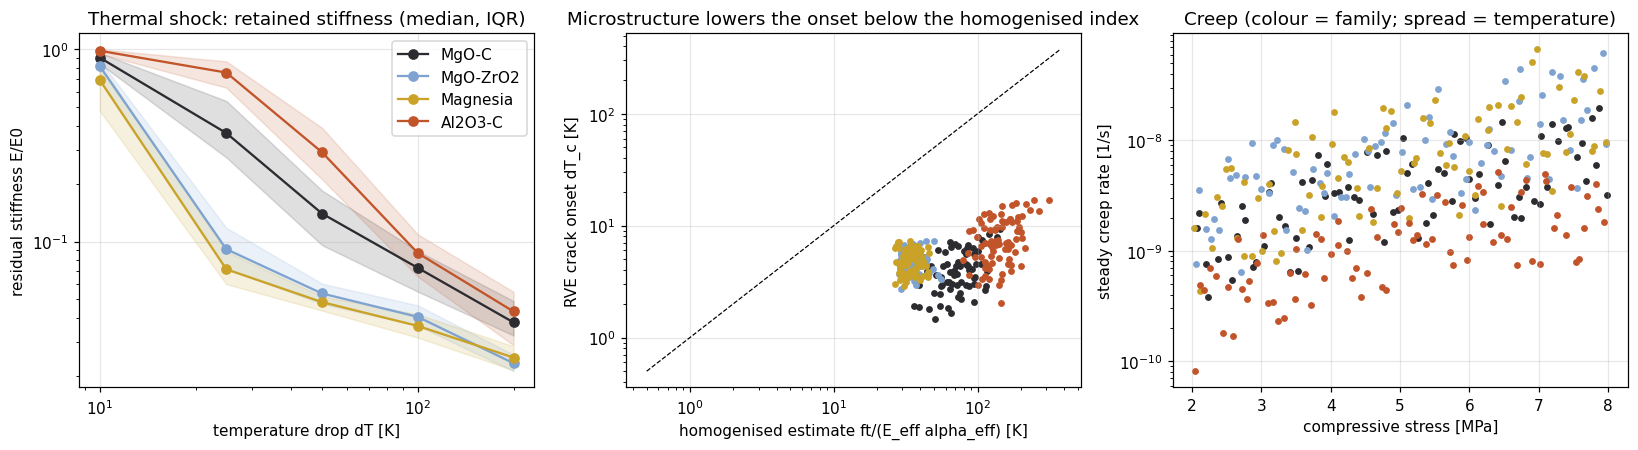

,E_ratio_10,E_ratio_25,E_ratio_50,E_ratio_100,E_ratio_200,dTc
family,,,,,,
Al2O3-C,0.982,0.756,0.291,0.087,0.043,7.181
Magnesia,0.692,0.072,0.048,0.036,0.025,4.648
MgO-C,0.904,0.367,0.140,0.073,0.038,3.957
MgO-ZrO2,0.815,0.091,0.054,0.041,0.023,4.939


PASS  Physics: Hasselman paradox - MgO-C retains more stiffness at 25 K than magnesia   [0.37 vs 0.07]


In [29]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
cols = {"MGOC": "#2b2b30", "MGOZR": "#7fa3d1", "MAG": "#c9a227", "ALC": "#c2542a"}
for fam in FAMILIES:
    sub = df[df.family == fam]
    E = np.array([sub[f"E_ratio_{int(l)}"] for l in LEVELS])
    ax[0].plot(LEVELS, np.median(E, 1), "o-", color=cols[fam], label=FAMILY_LABEL[fam])
    ax[0].fill_between(LEVELS, np.percentile(E, 25, 1), np.percentile(E, 75, 1), color=cols[fam], alpha=0.15)
    ax[1].scatter(sub.R_hom, sub.dTc, s=12, color=cols[fam], label=FAMILY_LABEL[fam])
    ax[2].scatter(sub.creep_stress, -sub.creep_rate, s=12, c=cols[fam], label=FAMILY_LABEL[fam])
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("temperature drop dT [K]"); ax[0].set_ylabel("residual stiffness E/E0")
ax[0].set_title("Thermal shock: retained stiffness (median, IQR)"); ax[0].legend()
lim = [0.5, max(df.R_hom.max(), df.dTc.max()) * 1.2]
ax[1].plot(lim, lim, "k--", lw=0.8); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("homogenised estimate ft/(E_eff alpha_eff) [K]"); ax[1].set_ylabel("RVE crack onset dT_c [K]")
ax[1].set_title("Microstructure lowers the onset below the homogenised index")
ax[2].set_yscale("log"); ax[2].set_xlabel("compressive stress [MPa]"); ax[2].set_ylabel("steady creep rate [1/s]")
ax[2].set_title("Creep (colour = family; spread = temperature)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "physics_overview.png"), dpi=150); plt.show()
med = df.groupby("family")[[f"E_ratio_{int(l)}" for l in LEVELS] + ["dTc"]].median()
display(med.rename(index=FAMILY_LABEL).round(3))
check("Physics: Hasselman paradox - MgO-C retains more stiffness at 25 K than magnesia",
      med.loc["MGOC", "E_ratio_25"] > med.loc["MAG", "E_ratio_25"], f"{med.loc['MGOC','E_ratio_25']:.2f} vs {med.loc['MAG','E_ratio_25']:.2f}")

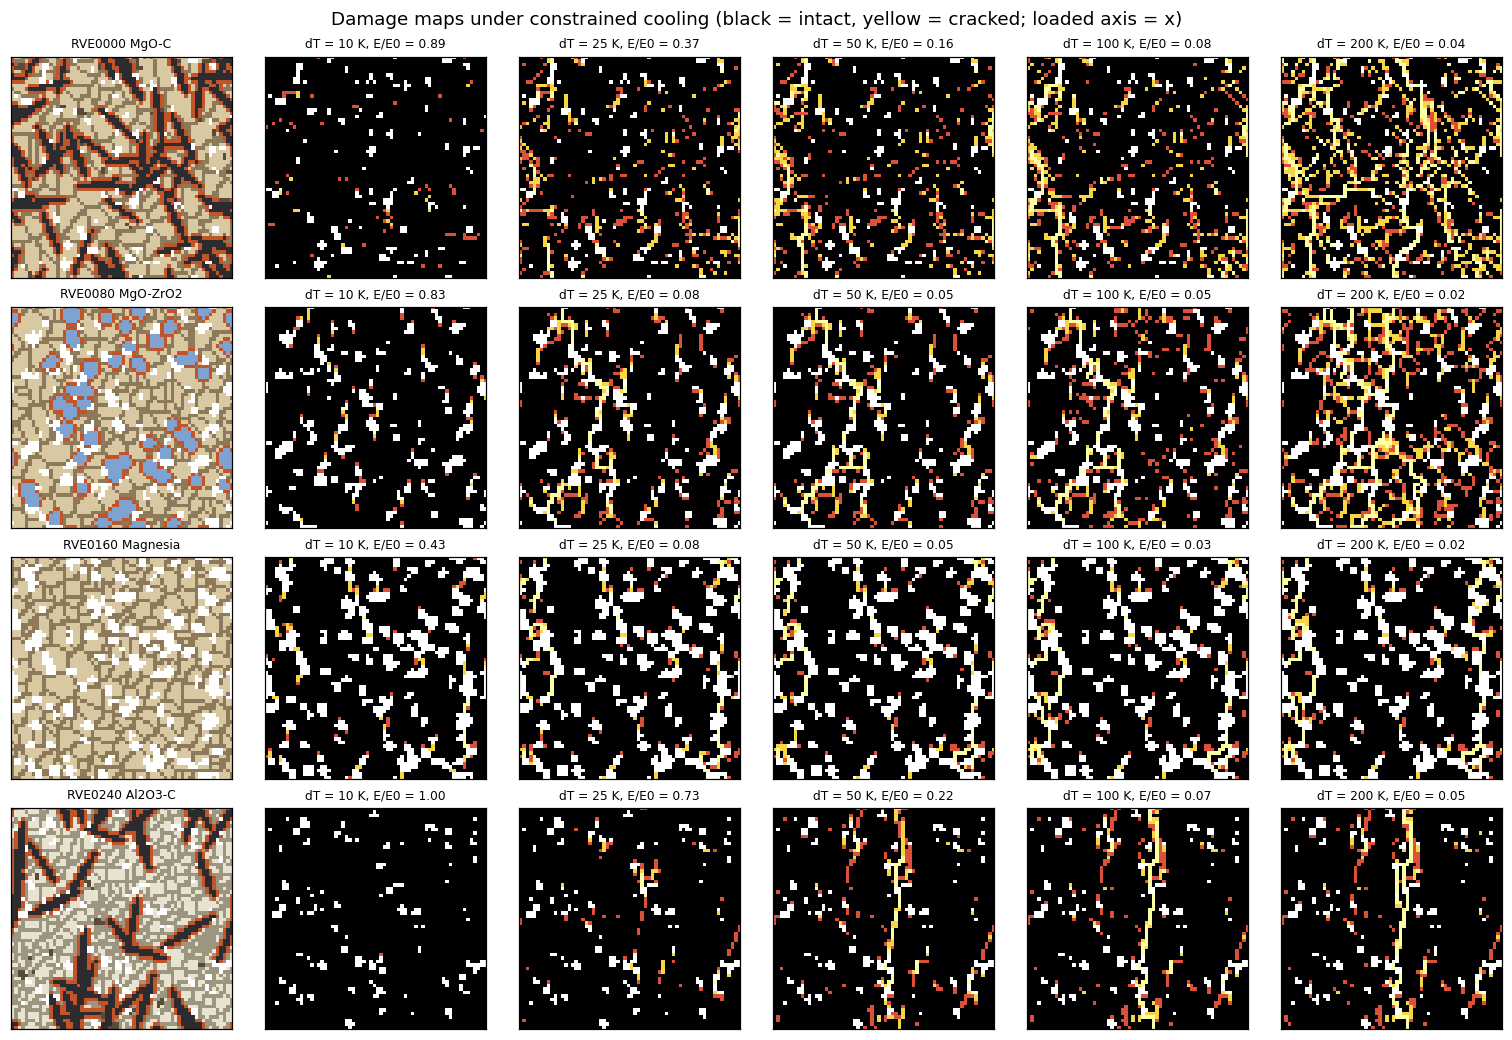

In [30]:
# crack evolution of one RVE per family (Python solver)
fig, axes = plt.subplots(4, 6, figsize=(14, 9.6))
for r_, fam in enumerate(FAMILIES):
    i = np.where(df.family.values == fam)[0][0]
    show_phase(axes[r_, 0], PH[i], f"{df.rve_id[i]} {FAMILY_LABEL[fam]}")
    for k in range(5):
        d = np.ma.masked_less(DAM[i, k], 0)
        axes[r_, k + 1].imshow(d, cmap="inferno", vmin=0, vmax=1, origin="lower", interpolation="nearest")
        axes[r_, k + 1].set_title(f"dT = {LEVELS[k]:.0f} K, E/E0 = {df.loc[i, f'E_ratio_{int(LEVELS[k])}']:.2f}", fontsize=8)
        axes[r_, k + 1].set_xticks([]); axes[r_, k + 1].set_yticks([])
plt.suptitle("Damage maps under constrained cooling (black = intact, yellow = cracked; loaded axis = x)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "crack_evolution.png"), dpi=150); plt.show()

## 7. ANN: descriptors → crack onset, residual stiffness, creep
Inputs: family, phase fractions, flake length/aspect/texture, grain size, boundary and interface strength factors,
homogenised modulus and expansion (cheap linear FE), creep stress and temperature. Targets (log₁₀): ΔT_c, E/E₀ at the
five ΔT levels, steady creep rate, creep strain after 10 h. Validation: 5-fold CV over RVEs (interpolation) and
leave-one-family-out (extrapolation to an unseen material class). References: random forest, and for ΔT_c the
homogenised Hasselman estimate.

In [31]:
import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(CONFIG["TF_THREADS"])
tf.config.threading.set_inter_op_parallelism_threads(1)
import ml_models; importlib.reload(ml_models)
from ml_models import *
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

TARGETS = {"log10 dT_c": np.log10(df.dTc.values)}
for l in LEVELS:
    TARGETS[f"log10 E/E0 @{l:.0f}K"] = np.log10(np.clip(df[f"E_ratio_{int(l)}"].values, 1e-4, None))
TARGETS["log10 creep rate"] = np.log10(np.clip(-df.creep_rate.values, 1e-14, None))
TARGETS["log10 creep strain 10h"] = np.log10(np.clip(-df.macro_creep_10h.values, 1e-12, None))
Xd = df[DESC_COLS].values.astype(np.float32)
Yt = np.column_stack(list(TARGETS.values())).astype(np.float32)
tnames = list(TARGETS)

def fit_predict_ann(Xtr, Ytr, Xte, seed):
    sx, sy = StandardScaler().fit(Xtr), StandardScaler().fit(Ytr)
    keras.utils.set_random_seed(seed)
    m = build_ann(Xtr.shape[1], Ytr.shape[1])
    cb = [keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)]
    m.fit(sx.transform(Xtr), sy.transform(Ytr), validation_split=0.15, epochs=400, batch_size=32, verbose=0, callbacks=cb)
    return sy.inverse_transform(m.predict(sx.transform(Xte), verbose=0))

def cv_eval(splits):
    P_ann, P_rf, P_has = np.zeros_like(Yt), np.zeros_like(Yt), np.zeros_like(Yt)
    for k, (tr, te) in enumerate(splits):
        P_ann[te] = fit_predict_ann(Xd[tr], Yt[tr], Xd[te], seed=k)
        rf = RandomForestRegressor(300, min_samples_leaf=2, random_state=k, n_jobs=CONFIG["N_JOBS"]).fit(Xd[tr], Yt[tr])
        P_rf[te] = rf.predict(Xd[te])
        lr = LinearRegression().fit(np.log10(df.R_hom.values[tr])[:, None], Yt[tr])
        P_has[te] = lr.predict(np.log10(df.R_hom.values[te])[:, None])
    return P_ann, P_rf, P_has

t0 = time.time()
cv_splits = list(KFold(5, shuffle=True, random_state=CONFIG["SEED"]).split(Xd))
P_ann, P_rf, P_has = cv_eval(cv_splits)
lofo_splits = [(np.where(df.family != f)[0], np.where(df.family == f)[0]) for f in FAMILIES]
L_ann, L_rf, L_has = cv_eval(lofo_splits)
print(f"ANN/RF cross-validation done in {time.time() - t0:.0f} s")
res = []
for j, t in enumerate(tnames):
    res.append(dict(target=t, ANN_MAE=mean_absolute_error(Yt[:, j], P_ann[:, j]), ANN_R2=r2_score(Yt[:, j], P_ann[:, j]),
                    RF_MAE=mean_absolute_error(Yt[:, j], P_rf[:, j]), RF_R2=r2_score(Yt[:, j], P_rf[:, j]),
                    ANN_MAE_LOFO=mean_absolute_error(Yt[:, j], L_ann[:, j]), RF_MAE_LOFO=mean_absolute_error(Yt[:, j], L_rf[:, j])))
res = pd.DataFrame(res).set_index("target")
for j, t in enumerate(tnames[:1 + len(LEVELS)]):            # index-based reference: target ~ a + b*log10(R_hom), in-fold fit
    res.loc[t, "Hasselman_MAE"] = mean_absolute_error(Yt[:, j], P_has[:, j])
    res.loc[t, "Hasselman_R2"] = r2_score(Yt[:, j], P_has[:, j])
display(res.round(3))
j25 = tnames.index("log10 E/E0 @25K")
check("ANN: residual stiffness after a 25 K shock predicted with R2 > 0.7 (5-fold CV)", res.iloc[j25].ANN_R2 > 0.7,
      f"ANN R2 {res.iloc[j25].ANN_R2:.2f}; FE-homogenised index alone R2 {res.iloc[j25].Hasselman_R2:.2f}")
print("Note: the index ft/(E_eff*alpha_eff) uses the RVE's FE-homogenised E and alpha, i.e. it already contains the "
      "microstructure; Hasselman scaling holds at the RVE scale only with homogenised (not handbook) properties.")
print(f"Crack onset dT_c: ANN R2 {res.iloc[0].ANN_R2:.2f} vs FE-homogenised index R2 {res.iloc[0].Hasselman_R2:.2f} - "
      "the onset is controlled by local stress concentrations (pores, weak interfaces), which the index cannot see.")
check("ANN: creep rate R2 > 0.9 (5-fold CV)", res.loc["log10 creep rate", "ANN_R2"] > 0.9, f"{res.loc['log10 creep rate','ANN_R2']:.3f}")

2026-10-14 12:34:33.536993: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


ANN/RF cross-validation done in 213 s


,ANN_MAE,ANN_R2,RF_MAE,RF_R2,ANN_MAE_LOFO,RF_MAE_LOFO,Hasselman_MAE,Hasselman_R2
target,,,,,,,,
log10 dT_c,0.067,0.773,0.092,0.568,0.119,0.155,0.133,0.150
log10 E/E0 @10K,0.063,0.605,0.069,0.515,0.074,0.084,0.092,0.219
log10 E/E0 @25K,0.110,0.898,0.103,0.907,0.151,0.176,0.135,0.855
log10 E/E0 @50K,0.077,0.913,0.077,0.907,0.152,0.158,0.092,0.886
log10 E/E0 @100K,0.083,0.711,0.087,0.665,0.119,0.098,0.100,0.609
log10 E/E0 @200K,0.075,0.606,0.076,0.630,0.110,0.091,0.091,0.453
log10 creep rate,0.053,0.983,0.130,0.899,0.267,0.263,NaN,NaN
log10 creep strain 10h,0.056,0.980,0.131,0.892,0.340,0.264,NaN,NaN


PASS  ANN: residual stiffness after a 25 K shock predicted with R2 > 0.7 (5-fold CV)   [ANN R2 0.90; FE-homogenised index alone R2 0.86]
Note: the index ft/(E_eff*alpha_eff) uses the RVE's FE-homogenised E and alpha, i.e. it already contains the microstructure; Hasselman scaling holds at the RVE scale only with homogenised (not handbook) properties.
Crack onset dT_c: ANN R2 0.77 vs FE-homogenised index R2 0.15 - the onset is controlled by local stress concentrations (pores, weak interfaces), which the index cannot see.
PASS  ANN: creep rate R2 > 0.9 (5-fold CV)   [0.983]


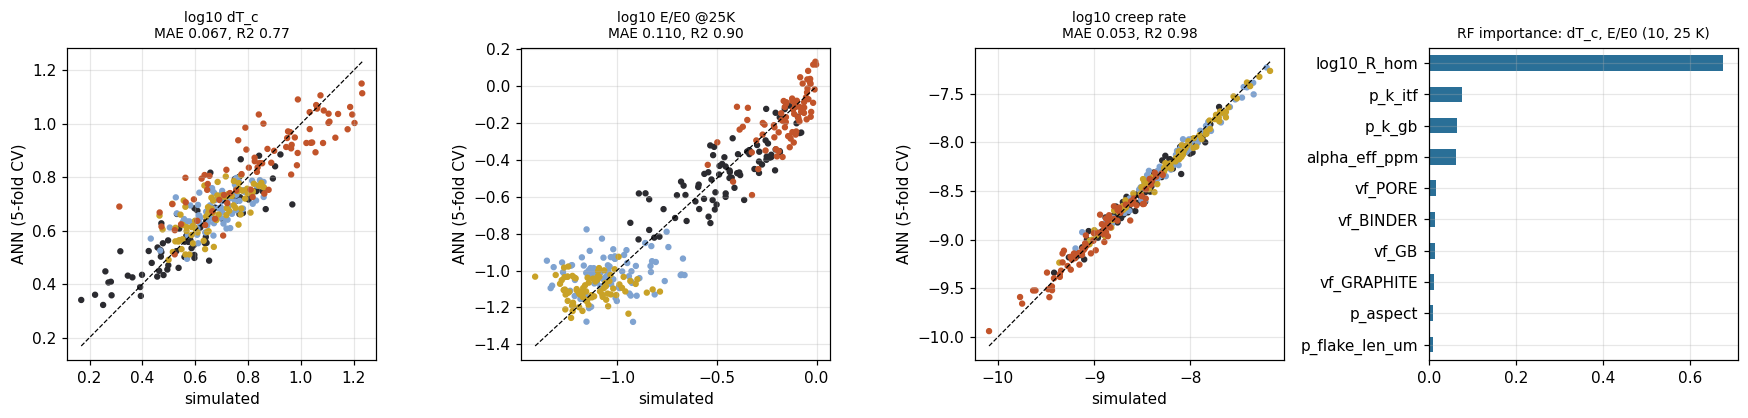

In [32]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.9))
famc = df.family.map(cols).values
for a, j in zip(ax[:3], [0, 2, len(tnames) - 2]):
    a.scatter(Yt[:, j], P_ann[:, j], s=10, c=famc)
    lo, hi = Yt[:, j].min(), Yt[:, j].max(); a.plot([lo, hi], [lo, hi], "k--", lw=0.8)
    a.set_xlabel("simulated"); a.set_ylabel("ANN (5-fold CV)")
    a.set_title(f"{tnames[j]}\nMAE {res.iloc[j].ANN_MAE:.3f}, R2 {res.iloc[j].ANN_R2:.2f}", fontsize=9)
rf_all = RandomForestRegressor(500, min_samples_leaf=2, random_state=0, n_jobs=CONFIG["N_JOBS"]).fit(Xd, Yt[:, :3])
imp = pd.Series(rf_all.feature_importances_, index=DESC_COLS).sort_values()[-10:]
imp.plot.barh(ax=ax[3], color="#2a6f97"); ax[3].set_title("RF importance: dT_c, E/E0 (10, 25 K)", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "ann_results.png"), dpi=150); plt.show()

## 8. CNN: damage map after a thermal shock
**Input:** 64 × 64 microstructure (one-hot phases, 9 channels) + one constant channel with log ΔT. **Output:** damage map
(0 intact … 1 cracked). **Architecture:** U-Net (3 levels, 16–128 filters) with **periodic padding** in every convolution,
because the RVE is periodic; this makes the network exactly translation-equivariant (checked below).
**Training:** split by RVE (70/15/15 per family, no microstructure in two sets), random periodic shifts and mirror
images as augmentation (exact symmetries of the loading; 90° rotations are not used because they would swap the
loaded and free axes), weighted cross-entropy (cracked pixels ×5, pores masked), early stopping on validation loss.
**Reference:** a pixel prior (mean damage of each phase at each ΔT in the training set).

In [34]:
Xc, Yc, Mc, Gc, LVc = crack_samples(PH, DAM, LEVELS)
tr_r, va_r, te_r = split_by_rve(len(df), df, seed=CONFIG["SEED"])
itr, iva, ite = np.isin(Gc, tr_r), np.isin(Gc, va_r), np.isin(Gc, te_r)
YMc = np.concatenate([Yc, Mc], -1)
print("crack samples train/val/test:", itr.sum(), iva.sum(), ite.sum())
keras.utils.set_random_seed(CONFIG["SEED"])
cnn_crack = build_unet(Xc.shape[-1], "sigmoid", base=CONFIG["CNN_BASE_FILTERS"], N=CONFIG["N_PIXELS"])
x_ = Xc[:2]; y0 = cnn_crack(x_, training=False).numpy()
y1 = cnn_crack(np.roll(np.roll(x_, 8, 1), 24, 2), training=False).numpy()
eqv = float(np.abs(np.roll(np.roll(y0, 8, 1), 24, 2) - y1).max())
check("CNN: periodic U-Net is translation-equivariant", eqv < 1e-5, f"max diff {eqv:.1e}")
print("parameters:", cnn_crack.count_params())
path_crack = os.path.join(W, "models", "cnn_crack.keras")
if CONFIG["TRAIN_CNN"] or not os.path.exists(path_crack):
    cnn_crack.compile(optimizer=keras.optimizers.Adam(2e-3), loss=masked_bce_weighted(4.0))
    cb = [keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)]
    t0 = time.time()
    hist_c = cnn_crack.fit(AugSeq(Xc[itr], YMc[itr], batch=16, seed=1), validation_data=(Xc[iva], YMc[iva]),
                           epochs=CONFIG["CNN_EPOCHS"], verbose=2, callbacks=cb)
    print(f"training time {time.time() - t0:.0f} s")
    cnn_crack.save(path_crack)
    json.dump(hist_c.history, open(path_crack + ".history.json", "w"))
else:
    cnn_crack.load_weights(path_crack)          # load only the trained weights (works with your Keras version)
    print("loaded trained weights:", path_crack)

crack samples train/val/test: 1120 240 240
PASS  CNN: periodic U-Net is translation-equivariant   [max diff 0.0e+00]
parameters: 490417
loaded trained weights: MR_RVE_work/models/cnn_crack.keras


IoU_cracked             pixel_MAE             cracked_fraction_R2  \
model         CNN pixel prior       CNN pixel prior                 CNN   
dT                                                                        
10.0        0.365       0.062     0.024       0.024               0.357   
25.0        0.428       0.000     0.069       0.083               0.509   
50.0        0.434       0.000     0.098       0.113               0.406   
100.0       0.423       0.000     0.129       0.133              -0.347   
200.0       0.476       0.000     0.161       0.170               0.262   

                   
model pixel prior  
dT                 
10.0       -0.965  
25.0       -5.184  
50.0       -8.020  
100.0      -6.575  
200.0      -4.103

PASS  CNN crack: test IoU of cracked pixels beats the pixel prior   [0.43 vs 0.01]


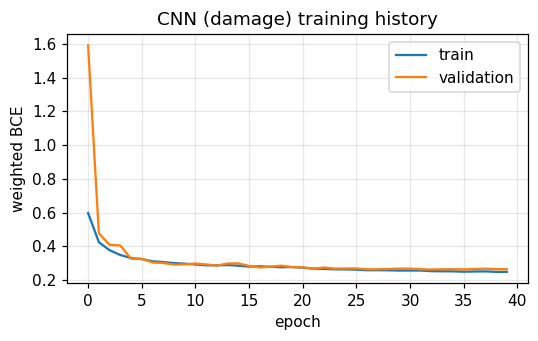

In [35]:
hc = json.load(open(path_crack + ".history.json"))
P_c = cnn_crack.predict(Xc[ite], batch_size=32, verbose=0)
# pixel-prior reference: mean damage per phase and dT level in the training set
prior = np.zeros((len(LEVELS), N_PHASES))
for k in range(len(LEVELS)):
    sel = itr & (LVc == k)
    for c in range(1, N_PHASES):
        mm = (PH[Gc[sel]] == c)
        prior[k, c] = Yc[sel][..., 0][mm].mean() if mm.any() else 0.0
P_prior = np.array([prior[LVc[i], PH[Gc[i]]] for i in np.where(ite)[0]])[..., None]
rows = []
for name, P in [("CNN", P_c), ("pixel prior", P_prior)]:
    for k in range(len(LEVELS)):
        s_ = LVc[ite] == k
        yt, yp, mk = Yc[ite][s_], P[s_], Mc[ite][s_]
        ious = [iou(yt[i], yp[i], mk[i]) for i in range(len(yt))]
        mae = float((np.abs(yt - yp) * mk).sum() / mk.sum())
        fr_t = [(yt[i][mk[i] > 0] >= 0.5).mean() for i in range(len(yt))]
        fr_p = [(yp[i][mk[i] > 0] >= 0.5).mean() for i in range(len(yt))]
        rows.append(dict(model=name, dT=LEVELS[k], IoU_cracked=np.mean(ious), pixel_MAE=mae,
                         cracked_fraction_R2=r2_score(fr_t, fr_p) if np.std(fr_t) > 0 else np.nan))
cm_tab = pd.DataFrame(rows); display(cm_tab.pivot(index="dT", columns="model").round(3))
iou_cnn = cm_tab[cm_tab.model == "CNN"].IoU_cracked.mean(); iou_pr = cm_tab[cm_tab.model == "pixel prior"].IoU_cracked.mean()
check("CNN crack: test IoU of cracked pixels beats the pixel prior", iou_cnn > iou_pr, f"{iou_cnn:.2f} vs {iou_pr:.2f}")
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(hc["loss"], label="train"); ax.plot(hc["val_loss"], label="validation"); ax.set_xlabel("epoch"); ax.set_ylabel("weighted BCE")
ax.legend(); ax.set_title("CNN (damage) training history"); plt.tight_layout(); plt.savefig(os.path.join(FIG, "cnn_crack_history.png"), dpi=150); plt.show()

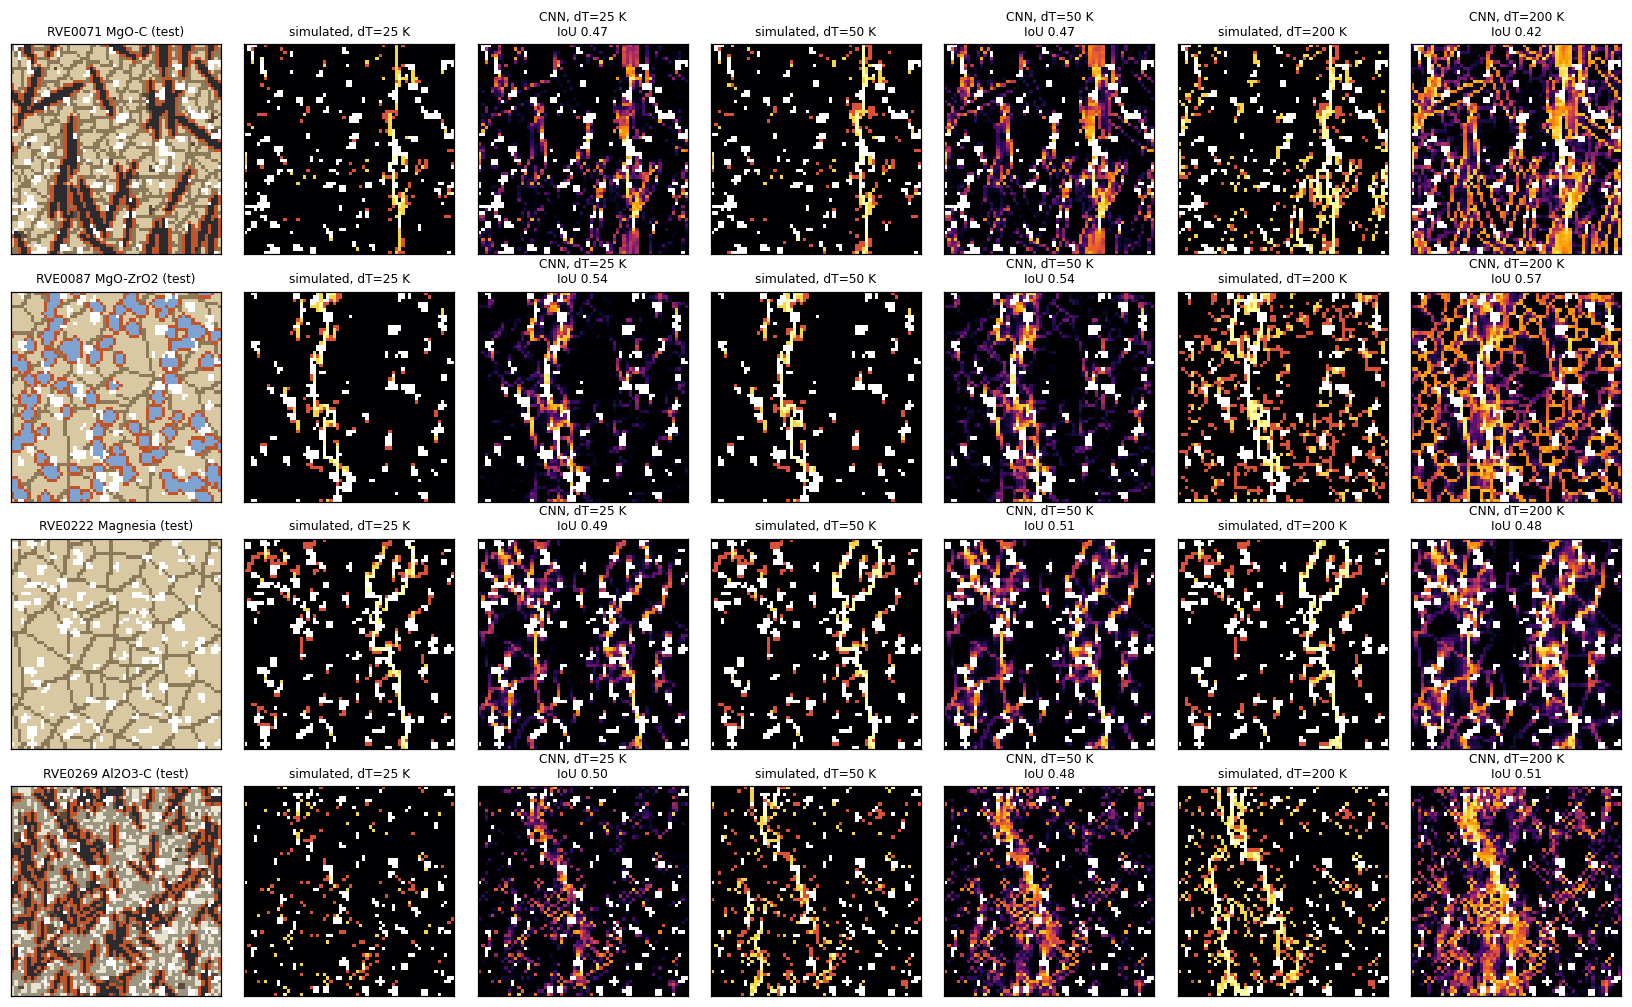

In [36]:
# test RVEs never seen in training: microstructure | simulation | CNN prediction at three dT levels
show = [te_r[np.where(df.family.values[te_r] == f)[0][0]] for f in FAMILIES]
fig, axes = plt.subplots(4, 7, figsize=(15, 9.2))
for r_, i in enumerate(show):
    show_phase(axes[r_, 0], PH[i], f"{df.rve_id[i]} {FAMILY_LABEL[df.family[i]]} (test)")
    for c_, k in enumerate([1, 2, 4]):
        j = np.where((Gc == i) & (LVc == k))[0][0]
        pj = cnn_crack.predict(Xc[j:j + 1], verbose=0)[0, ..., 0]
        mk = Mc[j, ..., 0] > 0
        for off, img, lab in [(0, Yc[j, ..., 0], "simulated"), (1, pj, "CNN")]:
            a = axes[r_, 1 + 2 * c_ + off]
            a.imshow(np.ma.masked_where(~mk, img), cmap="inferno", vmin=0, vmax=1, origin="lower", interpolation="nearest")
            a.set_title(f"{lab}, dT={LEVELS[k]:.0f} K" + (f"\nIoU {iou(Yc[j], pj[..., None], Mc[j]):.2f}" if off else ""), fontsize=8)
            a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(os.path.join(FIG, "cnn_crack_predictions.png"), dpi=150); plt.show()

## 9. CNN: creep-strain map
**Input:** microstructure one-hot + three constant channels (stress/8 MPa, (T−1450 °C)/200 K, log time).
**Output:** log₁₀ of the equivalent creep strain per pixel. Same periodic U-Net, masked MSE.
**Reference:** pixel prior (mean log strain per phase and time in the training set).

log10 creep strain: training mean -4.78, std 1.07
loaded trained weights: MR_RVE_work/models/cnn_creep.keras


,pixel R2 (log strain),pixel MAE [dex]
CNN,0.974,0.120
pixel prior,0.768,0.391


RVE-mean log creep strain: R2 = 0.998
PASS  CNN creep: pixel R2 beats the pixel prior   [0.97 vs 0.77]


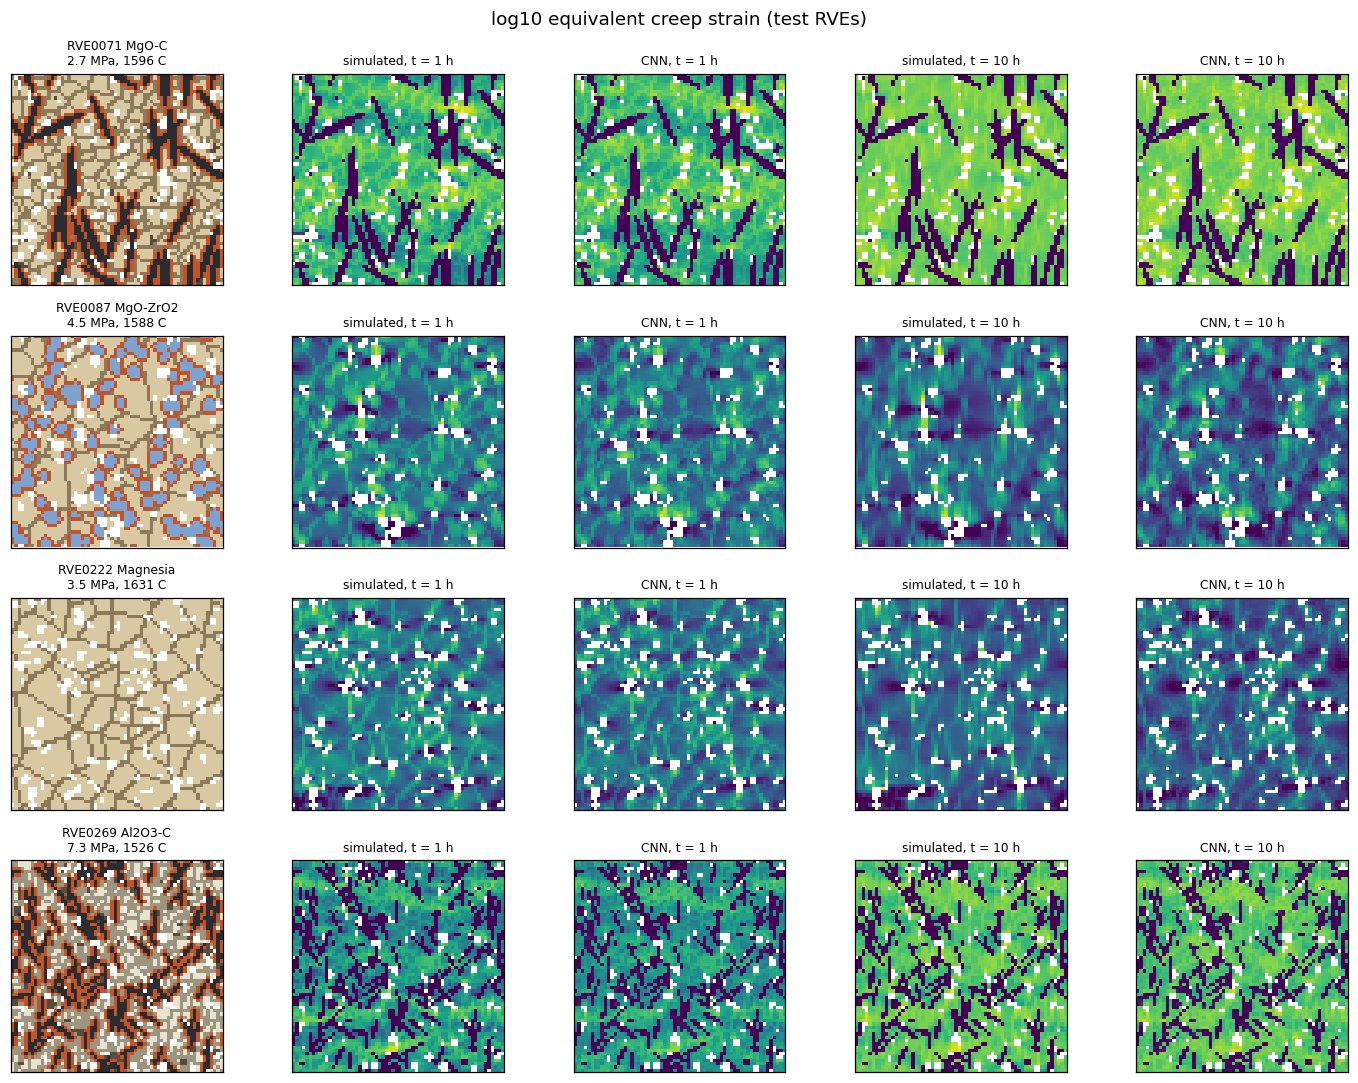

In [38]:
Xr, Yr, Mr, Gr, LVr = creep_samples(PH, CEEQ, df, CTIMES)
jtr, jva, jte = np.isin(Gr, tr_r), np.isin(Gr, va_r), np.isin(Gr, te_r)
# standardise the log-strain target with training statistics (pores excluded) for a well-conditioned start
mu_r = float(Yr[jtr][Mr[jtr] > 0].mean()); sd_r = float(Yr[jtr][Mr[jtr] > 0].std())
YMr = np.concatenate([(Yr - mu_r) / sd_r, Mr], -1)
print(f"log10 creep strain: training mean {mu_r:.2f}, std {sd_r:.2f}")
keras.utils.set_random_seed(CONFIG["SEED"] + 1)
cnn_creep = build_unet(Xr.shape[-1], None, base=CONFIG["CNN_BASE_FILTERS"], N=CONFIG["N_PIXELS"])
path_creep = os.path.join(W, "models", "cnn_creep.keras")
if CONFIG["TRAIN_CNN"] or not os.path.exists(path_creep):
    cnn_creep.compile(optimizer=keras.optimizers.Adam(2e-3), loss=masked_mse)
    cb = [keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True), keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)]
    t0 = time.time()
    hist_r = cnn_creep.fit(AugSeq(Xr[jtr], YMr[jtr], batch=16, seed=2), validation_data=(Xr[jva], YMr[jva]),
                           epochs=CONFIG["CNN_EPOCHS"], verbose=2, callbacks=cb)
    print(f"training time {time.time() - t0:.0f} s")
    cnn_creep.save(path_creep); json.dump(hist_r.history, open(path_creep + ".history.json", "w"))
    json.dump({"mu": mu_r, "sd": sd_r}, open(path_creep + ".scaling.json", "w"))
else:
    cnn_creep.load_weights(path_creep)          # load only the trained weights (works with your Keras version)
    print("loaded trained weights:", path_creep)
P_r = cnn_creep.predict(Xr[jte], batch_size=32, verbose=0) * sd_r + mu_r
prior_r = np.zeros((len(CTIMES), N_PHASES))
for k in range(len(CTIMES)):
    sel = jtr & (LVr == k)
    for c in range(1, N_PHASES):
        mm = PH[Gr[sel]] == c
        prior_r[k, c] = Yr[sel][..., 0][mm].mean() if mm.any() else np.log10(CEEQ_FLOOR)
P_rp = np.array([prior_r[LVr[i], PH[Gr[i]]] for i in np.where(jte)[0]])[..., None]
mk_r = Mr[jte] > 0
def r2m(P): return r2_score(Yr[jte][mk_r], P[mk_r])
mean_t = [np.mean(Yr[jte][i][mk_r[i]]) for i in range(mk_r.shape[0])]
mean_p = [np.mean(P_r[i][mk_r[i]]) for i in range(mk_r.shape[0])]
tab = pd.DataFrame({"pixel R2 (log strain)": [r2m(P_r), r2m(P_rp)],
                    "pixel MAE [dex]": [np.abs(Yr[jte] - P_r)[mk_r].mean(), np.abs(Yr[jte] - P_rp)[mk_r].mean()]}, index=["CNN", "pixel prior"])
display(tab.round(3))
print(f"RVE-mean log creep strain: R2 = {r2_score(mean_t, mean_p):.3f}")
check("CNN creep: pixel R2 beats the pixel prior", r2m(P_r) > r2m(P_rp), f"{r2m(P_r):.2f} vs {r2m(P_rp):.2f}")
fig, axes = plt.subplots(4, 5, figsize=(13, 10))
for r_, i in enumerate(show):
    show_phase(axes[r_, 0], PH[i], f"{df.rve_id[i]} {FAMILY_LABEL[df.family[i]]}\n{df.creep_stress[i]:.1f} MPa, {df.creep_T[i]:.0f} C")
    for c_, k in enumerate([0, 2]):
        j = np.where((Gr == i) & (LVr == k))[0][0]
        pj = cnn_creep.predict(Xr[j:j + 1], verbose=0)[0, ..., 0] * sd_r + mu_r
        m_ = Mr[j, ..., 0] > 0
        vmin, vmax = np.percentile(Yr[j][m_], 2), Yr[j][m_].max()
        for off, img, lab in [(0, Yr[j, ..., 0], "simulated"), (1, pj, "CNN")]:
            a = axes[r_, 1 + 2 * c_ + off]
            im = a.imshow(np.ma.masked_where(~m_, img), cmap="viridis", vmin=vmin, vmax=vmax, origin="lower", interpolation="nearest")
            a.set_title(f"{lab}, t = {CTIMES[k] / 3600:.0f} h", fontsize=8); a.set_xticks([]); a.set_yticks([])
plt.suptitle("log10 equivalent creep strain (test RVEs)"); plt.tight_layout()
plt.savefig(os.path.join(FIG, "cnn_creep_predictions.png"), dpi=150); plt.show()

## 10. Shared-encoder dual-head CNN (crack + creep)
One encoder learns the spatial features of the microstructure; two decoders use them:

* **crack head** — segmentation-style output (sigmoid damage map), conditioned on ΔT, weighted cross-entropy;
* **creep head** — regression output (standardised log₁₀ creep strain), conditioned on stress, temperature and time,
  masked MSE.

The targets are normalised separately (damage ∈ [0, 1]; log strain standardised with training statistics), and the two
losses are **balanced by their initial magnitudes** (weight = 1 / initial loss, so both start at 1). Every training item
is one RVE with a random ΔT level and a random creep time; shifts and mirrors are applied identically to the image and
both targets. The **test set consists of whole RVEs never seen in training** (same split as sections 8–9), so no
neighbouring pixels of a training simulation leak into the evaluation.

In [40]:
OHd, DAMd, LCEd, MASKd, CCK, CCR, mu_d, sd_d = dual_arrays(PH, DAM, CEEQ, df, LEVELS, CTIMES, train_ids=tr_r)
DD = DualData(OHd, DAMd, LCEd, MASKd, CCK, CCR)
# fixed validation set: every validation RVE at every dT level, creep time cycling through the snapshots
v_ids = np.repeat(va_r, len(LEVELS)); v_k = np.tile(np.arange(len(LEVELS)), len(va_r)); v_m = v_k % len(CTIMES)
Xv, Yv = dual_batch(DD, v_ids, v_k, v_m)
keras.utils.set_random_seed(CONFIG["SEED"] + 2)
dual = build_dual_unet(OHd.shape[-1], CCK.shape[1], CCR.shape[2], base=CONFIG["CNN_BASE_FILTERS"], N=CONFIG["N_PIXELS"])
print("dual-head parameters:", dual.count_params())
x0, y0 = dual_batch(DD, tr_r[:16], np.zeros(16, int), np.zeros(16, int))
o0 = dual(x0, training=False)
# checks of the architecture: periodic equivariance of both heads, independence of the heads' conditions
x1 = {k: v.copy() for k, v in x0.items()}; x1["micro"] = np.roll(np.roll(x0["micro"], 8, 1), 24, 2)
o1 = dual(x1, training=False)
eq = max(float(np.abs(np.roll(np.roll(o0[i].numpy(), 8, 1), 24, 2) - o1[i].numpy()).max()) for i in range(2))
x2 = {k: v.copy() for k, v in x0.items()}; x2["cond_creep"] = x2["cond_creep"] * 0 + 0.7
indep = float(np.abs(dual(x2, training=False)[0].numpy() - o0[0].numpy()).max())
check("Dual CNN: both heads translation-equivariant; crack head independent of creep conditions", eq < 1e-5 and indep < 1e-6,
      f"{eq:.1e} / {indep:.1e}")
loss_ck, loss_cr = masked_bce_weighted(4.0), masked_mse
L0c = float(loss_ck(tf.constant(y0["crack"]), o0[0])); L0r = float(loss_cr(tf.constant(y0["creep"]), o0[1]))
W_CK, W_CR = 1.0 / L0c, 1.0 / L0r
print(f"initial losses: crack {L0c:.3f}, creep {L0r:.3f} -> loss weights {W_CK:.3f}, {W_CR:.3f}")
path_dual = os.path.join(W, "models", "cnn_dual.keras")
if CONFIG["TRAIN_CNN"] or not os.path.exists(path_dual):
    dual.compile(optimizer=keras.optimizers.Adam(2e-3), loss={"crack": loss_ck, "creep": loss_cr},
                 loss_weights={"crack": W_CK, "creep": W_CR})
    cb = [keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True), keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4)]
    t0 = time.time()
    hist_d = dual.fit(DualSeq(OHd, DAMd, LCEd, MASKd, CCK, CCR, tr_r, batch=16, repeats=4, seed=5),
                      validation_data=(Xv, Yv), epochs=CONFIG["DUAL_EPOCHS"], verbose=2, callbacks=cb)
    print(f"training time {time.time() - t0:.0f} s")
    dual.save(path_dual); json.dump(hist_d.history, open(path_dual + ".history.json", "w"))
    json.dump({"mu": mu_d, "sd": sd_d, "w_crack": W_CK, "w_creep": W_CR}, open(path_dual + ".scaling.json", "w"))
else:
    dual.load_weights(path_dual)                # load only the trained weights (works with your Keras version)
    print("loaded trained weights:", path_dual)

dual-head parameters: 989298
PASS  Dual CNN: both heads translation-equivariant; crack head independent of creep conditions   [0.0e+00 / 0.0e+00]
initial losses: crack 0.680, creep 1.046 -> loss weights 1.470, 0.956
loaded trained weights: MR_RVE_work/models/cnn_dual.keras


IoU                    F1             cracked_fraction_R2  \
model dual-head single-task dual-head single-task           dual-head   
dT                                                                      
10.0      0.308       0.365     0.453       0.512               0.308   
25.0      0.395       0.428     0.557       0.592               0.289   
50.0      0.418       0.434     0.583       0.601               0.215   
100.0     0.414       0.423     0.579       0.590              -1.009   
200.0     0.473       0.476     0.633       0.637               0.265   

                   
model single-task  
dT                 
10.0        0.357  
25.0        0.509  
50.0        0.406  
100.0      -0.347  
200.0       0.262

,pixel_R2,MAE_dex,RVE_mean_R2
t_h,,,
1.0,0.961,0.128,0.988
3.0,0.974,0.114,0.990
10.0,0.983,0.105,0.990


mean test IoU: dual-head 0.401 vs single-task 0.425; creep pixel R2 dual-head 0.973 vs single-task 0.974
PASS  Dual CNN: crack IoU beats pixel prior and creep R2 beats pixel prior (test RVEs)   [IoU 0.40, creep R2 0.97]


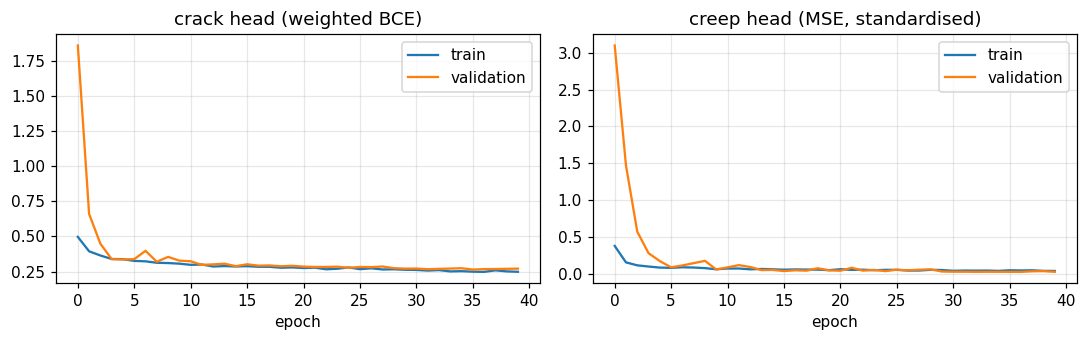

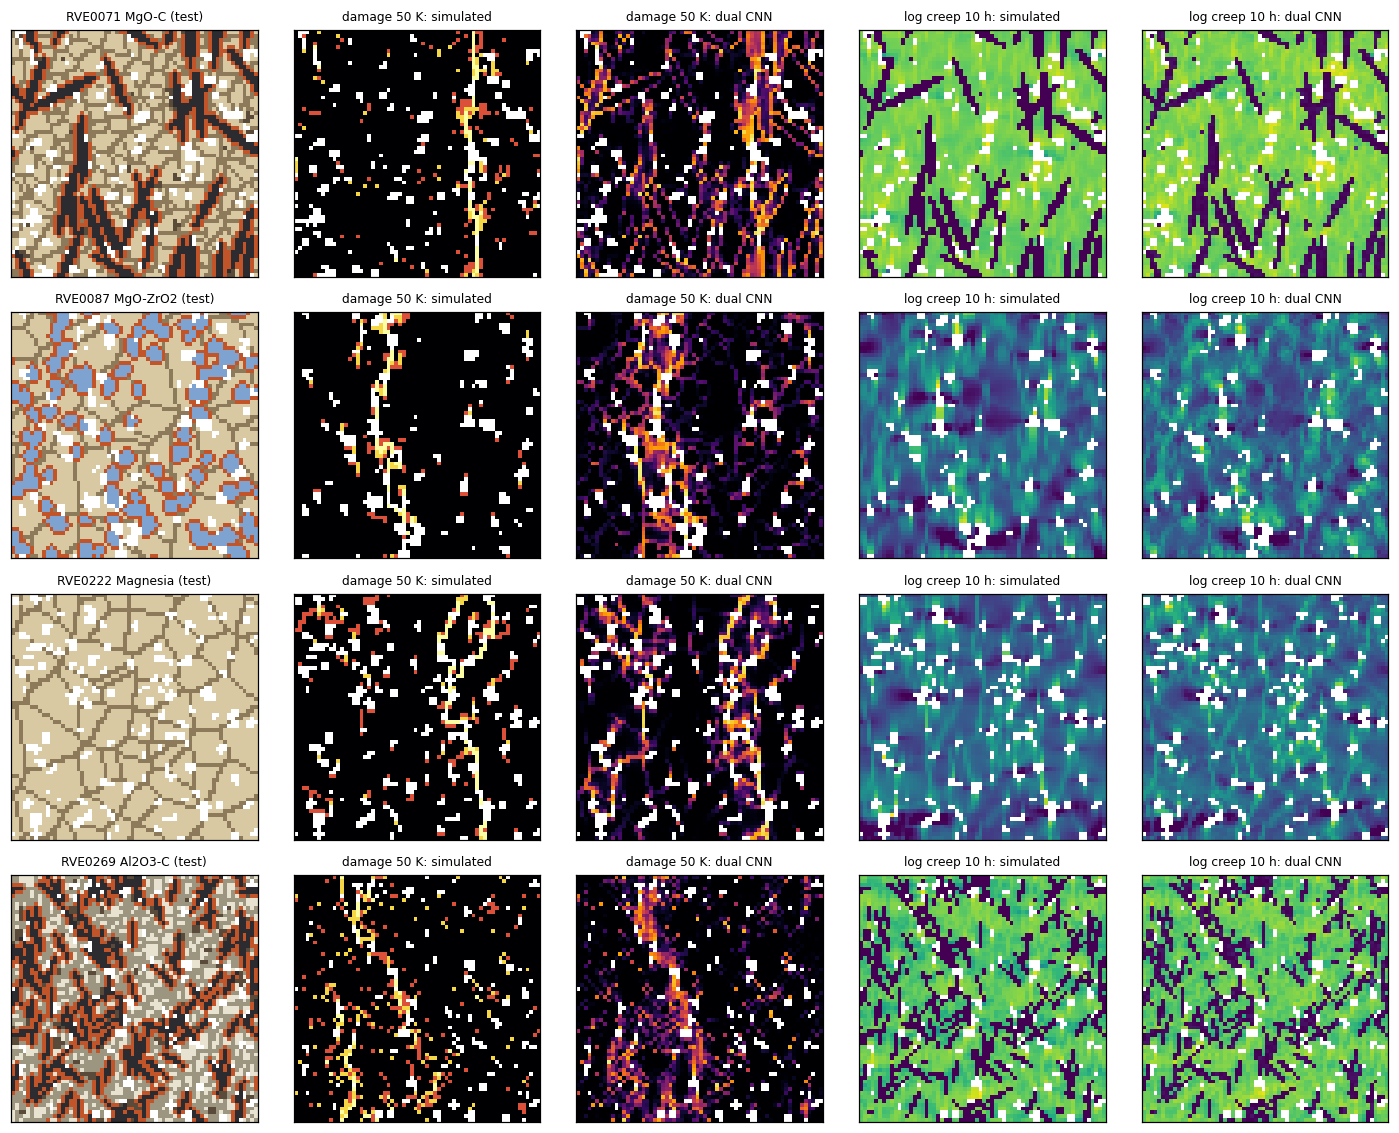

In [41]:
def dual_predict(model, ids, src, k, m):
    x, _ = dual_batch(src, np.asarray(ids), np.full(len(ids), k), np.full(len(ids), m))
    pc, pr = model.predict(x, batch_size=32, verbose=0)
    return pc[..., 0], pr[..., 0] * sd_d + mu_d                       # damage, log10 creep strain

rows = []
for k, lv in enumerate(LEVELS):                                      # crack head, test RVEs, every dT level
    pc, _ = dual_predict(dual, te_r, DD, k, 0)
    yt = np.clip(DAM[te_r, k], 0, 1); mk = PH[te_r] != 0
    sel = ite & (LVc == k)
    ps = P_c[np.where(sel[ite])[0]][..., 0]                          # single-task CNN predictions (section 8)
    yt_s = Yc[sel][..., 0]; mk_s = Mc[sel][..., 0]
    for name, yy, pp, mm in [("dual-head", yt, pc, mk), ("single-task", yt_s, ps, mk_s)]:
        per = [seg_metrics(yy[i], pp[i], mm[i]) for i in range(len(yy))]
        fr_t = [(yy[i][mm[i] > 0] >= 0.5).mean() for i in range(len(yy))]
        fr_p = [(pp[i][mm[i] > 0] >= 0.5).mean() for i in range(len(yy))]
        rows.append(dict(model=name, dT=lv, IoU=np.mean([q["IoU"] for q in per]), F1=np.mean([q["F1"] for q in per]),
                         precision=np.mean([q["precision"] for q in per]), recall=np.mean([q["recall"] for q in per]),
                         cracked_fraction_R2=r2_score(fr_t, fr_p)))
seg_tab = pd.DataFrame(rows)
display(seg_tab.pivot(index="dT", columns="model", values=["IoU", "F1", "cracked_fraction_R2"]).round(3))
rows = []
for m_ in range(len(CTIMES)):                                        # creep head, test RVEs, every time
    _, pr = dual_predict(dual, te_r, DD, 0, m_)
    yt = np.log10(CEEQ[te_r, m_] + CEEQ_FLOOR); mk = PH[te_r] != 0
    rows.append(dict(t_h=CTIMES[m_] / 3600, pixel_R2=r2_score(yt[mk], pr[mk]), MAE_dex=np.abs(yt - pr)[mk].mean(),
                     RVE_mean_R2=r2_score([yt[i][mk[i]].mean() for i in range(len(te_r))], [pr[i][mk[i]].mean() for i in range(len(te_r))])))
cr_tab = pd.DataFrame(rows).set_index("t_h"); display(cr_tab.round(3))
iou_dual = seg_tab[seg_tab.model == "dual-head"].IoU.mean(); iou_single = seg_tab[seg_tab.model == "single-task"].IoU.mean()
r2_dual = cr_tab.pixel_R2.mean()
print(f"mean test IoU: dual-head {iou_dual:.3f} vs single-task {iou_single:.3f}; creep pixel R2 dual-head {r2_dual:.3f} vs single-task {r2m(P_r):.3f}")
check("Dual CNN: crack IoU beats pixel prior and creep R2 beats pixel prior (test RVEs)", iou_dual > iou_pr and r2_dual > r2m(P_rp),
      f"IoU {iou_dual:.2f}, creep R2 {r2_dual:.2f}")
hd = json.load(open(path_dual + ".history.json"))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, key, lab in [(ax[0], "crack_loss", "crack head (weighted BCE)"), (ax[1], "creep_loss", "creep head (MSE, standardised)")]:
    a.plot(hd[key], label="train"); a.plot(hd["val_" + key], label="validation"); a.set_title(lab); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG, "cnn_dual_history.png"), dpi=150); plt.show()
fig, axes = plt.subplots(4, 5, figsize=(13, 10.4))
for r_, i in enumerate(show):
    show_phase(axes[r_, 0], PH[i], f"{df.rve_id[i]} {FAMILY_LABEL[df.family[i]]} (test)")
    pc, pr = dual_predict(dual, [i], DD, 2, 2)
    mk = PH[i] != 0
    for c_, (img, lab, cm_, vr) in enumerate([(np.clip(DAM[i, 2], 0, 1), "damage 50 K: simulated", "inferno", (0, 1)),
                                              (pc[0], "damage 50 K: dual CNN", "inferno", (0, 1)),
                                              (np.log10(CEEQ[i, 2] + CEEQ_FLOOR), "log creep 10 h: simulated", "viridis", None),
                                              (pr[0], "log creep 10 h: dual CNN", "viridis", None)]):
        a = axes[r_, c_ + 1]
        if vr is None:
            ref = np.log10(CEEQ[i, 2] + CEEQ_FLOOR)[mk]; vr = (np.percentile(ref, 2), ref.max())
        a.imshow(np.ma.masked_where(~mk, img), cmap=cm_, vmin=vr[0], vmax=vr[1], origin="lower", interpolation="nearest")
        a.set_title(lab, fontsize=8); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(os.path.join(FIG, "cnn_dual_predictions.png"), dpi=150); plt.show()

## 11. Kanapy realizations of the ranked candidates and material-level comparison
The candidates ranked by MaterialRanger are represented as nominal grades (MgO–C 15 % C, MgO–C 20 % C, MgO–ZrO₂,
magnesia 97, Al₂O₃–C). For each grade, **statistically distinct realizations** are generated with **Kanapy**:
log-normal grain-size statistics, packed ellipsoidal grains, and different seeds, so the grain arrangement, the sampled
grain sizes and the placement of flakes/particles/pores differ. The packed ellipsoids are voxelised on a periodic
mid-plane slice (Kanapy's own voxel output was not periodic across the faces in our version). All realizations
see the same loads (thermal shock at 10–200 K; creep at 5 MPa, 1550 °C).

This is a demanding test for the surrogates: the networks were trained on Voronoi-based RVEs, the Kanapy RVEs come
from a different generator.

Kanapy available: False | 50 realizations: {'MgO-C 15% C': 10, 'MgO-C 20% C': 10, 'MgO-ZrO2': 10, 'Magnesia 97': 10, 'Al2O3-C': 10}
cached: 50 / 50
50 Kanapy realizations loaded: {'Al2O3-C': 10, 'Magnesia 97': 10, 'MgO-C 15% C': 10, 'MgO-C 20% C': 10, 'MgO-ZrO2': 10}


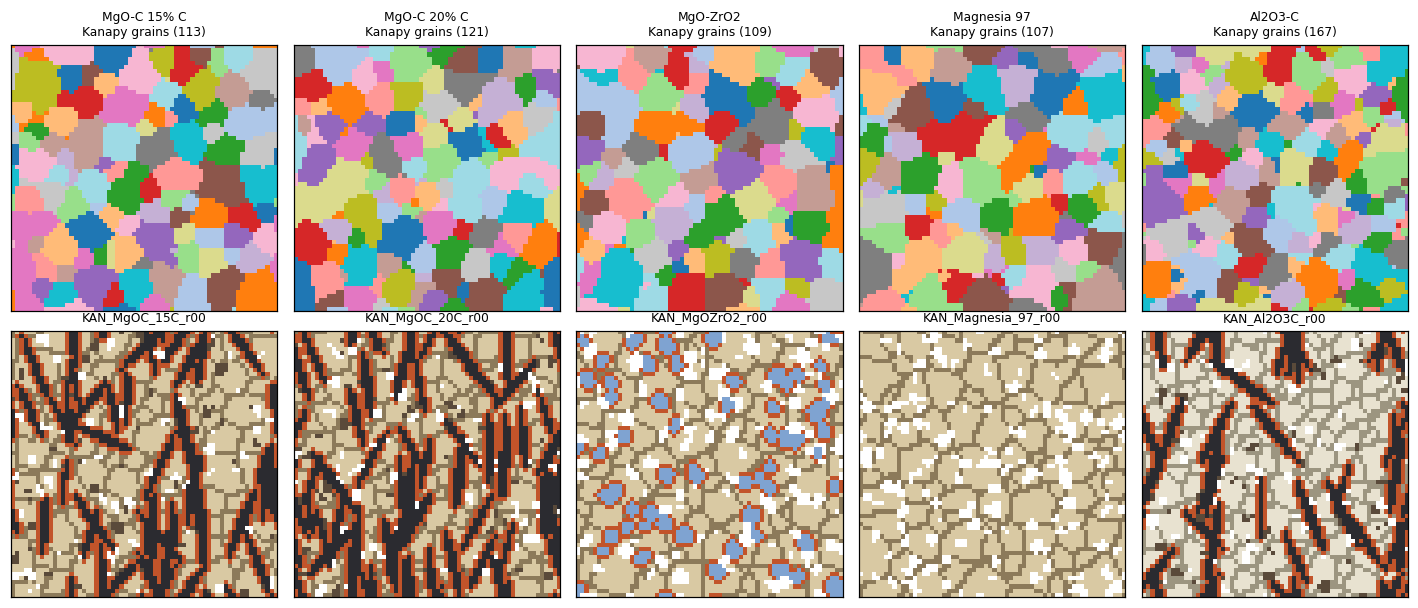

PASS  Kanapy realizations: all values finite
PASS  Abaqus: Kanapy-realization decks pass the validator   [20 decks]


In [43]:
RANKED_DIR = os.path.join(W, "ranked")
rdesign = build_ranked_design(CONFIG["N_REAL_PER_GRADE"], N=CONFIG["N_PIXELS"], L_mm=CONFIG["L_MM"])
json.dump(rdesign, open(os.path.join(W, "ranked_design.json"), "w"))
print("Kanapy available:", KANAPY_OK, "|", len(rdesign), "realizations:", {g: CONFIG["N_REAL_PER_GRADE"] for g in RANKED})
if KANAPY_OK:
    try:                                        # tested with kanapy 6.5.4; other versions may differ in API details
        parts_, box_ = pack_kanapy(130.0, 1000.0 * CONFIG["L_MM"], CONFIG["N_PIXELS"], seed=11)
        g_ = periodic_slice_grains(parts_, box_, CONFIG["N_PIXELS"])
        rot_err = check_rotation_convention(parts_)
        inside = np.mean([(g_[i] == g_[i + 1]).mean() for i in range(g_.shape[0] - 1)])
        across = 0.5 * ((g_[0] == g_[-1]).mean() + (g_[:, 0] == g_[:, -1]).mean())
        check("Kanapy: ellipsoid rotation convention (surface points at distance 1)", rot_err < 1e-9, f"{rot_err:.1e}")
        check("Kanapy slice: periodic (grain continuity across faces ~ interior)", 0.75 < across / inside < 1.3, f"{across:.2f} vs {inside:.2f}")
    except Exception as ex:
        print("Kanapy self-test skipped (installed version differs from 6.5.4):", repr(ex)[:200])
missing = [e for e in rdesign if not os.path.exists(os.path.join(RANKED_DIR, e["rve_id"] + ".npz"))]
print(f"cached: {len(rdesign) - len(missing)} / {len(rdesign)}")
if missing and CONFIG["RUN_KANAPY"] and KANAPY_OK:
    from joblib import Parallel, delayed
    t0 = time.time()
    Parallel(n_jobs=CONFIG["N_JOBS"])(delayed(simulate_rve)(e, RANKED_DIR) for e in missing)
    print(f"simulated {len(missing)} realizations in {time.time() - t0:.0f} s")
dfk, PHk, DAMk, CEk, _, _ = load_sim_results(RANKED_DIR)
print(len(dfk), "Kanapy realizations loaded:", dfk.grade.value_counts().to_dict())
fig, axes = plt.subplots(2, len(RANKED), figsize=(13, 5.6))
for c_, g in enumerate(RANKED):
    sub = np.where(dfk.grade.values == g)[0]
    if len(sub) == 0:
        continue
    zk = np.load(os.path.join(RANKED_DIR, dfk.rve_id[sub[0]] + ".npz"))
    axes[0, c_].imshow(zk["grains"] % 20, cmap="tab20", origin="lower", interpolation="nearest")
    axes[0, c_].set_title(f"{g}\nKanapy grains ({len(np.unique(zk['grains']))})", fontsize=8); axes[0, c_].set_xticks([]); axes[0, c_].set_yticks([])
    show_phase(axes[1, c_], PHk[sub[0]], f"{dfk.rve_id[sub[0]]}")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "kanapy_ranked_gallery.png"), dpi=150); plt.show()
check("Kanapy realizations: all values finite", np.isfinite(DAMk).all() and np.isfinite(CEk).all() and len(dfk) > 0)
# Abaqus decks for the first realizations of every grade (copied to the CIP folder with the others)
kdecks = []
for g in RANKED:
    for e in [d for d in rdesign if d["grade"] == g][:CONFIG["KANAPY_DECKS_PER_GRADE"]]:
        f_ = os.path.join(RANKED_DIR, e["rve_id"] + ".npz")
        if not os.path.exists(f_):
            continue
        ph_ = np.load(f_)["phase"]; mesh_ = PixelMesh(ph_, L=e["L_mm"]); mats_ = rve_materials(e["family"], e["params"])
        write_thermal_shock_deck(os.path.join(DECKS, f"TS_{e['rve_id']}.inp"), mesh_, mats_, PHASES, DT_LEVELS, e["rve_id"])
        write_creep_deck(os.path.join(DECKS, f"CR_{e['rve_id']}.inp"), mesh_, mats_, PHASES, -e["load"]["creep_stress"],
                         arrhenius(e["load"]["creep_T"]), CREEP_T_END, CREEP_SNAPS, e["rve_id"])
        kdecks += [f"TS_{e['rve_id']}.inp", f"CR_{e['rve_id']}.inp"]
okk = all(validate_deck(os.path.join(DECKS, f))[0] for f in kdecks)
check("Abaqus: Kanapy-realization decks pass the validator", okk, f"{len(kdecks)} decks")

In [44]:
# surrogate predictions for the Kanapy realizations
#   ANN : trained on ALL Voronoi RVEs (descriptors computed the same way for the Kanapy RVEs)
#   CNN : dual-head network from section 10
sx_all, sy_all = StandardScaler().fit(Xd), StandardScaler().fit(Yt)
keras.utils.set_random_seed(7)
ann_all = build_ann(Xd.shape[1], Yt.shape[1])
ann_all.fit(sx_all.transform(Xd), sy_all.transform(Yt), validation_split=0.15, epochs=400, batch_size=32, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True)])
Xk = dfk[DESC_COLS].values.astype(np.float32)
Pk_ann = sy_all.inverse_transform(ann_all.predict(sx_all.transform(Xk), verbose=0))
OHk, DAMk_, LCEk, MASKk, CCKk, CCRk, _, _ = dual_arrays(PHk, DAMk, CEk, dfk, LEVELS, CTIMES, mu=mu_d, sd=sd_d)
DK = DualData(OHk, DAMk_, LCEk, MASKk, CCKk, CCRk)
ids_k = np.arange(len(dfk))
crack_pred = np.stack([dual_predict(dual, ids_k, DK, k, 0)[0] for k in range(len(LEVELS))], 1)        # (n, levels, N, N)
creep_pred = np.stack([dual_predict(dual, ids_k, DK, 0, m_)[1] for m_ in range(len(CTIMES))], 1)       # log10 strain
mk_k = PHk != 0
seg_k = [seg_metrics(np.clip(DAMk[i, k], 0, 1), crack_pred[i, k], mk_k[i]) for i in ids_k for k in range(len(LEVELS))]
yk = np.log10(CEk + CEEQ_FLOOR)
mk3 = np.repeat(mk_k[:, None], len(CTIMES), 1)
r2_k = r2_score(yk[mk3], creep_pred[mk3])
print(f"dual CNN on Kanapy realizations (different generator): crack IoU {np.mean([q['IoU'] for q in seg_k]):.3f}, "
      f"F1 {np.mean([q['F1'] for q in seg_k]):.3f}; creep pixel R2 {r2_k:.3f}")
frac = lambda D, M: np.array([[(D[i, k][M[i]] >= 0.5).mean() for k in range(D.shape[1])] for i in range(len(D))])
fr_sim, fr_cnn = frac(np.clip(DAMk, 0, 1), mk_k), frac(crack_pred, mk_k)
mean_lc = lambda Y: np.array([[Y[i, m_][mk_k[i]].mean() for m_ in range(Y.shape[1])] for i in range(len(Y))])
lc_sim, lc_cnn = mean_lc(yk), mean_lc(creep_pred)
j25 = tnames.index("log10 E/E0 @25K"); jcr = tnames.index("log10 creep strain 10h")
mat = pd.DataFrame({"grade": dfk.grade,
                    "E/E0 25K sim": dfk.E_ratio_25, "E/E0 25K ANN": 10 ** Pk_ann[:, j25],
                    "cracked 50K sim": fr_sim[:, 2], "cracked 50K CNN": fr_cnn[:, 2],
                    "creep 10h sim": -dfk.macro_creep_10h, "creep 10h ANN": 10 ** Pk_ann[:, jcr],
                    "log creep map sim": lc_sim[:, 2], "log creep map CNN": lc_cnn[:, 2]})
agg = mat.groupby("grade").agg(["mean", "std"]).reindex(list(RANKED))
display(agg.round(4))

dual CNN on Kanapy realizations (different generator): crack IoU 0.464, F1 0.628; creep pixel R2 0.982


E/E0 25K sim         E/E0 25K ANN         cracked 50K sim          \
                    mean     std         mean     std            mean     std   
grade                                                                           
MgO-C 15% C       0.3259  0.0540       0.3333  0.0154          0.0926  0.0090   
MgO-C 20% C       0.5391  0.0896       0.4931  0.0136          0.1026  0.0115   
MgO-ZrO2          0.0909  0.0228       0.0935  0.0021          0.0797  0.0154   
Magnesia 97       0.0802  0.0275       0.0850  0.0005          0.0690  0.0203   
Al2O3-C           0.8179  0.0600       0.7077  0.0119          0.0850  0.0057   

            cracked 50K CNN         creep 10h sim      creep 10h ANN       \
                       mean     std          mean  std          mean  std   
grade                                                                       
MgO-C 15% C          0.1322  0.0268        0.0002  0.0        0.0002  0.0   
MgO-C 20% C          0.1565  0.0301        0.0001  0.0        0.0002  0.0   
MgO-ZrO2             0.0867  0.0142        0.0003  0.0        0.0003  0.0   
Magnesia 97          0.0700  0.0103        0.0003  0.0        0.0003  0.0   
Al2O3-C              0.0693  0.0107        0.0000  0.0        0.0000  0.0   

            log creep map sim         log creep map CNN          
                         mean     std              mean     std  
grade                                                            
MgO-C 15% C           -4.6580  0.0059           -4.6544  0.0062  
MgO-C 20% C           -4.8499  0.0054           -4.8162  0.0090  
MgO-ZrO2              -3.6755  0.0091           -3.7050  0.0080  
Magnesia 97           -3.7178  0.0063           -3.7591  0.0079  
Al2O3-C               -5.0179  0.0063           -4.9762  0.0107

,stiffness 25K sim,stiffness 25K ANN,creep 10h sim,creep 10h ANN,creep map sim,creep map CNN
grade,,,,,,
MgO-C 15% C,3,3,3,2,3,3
MgO-C 20% C,2,2,2,3,2,2
MgO-ZrO2,4,4,5,5,5,5
Magnesia 97,5,5,4,4,4,4
Al2O3-C,1,1,1,1,1,1


Spearman (grade ranking, simulated vs surrogate): stiffness ANN 1.00, creep ANN 0.90, creep map CNN 1.00
PASS  Material level: ANN and CNN reproduce the simulated grade ranking (stiffness, creep; Spearman >= 0.8)   [1.00 / 0.90 / 1.00]


,cracked 50K sim,CNN,tolerance
grade,,,
MgO-C 15% C,0.093,0.132,0.020
MgO-C 20% C,0.103,0.156,0.023
MgO-ZrO2,0.080,0.087,0.031
Magnesia 97,0.069,0.070,0.041
Al2O3-C,0.085,0.069,0.020


FAIL  Material level: CNN cracked area within the realization scatter for every grade   [max deviation 0.054]
Note: cracked AREA and stiffness LOSS rank the grades differently - magnesia cracks few pixels but loses most stiffness (one localised through-crack), MgO-C cracks diffusely at flake interfaces and keeps its stiffness.


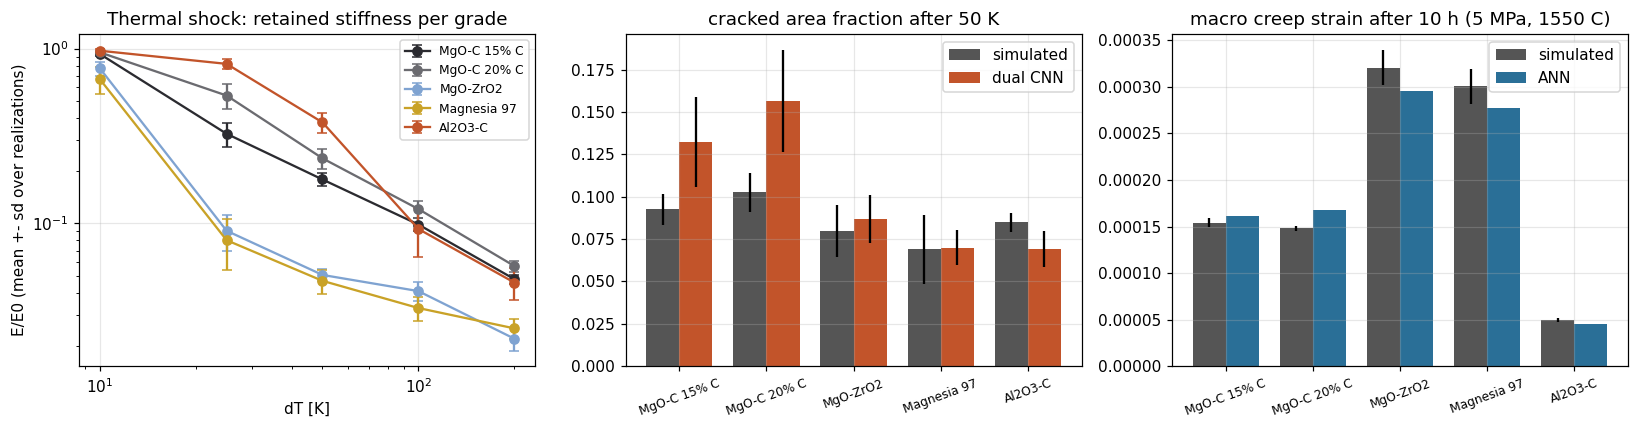

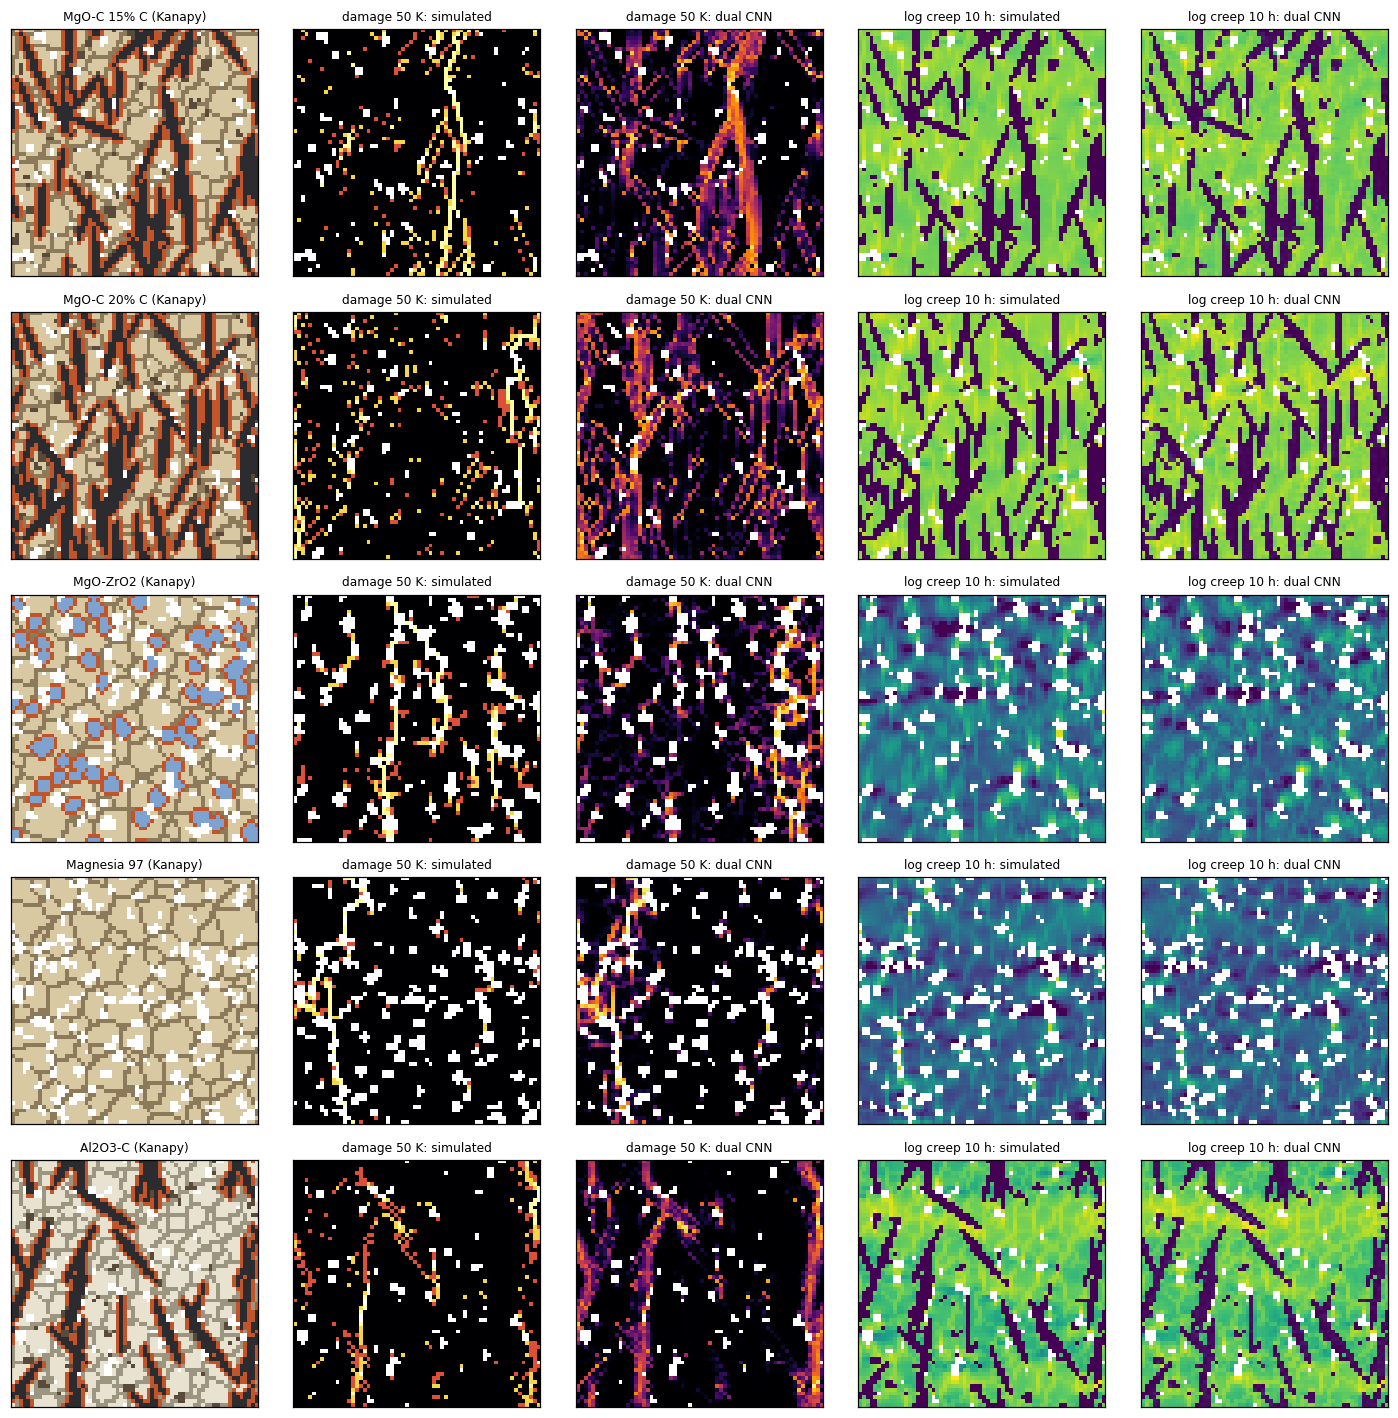

In [45]:
from scipy.stats import spearmanr
gm = mat.groupby("grade").mean().reindex(list(RANKED))
gs = mat.groupby("grade").std().reindex(list(RANKED))
rank_tab = pd.DataFrame({
    "stiffness 25K sim": gm["E/E0 25K sim"].rank(ascending=False).astype(int),
    "stiffness 25K ANN": gm["E/E0 25K ANN"].rank(ascending=False).astype(int),
    "creep 10h sim": gm["creep 10h sim"].rank().astype(int),
    "creep 10h ANN": gm["creep 10h ANN"].rank().astype(int),
    "creep map sim": gm["log creep map sim"].rank().astype(int),
    "creep map CNN": gm["log creep map CNN"].rank().astype(int)})
display(rank_tab)
rho_ts = spearmanr(gm["E/E0 25K sim"], gm["E/E0 25K ANN"]).correlation
rho_cr = spearmanr(gm["creep 10h sim"], gm["creep 10h ANN"]).correlation
rho_cm = spearmanr(gm["log creep map sim"], gm["log creep map CNN"]).correlation
print(f"Spearman (grade ranking, simulated vs surrogate): stiffness ANN {rho_ts:.2f}, creep ANN {rho_cr:.2f}, creep map CNN {rho_cm:.2f}")
check("Material level: ANN and CNN reproduce the simulated grade ranking (stiffness, creep; Spearman >= 0.8)",
      min(rho_ts, rho_cr, rho_cm) >= 0.8, f"{rho_ts:.2f} / {rho_cr:.2f} / {rho_cm:.2f}")
tol = np.maximum(0.02, 2 * gs["cracked 50K sim"])
dev = (gm["cracked 50K CNN"] - gm["cracked 50K sim"]).abs()
display(pd.DataFrame({"cracked 50K sim": gm["cracked 50K sim"], "CNN": gm["cracked 50K CNN"], "tolerance": tol}).round(3))
check("Material level: CNN cracked area within the realization scatter for every grade", (dev <= tol).all(),
      f"max deviation {dev.max():.3f}")
print("Note: cracked AREA and stiffness LOSS rank the grades differently - magnesia cracks few pixels but loses most "
      "stiffness (one localised through-crack), MgO-C cracks diffusely at flake interfaces and keeps its stiffness.")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
gcol = dict(zip(RANKED, ["#2b2b30", "#6b6b70", "#7fa3d1", "#c9a227", "#c2542a"]))
for g in RANKED:
    sub = dfk[dfk.grade == g]
    if len(sub) == 0:
        continue
    E = np.array([sub[f"E_ratio_{int(l)}"] for l in LEVELS])
    ax[0].errorbar(LEVELS, E.mean(1), yerr=E.std(1), fmt="o-", color=gcol[g], label=g, capsize=3)
idx = np.arange(len(RANKED)); w_ = 0.38
ax[1].bar(idx - w_ / 2, gm["cracked 50K sim"], w_, yerr=mat.groupby("grade")["cracked 50K sim"].std().reindex(list(RANKED)), label="simulated", color="#555")
ax[1].bar(idx + w_ / 2, gm["cracked 50K CNN"], w_, yerr=mat.groupby("grade")["cracked 50K CNN"].std().reindex(list(RANKED)), label="dual CNN", color="#c2542a")
ax[2].bar(idx - w_ / 2, gm["creep 10h sim"], w_, yerr=mat.groupby("grade")["creep 10h sim"].std().reindex(list(RANKED)), label="simulated", color="#555")
ax[2].bar(idx + w_ / 2, gm["creep 10h ANN"], w_, label="ANN", color="#2a6f97")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("dT [K]"); ax[0].set_ylabel("E/E0 (mean +- sd over realizations)"); ax[0].legend(fontsize=8)
ax[0].set_title("Thermal shock: retained stiffness per grade")
for a, t_ in [(ax[1], "cracked area fraction after 50 K"), (ax[2], "macro creep strain after 10 h (5 MPa, 1550 C)")]:
    a.set_xticks(idx); a.set_xticklabels(list(RANKED), rotation=20, fontsize=8); a.set_title(t_); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG, "material_level_comparison.png"), dpi=150); plt.show()
fig, axes = plt.subplots(len(RANKED), 5, figsize=(13, 13))
for r_, g in enumerate(RANKED):
    sub = np.where(dfk.grade.values == g)[0]
    if len(sub) == 0:
        continue
    i = sub[0]; mk = mk_k[i]
    show_phase(axes[r_, 0], PHk[i], f"{g} (Kanapy)")
    ref = yk[i, 2][mk]
    for c_, (img, lab, cm_, vr) in enumerate([(np.clip(DAMk[i, 2], 0, 1), "damage 50 K: simulated", "inferno", (0, 1)),
                                              (crack_pred[i, 2], "damage 50 K: dual CNN", "inferno", (0, 1)),
                                              (yk[i, 2], "log creep 10 h: simulated", "viridis", (np.percentile(ref, 2), ref.max())),
                                              (creep_pred[i, 2], "log creep 10 h: dual CNN", "viridis", (np.percentile(ref, 2), ref.max()))]):
        a = axes[r_, c_ + 1]
        a.imshow(np.ma.masked_where(~mk, img), cmap=cm_, vmin=vr[0], vmax=vr[1], origin="lower", interpolation="nearest")
        a.set_title(lab, fontsize=8); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(os.path.join(FIG, "material_level_maps.png"), dpi=150); plt.show()

## 12. Abaqus results: Python vs Abaqus, CNN vs Abaqus, transfer learning
*This notebook was executed before the Abaqus results came back from the CIP machines, so the cells below find no results. The Abaqus comparison is in the calibrated notebook (section 12.1b) and in the paper.*

When the `*_results.npz` files from the CIP machine are in `ABAQUS_RESULTS_DIR`, this section
(i) compares Abaqus and the Python reference solver RVE by RVE (elastic modulus, crack onset, damage maps, residual
stiffness, creep-strain maps, macro creep strain); (ii) compares the **dual-head CNN predictions with Abaqus** using
crack-map metrics (IoU, F1) and creep-field errors (R², MAE); (iii) fine-tunes the crack CNN on Abaqus maps (transfer
learning: Python = low-fidelity pre-training, Abaqus = high fidelity). It works for the Voronoi RVEs and for the
Kanapy realizations. The reader is first tested on synthetic files in the exact layout written by `extract_odb.py`.

In [47]:
from abaqus_results import read_ts, read_cr
D_ = os.path.join(W, "abaqus_decks")
a_h = read_ts(os.path.join(D_, "SMOKE_TS_HOMOG_results.npz"), 16, LEVELS, np.arange(16 * 16))
print("HOMOG  Abaqus crack onset dT = %.2f K   (analytic 19.75 K)" % a_h["dT_onset"])
print("HOMOG  E0 = %.0f MPa, E/E0 after shock = %.3f, dT reached = %.0f K" % (a_h["E0"], a_h["E_ratio_end"], a_h["dT_reached"]))
a_r = read_ts(os.path.join(D_, "SMOKE_TS_RVE_results.npz"), 32, LEVELS, np.arange(32 * 32))
print("RVE32  onset dT = %.2f K, E/E0 after shock = %.3f, completed = %s" % (a_r["dT_onset"], a_r["E_ratio_end"], a_r["completed"]))
c_r = read_cr(os.path.join(D_, "SMOKE_CR_RVE_results.npz"), 32, CTIMES, np.arange(32 * 32))
print("CR32   macro creep strain at 1/3/10 h:", np.round(c_r["macro_creep"], 6), " max time reached:", c_r["t_reached"])

HOMOG  Abaqus crack onset dT = 18.04 K   (analytic 19.75 K)
HOMOG  E0 = 300000 MPa, E/E0 after shock = -0.038, dT reached = 200 K
RVE32  onset dT = 3.86 K, E/E0 after shock = -0.262, completed = True
CR32   macro creep strain at 1/3/10 h: [-3.8e-05 -8.8e-05 -2.2e-04]  max time reached: 36000.0


In [46]:
tmp = os.path.join(W, "abaqus_selftest"); os.makedirs(tmp, exist_ok=True)
f0 = os.path.join(SIM, df.rve_id[0] + ".npz")
present = fake_results_from_python(f0, tmp)
z0 = np.load(f0)
a_ = read_ts(os.path.join(tmp, f"TS_{df.rve_id[0]}_results.npz"), CONFIG["N_PIXELS"], LEVELS, present)
c_ = read_cr(os.path.join(tmp, f"CR_{df.rve_id[0]}_results.npz"), CONFIG["N_PIXELS"], CTIMES, present)
ok_rt = np.array_equal(a_["damage"], z0["damage"]) and np.allclose(c_["ceeq"], z0["ceeq"]) and abs(a_["E_ratio_end"] / z0["E_ratio"][-1] - 1) < 1e-9
check("Abaqus reader: round-trip identical (crack + creep)", ok_rt)

# all simulated RVEs (Voronoi + Kanapy) by id, with the data needed for comparisons and CNN inputs
SIMREC = {}
for i in range(len(df)):
    SIMREC[df.rve_id[i]] = dict(src="voronoi", i=i, ph=PH[i], dam=DAM[i], ce=CEEQ[i], row=df.iloc[i], data=DD)
for i in range(len(dfk)):
    SIMREC[dfk.rve_id[i]] = dict(src="kanapy", i=i, ph=PHk[i], dam=DAMk[i], ce=CEk[i], row=dfk.iloc[i], data=DK)

AR = CONFIG["ABAQUS_RESULTS_DIR"]
ts_files = sorted(glob.glob(os.path.join(AR, "TS_*_results.npz")))
cr_files = sorted(glob.glob(os.path.join(AR, "CR_*_results.npz")))
print(len(ts_files), "thermal-shock and", len(cr_files), "creep results found in", AR)
abq_maps = {}
if ts_files or cr_files:
    rows = []
    for f in ts_files:
        rid = os.path.basename(f)[3:-12]
        if rid not in SIMREC:
            continue
        R_ = SIMREC[rid]; present = np.flatnonzero(R_["ph"].ravel() != 0)
        a = read_ts(f, CONFIG["N_PIXELS"], LEVELS, present)
        if not a.get("ok"):
            print("incomplete:", rid); continue
        abq_maps[rid] = a
        pc_all = np.stack([dual_predict(dual, [R_["i"]], R_["data"], k, 0)[0][0] for k in range(len(LEVELS))])
        mk = R_["ph"] != 0
        ks = [k for k in range(len(LEVELS)) if a["levels_reached"][k]]
        py_vs_abq = [seg_metrics(np.clip(R_["dam"][k], 0, 1), np.clip(a["damage"][k], 0, 1), mk) for k in ks]
        cnn_vs_abq = [seg_metrics(np.clip(a["damage"][k], 0, 1), pc_all[k], mk) for k in ks]
        rows.append(dict(rve=rid, source=R_["src"], completed=a["completed"], dT_reached=a["dT_reached"],
                         E0_python=R_["row"]["E0_eff_GPa"] * 1000, E0_abaqus=a["E0"],
                         dTc_python=R_["row"]["dTc"], dTc_abaqus=a["dT_onset"],
                         E_ratio_200_python=R_["row"]["E_ratio_200"], E_ratio_end_abaqus=a["E_ratio_end"],
                         IoU_python_vs_abaqus=np.mean([q["IoU"] for q in py_vs_abq]) if ks else np.nan,
                         IoU_CNN_vs_abaqus=np.mean([q["IoU"] for q in cnn_vs_abq]) if ks else np.nan,
                         F1_CNN_vs_abaqus=np.mean([q["F1"] for q in cnn_vs_abq]) if ks else np.nan))
    abq = pd.DataFrame(rows)
    if len(abq):
        display(abq.round(3))
        check("Abaqus vs Python: elastic modulus E0 within 1 %", ((abq.E0_abaqus / abq.E0_python - 1).abs() < 0.01).all())
        print("crack onset ratio Abaqus/Python (median):", np.nanmedian(abq.dTc_abaqus / abq.dTc_python).round(3))
    rows = []
    for f in cr_files:
        rid = os.path.basename(f)[3:-12]
        if rid not in SIMREC:
            continue
        R_ = SIMREC[rid]; present = np.flatnonzero(R_["ph"].ravel() != 0)
        c = read_cr(f, CONFIG["N_PIXELS"], CTIMES, present)
        if not c.get("ok"):
            print("incomplete:", rid); continue
        mk = R_["ph"] != 0
        ya = np.log10(np.clip(c["ceeq"], 0, None) + CEEQ_FLOOR); yp = np.log10(R_["ce"] + CEEQ_FLOOR)
        pr_all = np.stack([dual_predict(dual, [R_["i"]], R_["data"], 0, m_)[1][0] for m_ in range(len(CTIMES))])
        mk3 = np.repeat(mk[None], len(CTIMES), 0)
        rows.append(dict(rve=rid, source=R_["src"], t_reached_h=c["t_reached"] / 3600,
                         macro_creep_python=R_["row"]["macro_creep_10h"], macro_creep_abaqus=c["macro_creep"][-1],
                         R2_python_vs_abaqus=r2_score(ya[mk3], yp[mk3]), MAE_python_vs_abaqus=np.abs(ya - yp)[mk3].mean(),
                         R2_CNN_vs_abaqus=r2_score(ya[mk3], pr_all[mk3]), MAE_CNN_vs_abaqus=np.abs(ya - pr_all)[mk3].mean()))
    abq_cr = pd.DataFrame(rows)
    if len(abq_cr):
        display(abq_cr.round(4))
    # transfer learning: fine-tune the crack CNN on Abaqus damage maps (Voronoi RVEs with enough results)
    ids = np.array(sorted(SIMREC[r]["i"] for r in abq_maps if SIMREC[r]["src"] == "voronoi"))
    if len(ids) >= 12:
        rng = np.random.default_rng(0); ids = rng.permutation(ids); n_te = max(3, len(ids) // 4)
        rid_of = {SIMREC[r]["i"]: r for r in abq_maps if SIMREC[r]["src"] == "voronoi"}
        def build(idset):
            X_, Y_ = [], []
            for i in idset:
                a = abq_maps[rid_of[i]]
                for k in range(len(LEVELS)):
                    if a["levels_reached"][k]:
                        j = np.where((Gc == i) & (LVc == k))[0][0]
                        X_.append(Xc[j]); Y_.append(np.concatenate([np.clip(a["damage"][k], 0, 1)[..., None], Mc[j]], -1))
            return np.array(X_), np.array(Y_, np.float32)
        Xa_tr, Ya_tr = build(ids[n_te:]); Xa_te, Ya_te = build(ids[:n_te])
        def mean_iou(model, X_, Y_):
            P_ = model.predict(X_, verbose=0); return np.mean([iou(Y_[i, ..., :1], P_[i], Y_[i, ..., 1:]) for i in range(len(X_))])
        before = mean_iou(cnn_crack, Xa_te, Ya_te)
        ft = build_unet(Xc.shape[-1], "sigmoid", base=CONFIG["CNN_BASE_FILTERS"], N=CONFIG["N_PIXELS"])
        ft.set_weights(cnn_crack.get_weights())                 # start from the Python-trained weights
        ft.compile(optimizer=keras.optimizers.Adam(2e-4), loss=masked_bce_weighted(4.0))
        ft.fit(AugSeq(Xa_tr, Ya_tr, batch=8, seed=3), epochs=20, verbose=0)
        after = mean_iou(ft, Xa_te, Ya_te)
        print(f"crack CNN on held-out Abaqus RVEs: IoU {before:.2f} (Python-trained) -> {after:.2f} (fine-tuned)")
else:
    print("No Abaqus results yet - run the decks of sections 4 and 11 on the CIP machine, then re-run this section.")

PASS  Abaqus reader: round-trip identical (crack + creep)
0 thermal-shock and 0 creep results found in MR_RVE_work/abaqus_results
No Abaqus results yet - run the decks of sections 4 and 11 on the CIP machine, then re-run this section.


## 13. Verification summary

In [ ]:
summary = pd.DataFrame([(k, "PASS" if v[0] else "FAIL", v[1]) for k, v in CHECKS.items()], columns=["check", "result", "value"])
display(summary)
print(f"{(summary.result == 'PASS').sum()} / {len(summary)} checks passed")

### Summary
* **Data at scale:** 320 periodic RVEs × (5 thermal-shock states + 3 creep states) = 2560 simulated fields from a
  Latin-hypercube design, plus Kanapy realizations of the five ranked candidates; Abaqus decks for any subset are
  written and verified automatically (validator + rebuild-from-text check), run and extracted by tested scripts.
* **Physics:** the RVEs reproduce the Hasselman paradox. Carbon-bonded MgO–C cracks early at weak flake interfaces but keeps
  far more stiffness than dense oxides, whose cracks run through the whole cell. Hasselman scaling survives at the RVE
  scale only with FE-homogenised properties; crack onset itself is a weakest-link event.
* **Surrogates:** the ANN predicts residual stiffness and creep from descriptors; the single-task and the shared-encoder
  dual-head periodic U-Nets predict full damage and creep-strain *maps* in milliseconds; all are evaluated on whole
  held-out RVEs and on Kanapy microstructures from a different generator, and rank the five candidates like the
  simulations do. They are ready to be fine-tuned on Abaqus results (section 12).
* **Open points at this stage** (calibration and 3-D RVEs followed in the next steps): calibration of local strengths, fracture energies and creep
  parameters; CDP vs. cohesive zones vs. phase-field fracture; plane stress vs. generalised plane strain; 3-D Kanapy RVEs;
  active learning to choose the next Abaqus job from the surrogate uncertainty.